In [1]:
print("Welcome to NetGuard ML!")
print("My network intrusion detection project has started.")

Welcome to NetGuard ML!
My network intrusion detection project has started.


In [2]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Pandas version: 2.2.3
Scikit-learn version: 1.6.1


In [4]:
from pathlib import Path

# Create project folders
folders = [
    "data/raw",
    "data/processed",
    "models",
    "outputs"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [5]:
from pathlib import Path

data_folder = Path("data/raw")

print("Current working folder:", Path.cwd())
print("CSV files found:")

for file in data_folder.glob("*.csv"):
    print(file.name)

Current working folder: C:\Users\royal\NetGuard-ML
CSV files found:
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [6]:
import pandas as pd
from pathlib import Path

data_folder = Path("data/raw")
csv_files = sorted(data_folder.glob("*.csv"))

dataframes = []

for file in csv_files:
    print("Loading:", file.name)

    df_temp = pd.read_csv(
        file,
        low_memory=False,
        encoding="utf-8-sig"
    )

    # Clean spaces around column names
    df_temp.columns = df_temp.columns.str.strip()

    dataframes.append(df_temp)

data = pd.concat(dataframes, ignore_index=True)

print("\nDataset loaded successfully!")
print("Total rows:", data.shape[0])
print("Total columns:", data.shape[1])

Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Dataset loaded successfully!
Total rows: 2318531
Total columns: 79


In [7]:
print("Dataset shape:", data.shape)

print("\nFirst five rows:")
display(data.head())

print("\nColumn names:")
print(data.columns.tolist())

print("\nDataset information:")
data.info()

Dataset shape: (2318531, 79)

First five rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,3268,112740690,32,16,6448,1152,403,0,201.5,204.724205,...,32,3.594286e+02,1.199802e+01,380,343,16100000.0,4.988048e+05,16400000,15400000,BENIGN
1,389,112740560,32,16,6448,5056,403,0,201.5,204.724205,...,32,3.202857e+02,1.574499e+01,330,285,16100000.0,4.987937e+05,16400000,15400000,BENIGN
2,0,113757377,545,0,0,0,0,0,0.0,0.000000,...,0,9.361829e+06,7.324646e+06,18900000,19,12200000.0,6.935824e+06,20800000,5504997,BENIGN
3,5355,100126,22,0,616,0,28,28,28.0,0.000000,...,32,0.000000e+00,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN
4,0,54760,4,0,0,0,0,0,0.0,0.000000,...,0,0.000000e+00,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN



Column names:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 

In [8]:
label_col = next(
    (col for col in data.columns if col.lower() == "label"),
    None
)

if label_col is None:
    print("Label column not found. Check the column names.")
else:
    print("Label column:", label_col)
    display(data[label_col].value_counts().to_frame("Count"))

Label column: Label


,Count
Label,
BENIGN,2047842
DoS Hulk,231073
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499
Bot,1966
Web Attack � Brute Force,1507


In [9]:
# Find the target label column
label_col = next(
    (col for col in data.columns if col.strip().lower() == "label"),
    None
)

if label_col is None:
    print("Label column not found!")
else:
    data[label_col] = data[label_col].astype(str).str.strip()

    print("Label column:", label_col)
    print("\nTraffic distribution:")
    display(data[label_col].value_counts().to_frame("Count"))

Label column: Label

Traffic distribution:


,Count
Label,
BENIGN,2047842
DoS Hulk,231073
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499
Bot,1966
Web Attack � Brute Force,1507


In [10]:
import numpy as np

# Check missing values
print("Total missing values:", data.isna().sum().sum())

# Check duplicate rows
print("Duplicate rows:", data.duplicated().sum())

# Check infinite numeric values
numeric_data = data.select_dtypes(include=np.number)
print(
    "Infinite values:",
    np.isinf(numeric_data.to_numpy()).sum()
)

Total missing values: 1339
Duplicate rows: 219430
Infinite values: 3585


In [11]:
import numpy as np
import pandas as pd

# Keep the original dataset unchanged
clean_data = data.copy()

# Remove whitespace from column names and labels
clean_data.columns = clean_data.columns.str.strip()

label_col = "Label"

clean_data[label_col] = (
    clean_data[label_col]
    .astype(str)
    .str.strip()
)

# Replace infinite numeric values with NaN
numeric_cols = clean_data.select_dtypes(include=np.number).columns

clean_data[numeric_cols] = clean_data[numeric_cols].replace(
    [np.inf, -np.inf],
    np.nan
)

print("Working copy created!")
print("Shape:", clean_data.shape)
print("Missing values after infinity handling:",
      clean_data.isna().sum().sum())

Working copy created!
Shape: (2318531, 79)
Missing values after infinity handling: 4924


In [12]:
print("Traffic labels before duplicate removal:")

display(
    clean_data["Label"]
    .value_counts()
    .to_frame("Count")
)

print("Exact duplicate rows:",
      clean_data.duplicated().sum())

Traffic labels before duplicate removal:


,Count
Label,
BENIGN,2047842
DoS Hulk,231073
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499
Bot,1966
Web Attack � Brute Force,1507


Exact duplicate rows: 219430


In [13]:
print("Traffic labels and record counts:")

display(
    clean_data["Label"]
    .value_counts()
    .to_frame("Count")
)

Traffic labels and record counts:


,Count
Label,
BENIGN,2047842
DoS Hulk,231073
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499
Bot,1966
Web Attack � Brute Force,1507


In [14]:
label_counts = clean_data["Label"].value_counts()

label_summary = pd.DataFrame({
    "Count": label_counts,
    "Percentage": (
        label_counts / len(clean_data) * 100
    ).round(2)
})

display(label_summary)

,Count,Percentage
Label,,
BENIGN,2047842,88.32
DoS Hulk,231073,9.97
DoS GoldenEye,10293,0.44
FTP-Patator,7938,0.34
SSH-Patator,5897,0.25
DoS slowloris,5796,0.25
DoS Slowhttptest,5499,0.24
Bot,1966,0.08
Web Attack � Brute Force,1507,0.06


In [15]:
# Create binary target labels
y = (
    clean_data["Label"]
    .str.upper()
    .eq("BENIGN")
    .map({True: "BENIGN", False: "ATTACK"})
)

# Remove the original label from the feature data
X = clean_data.drop(columns=["Label"]).copy()

# Keep numeric features only
X = X.select_dtypes(include=np.number)

# Replace invalid numeric values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns with no usable values
X = X.dropna(axis=1, how="all")

print("Feature matrix shape:", X.shape)
print("Target distribution:")
display(y.value_counts().to_frame("Count"))

Feature matrix shape: (2318531, 78)
Target distribution:


,Count
Label,
BENIGN,2047842
ATTACK,270689


In [16]:
# Combine features and target to identify exact duplicates
model_data = X.copy()
model_data["target"] = y

before = len(model_data)
model_data = model_data.drop_duplicates()
removed = before - len(model_data)

y = model_data.pop("target").reset_index(drop=True)
X = model_data.reset_index(drop=True)

print("Rows before duplicate removal:", before)
print("Rows removed:", removed)
print("Rows after duplicate removal:", len(X))

print("\nUpdated class distribution:")
display(y.value_counts().to_frame("Count"))

Rows before duplicate removal: 2318531
Rows removed: 219430
Rows after duplicate removal: 2099101

Updated class distribution:


,Count
target,
BENIGN,1892058
ATTACK,207043


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training features:", X_train.shape[1])

Training records: 1679280
Testing records: 419821
Training features: 78


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
import time

start_time = time.time()

# Handle missing values and train the model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest... Please wait.")

model.fit(X_train, y_train)

print("Training completed!")
print(f"Training time: {(time.time() - start_time)/60:.2f} minutes")

Training Random Forest... Please wait.
Training completed!
Training time: 2.19 minutes


Accuracy: 0.9994
Attack precision: 0.9959
Attack recall: 0.9985
Attack F1-score: 0.9972

Detailed classification report:
              precision    recall  f1-score   support

      ATTACK       1.00      1.00      1.00     41409
      BENIGN       1.00      1.00      1.00    378412

    accuracy                           1.00    419821
   macro avg       1.00      1.00      1.00    419821
weighted avg       1.00      1.00      1.00    419821



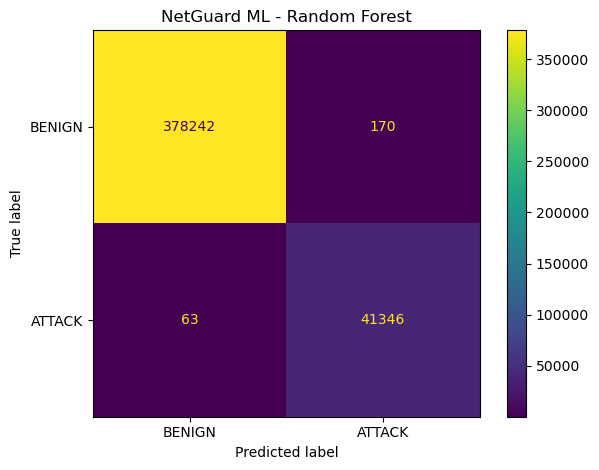

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Attack precision:",
      round(precision_score(y_test, y_pred,
                            pos_label="ATTACK", zero_division=0), 4))
print("Attack recall:",
      round(recall_score(y_test, y_pred,
                         pos_label="ATTACK", zero_division=0), 4))
print("Attack F1-score:",
      round(f1_score(y_test, y_pred,
                     pos_label="ATTACK", zero_division=0), 4))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=["BENIGN", "ATTACK"])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot(values_format="d")

plt.title("NetGuard ML - Random Forest")
plt.tight_layout()
plt.show()

In [20]:
import joblib
import os

os.makedirs("models", exist_ok=True)

model_path = "models/netguard_intrusion_detector.joblib"

joblib.dump(model, model_path)

print("Model saved successfully!")
print("Location:", os.path.abspath(model_path))

Model saved successfully!
Location: C:\Users\royal\NetGuard-ML\models\netguard_intrusion_detector.joblib


In [21]:
import pandas as pd
import os
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "Metric": ["Accuracy", "Attack Precision", "Attack Recall", "Attack F1-Score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label="ATTACK", zero_division=0),
        recall_score(y_test, y_pred, pos_label="ATTACK", zero_division=0),
        f1_score(y_test, y_pred, pos_label="ATTACK", zero_division=0)
    ]
}

metrics_df = pd.DataFrame(metrics)

os.makedirs("outputs", exist_ok=True)
metrics_df.to_csv("outputs/model_metrics.csv", index=False)

display(metrics_df)
print("Metrics saved to outputs/model_metrics.csv")

,Metric,Score
0,Accuracy,0.999445
1,Attack Precision,0.995905
2,Attack Recall,0.998479
3,Attack F1-Score,0.997190


Metrics saved to outputs/model_metrics.csv


In [22]:
import joblib
import os

model_path = "models/netguard_intrusion_detector.joblib"

loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")

# Predict on 5 test records
sample_data = X_test.iloc[:5]
sample_predictions = loaded_model.predict(sample_data)

results = sample_data.copy()
results["Actual"] = y_test.iloc[:5].values
results["Predicted"] = sample_predictions

display(results[["Actual", "Predicted"]])

Saved model loaded successfully!


,Actual,Predicted
327183,BENIGN,BENIGN
184843,BENIGN,BENIGN
1508049,BENIGN,BENIGN
171616,BENIGN,BENIGN
626484,BENIGN,BENIGN


In [23]:
import os

for folder in ["data/raw", "data/processed", "models", "outputs"]:
    print(f"\n{folder}/")

    if os.path.exists(folder):
        for file in os.listdir(folder):
            print("  ", file)
    else:
        print("  Folder not found")


data/raw/
   Friday-WorkingHours-Morning.pcap_ISCX.csv
   Monday-WorkingHours.pcap_ISCX.csv
   Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
   Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
   Tuesday-WorkingHours.pcap_ISCX.csv
   Wednesday-workingHours.pcap_ISCX.csv

data/processed/

models/
   netguard_intrusion_detector.joblib

outputs/
   model_metrics.csv


In [24]:
%pip install streamlit

In [27]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import numpy as np

st.set_page_config(
    page_title="NetGuard ML",
    page_icon="🛡️",
    layout="wide"
)

st.title("🛡️ NetGuard ML")
st.subheader("Machine Learning-Based Network Intrusion Detection System")

st.write(
    "Upload a CSV file containing network traffic features "
    "to classify records as BENIGN or ATTACK."
)

@st.cache_resource
def load_model():
    return joblib.load("models/netguard_intrusion_detector.joblib")

try:
    model = load_model()
    st.success("Intrusion detection model loaded successfully.")

    uploaded_file = st.file_uploader(
        "Upload network traffic CSV",
        type=["csv"]
    )

    if uploaded_file is not None:
        df = pd.read_csv(uploaded_file)
        df.columns = df.columns.str.strip()

        st.write("### Uploaded Data Preview")
        st.dataframe(df.head())

        expected_features = list(
            model.named_steps["imputer"].feature_names_in_
        )

        missing_features = [
            col for col in expected_features if col not in df.columns
        ]

        if missing_features:
            st.error(
                f"Missing {len(missing_features)} required feature(s). "
                "Please upload data with the same features used during training."
            )
            st.write("Missing features:", missing_features[:20])
        else:
            X_input = df[expected_features].apply(
                pd.to_numeric, errors="coerce"
            )
            X_input = X_input.replace([np.inf, -np.inf], np.nan)

            if st.button("Analyze Network Traffic"):
                predictions = model.predict(X_input)

                results = df.copy()
                results["Prediction"] = predictions

                st.write("### Detection Results")

                benign_count = int((predictions == "BENIGN").sum())
                attack_count = int((predictions == "ATTACK").sum())

                col1, col2 = st.columns(2)
                col1.metric("Benign Records", benign_count)
                col2.metric("Potential Attack Records", attack_count)

                st.dataframe(results)

                st.download_button(
                    "Download Results CSV",
                    data=results.to_csv(index=False).encode("utf-8"),
                    file_name="netguard_detection_results.csv",
                    mime="text/csv"
                )

                st.warning(
                    "Predictions are model-based indicators, not proof "
                    "of malicious activity. Review alerts before taking action."
                )

except Exception as e:
    st.error(f"Unable to load or run the model: {e}")

Overwriting app.py


In [28]:
import os

print(os.path.exists("app.py"))

True


In [31]:
%cd C:\Users\royal\NetGuard-ML

C:\Users\royal\NetGuard-ML


In [32]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [33]:
!python -m streamlit run app.py

^C


In [34]:
import os

print("Current folder:", os.getcwd())
print("App exists:", os.path.exists("app.py"))
print("Model exists:", os.path.exists("models/netguard_intrusion_detector.joblib"))

Current folder: C:\Users\royal\NetGuard-ML
App exists: True
Model exists: True


In [35]:
!python -m streamlit run app.py --server.headless=true

^C


In [36]:
import os
import sys

print("Python:", sys.executable)
print("Project folder:", os.getcwd())
print("app.py exists:", os.path.exists("app.py"))
print(
    "Model exists:",
    os.path.exists("models/netguard_intrusion_detector.joblib")
)

Python: C:\Users\royal\anaconda3\python.exe
Project folder: C:\Users\royal\NetGuard-ML
app.py exists: True
Model exists: True


In [37]:
import os
import glob
import numpy as np
import pandas as pd

# Load each original CSV separately and preserve its filename
files = glob.glob("data/raw/*.csv")

frames = []

for file in files:
    df = pd.read_csv(file, low_memory=False)
    df.columns = df.columns.str.strip()
    df["source_file"] = os.path.basename(file)
    frames.append(df)

raw_all = pd.concat(frames, ignore_index=True)

# Convert labels to BENIGN or ATTACK
raw_all["Label"] = raw_all["Label"].astype(str).str.strip()
y_all = (
    raw_all["Label"].str.upper()
    .eq("BENIGN")
    .map({True: "BENIGN", False: "ATTACK"})
)

# Keep numerical model features only
X_all = raw_all.drop(
    columns=["Label", "source_file"]
).select_dtypes(include=np.number)

X_all = X_all.replace([np.inf, -np.inf], np.nan)
X_all = X_all.dropna(axis=1, how="all")

# Hold out Wednesday as the independent test set
test_mask = raw_all["source_file"].str.lower().str.contains(
    "wednesday-workinghours"
)

if not test_mask.any():
    raise ValueError("Wednesday capture file was not found.")

X_train_day = X_all.loc[~test_mask].reset_index(drop=True)
y_train_day = y_all.loc[~test_mask].reset_index(drop=True)

X_test_day = X_all.loc[test_mask].reset_index(drop=True)
y_test_day = y_all.loc[test_mask].reset_index(drop=True)

# Remove duplicate feature-label pairs within each partition
train_frame = X_train_day.copy()
train_frame["target"] = y_train_day
train_frame = train_frame.drop_duplicates()

y_train_day = train_frame.pop("target").reset_index(drop=True)
X_train_day = train_frame.reset_index(drop=True)

test_frame = X_test_day.copy()
test_frame["target"] = y_test_day
test_frame = test_frame.drop_duplicates()

y_test_day = test_frame.pop("target").reset_index(drop=True)
X_test_day = test_frame.reset_index(drop=True)

# Match feature order
X_test_day = X_test_day[X_train_day.columns]

print("Training records:", len(X_train_day))
print("Unseen-day test records:", len(X_test_day))
print("Training features:", X_train_day.shape[1])

print("\nTraining label distribution:")
print(y_train_day.value_counts())

print("\nWednesday test label distribution:")
print(y_test_day.value_counts())

Training records: 1506369
Unseen-day test records: 610794
Training features: 78

Training label distribution:
target
BENIGN    1493085
ATTACK      13284
Name: count, dtype: int64

Wednesday test label distribution:
target
BENIGN    417035
ATTACK    193759
Name: count, dtype: int64


In [38]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

start_time = time.time()

day_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training independent evaluation model...")

day_model.fit(X_train_day, y_train_day)

print("Training completed!")
print(
    f"Training time: {(time.time() - start_time) / 60:.2f} minutes"
)

Training independent evaluation model...
Training completed!
Training time: 1.38 minutes


UNSEEN-DAY EVALUATION
----------------------------------------
Accuracy: 0.6828
Attack precision: 0.6211
Attack recall: 0.0003
Attack F1-score: 0.0006

Detailed classification report:
              precision    recall  f1-score   support

      BENIGN       0.68      1.00      0.81    417035
      ATTACK       0.62      0.00      0.00    193759

    accuracy                           0.68    610794
   macro avg       0.65      0.50      0.41    610794
weighted avg       0.66      0.68      0.55    610794



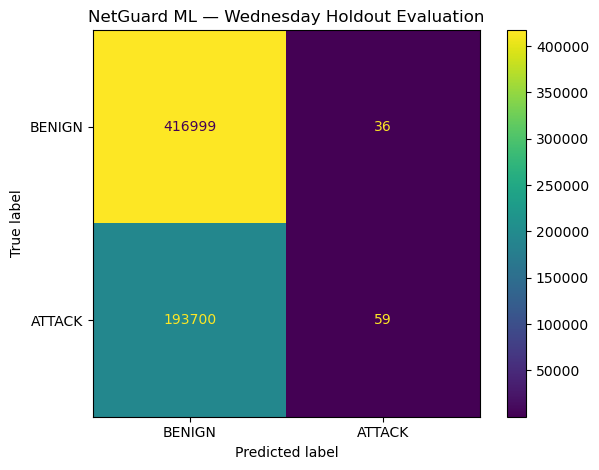

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_day_pred = day_model.predict(X_test_day)

print("UNSEEN-DAY EVALUATION")
print("-" * 40)
print(f"Accuracy: {accuracy_score(y_test_day, y_day_pred):.4f}")
print(f"Attack precision: {precision_score(y_test_day, y_day_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack recall: {recall_score(y_test_day, y_day_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack F1-score: {f1_score(y_test_day, y_day_pred, pos_label='ATTACK', zero_division=0):.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test_day,
    y_day_pred,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))

cm = confusion_matrix(
    y_test_day,
    y_day_pred,
    labels=["BENIGN", "ATTACK"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot(values_format="d")

plt.title("NetGuard ML — Wednesday Holdout Evaluation")
plt.tight_layout()
plt.show()

In [40]:
# 1. Check what the model predicted
print("Predicted label distribution:")
print(pd.Series(y_day_pred).value_counts())

# 2. Show exact confusion matrix counts
print("\nConfusion matrix:")
print(pd.DataFrame(
    confusion_matrix(
        y_test_day,
        y_day_pred,
        labels=["BENIGN", "ATTACK"]
    ),
    index=["Actual BENIGN", "Actual ATTACK"],
    columns=["Predicted BENIGN", "Predicted ATTACK"]
))

# 3. Inspect original attack labels by capture file
print("\nOriginal labels by capture file:")

label_counts = pd.crosstab(
    raw_all["source_file"],
    raw_all["Label"]
)

display(label_counts)

Predicted label distribution:
BENIGN    610699
ATTACK        95
Name: count, dtype: int64

Confusion matrix:
               Predicted BENIGN  Predicted ATTACK
Actual BENIGN            416999                36
Actual ATTACK            193700                59

Original labels by capture file:


Label,BENIGN,Bot,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,SSH-Patator,Web Attack � Brute Force,Web Attack � Sql Injection,Web Attack � XSS
source_file,,,,,,,,,,,,,
Friday-WorkingHours-Morning.pcap_ISCX.csv,189067,1966,0,0,0,0,0,0,0,0,0,0,0
Monday-WorkingHours.pcap_ISCX.csv,529918,0,0,0,0,0,0,0,0,0,0,0,0
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288566,0,0,0,0,0,0,0,36,0,0,0,0
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,168186,0,0,0,0,0,0,0,0,0,1507,21,652
Tuesday-WorkingHours.pcap_ISCX.csv,432074,0,0,0,0,0,7938,0,0,5897,0,0,0
Wednesday-workingHours.pcap_ISCX.csv,440031,0,10293,231073,5499,5796,0,11,0,0,0,0,0


In [41]:
# A. Most common labels in each capture file
for filename, group in raw_all.groupby("source_file"):
    print(f"\n--- {filename} ---")
    print(group["Label"].value_counts().head(10))

# B. Check which labels occur in training and Wednesday
train_labels = set(
    raw_all.loc[~test_mask, "Label"].unique()
)
wednesday_labels = set(
    raw_all.loc[test_mask, "Label"].unique()
)

print("\nLabels found only on Wednesday:")
print(sorted(wednesday_labels - train_labels))

print("\nLabels found in both training and Wednesday:")
print(sorted(wednesday_labels & train_labels))

# C. Inspect the model's attack probabilities
classifier = day_model.named_steps["classifier"]
classes = list(classifier.classes_)
print("\nModel classes:", classes)

attack_index = classes.index("ATTACK")
attack_probs = day_model.predict_proba(X_test_day)[:, attack_index]

print("\nPredicted attack probability quantiles:")
print(pd.Series(attack_probs).quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
))

print("\nActual attacks with predicted probability >= 0.5:",
      int(((attack_probs >= 0.5) & (y_test_day.to_numpy() == "ATTACK")).sum()))


--- Friday-WorkingHours-Morning.pcap_ISCX.csv ---
Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

--- Monday-WorkingHours.pcap_ISCX.csv ---
Label
BENIGN    529918
Name: count, dtype: int64

--- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ---
Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

--- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv ---
Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

--- Tuesday-WorkingHours.pcap_ISCX.csv ---
Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64

--- Wednesday-workingHours.pcap_ISCX.csv ---
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64

Labels found only

In [42]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Build a dataset with the original attack labels preserved
learning_data = X_all.copy()
learning_data["original_label"] = raw_all["Label"].values
learning_data["target"] = y_all.values

# Remove duplicate feature rows within each original label
learning_data = learning_data.drop_duplicates(
    subset=list(X_all.columns) + ["original_label"]
)

# Keep up to 150,000 BENIGN records and 30,000
# records per attack category
sampled_groups = []

for label, group in learning_data.groupby("original_label"):
    limit = 150000 if label.upper() == "BENIGN" else 30000
    n = min(len(group), limit)

    sampled_groups.append(
        group.sample(n=n, random_state=42)
    )

balanced_data = pd.concat(
    sampled_groups,
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Separate features and binary target
X_balanced = balanced_data[X_all.columns]
y_balanced = balanced_data["target"]
original_labels = balanced_data["original_label"]

# Split while preserving each original attack category
train_idx, val_idx = train_test_split(
    np.arange(len(balanced_data)),
    test_size=0.20,
    random_state=42,
    stratify=original_labels
)

X_train_bal = X_balanced.iloc[train_idx]
X_val_bal = X_balanced.iloc[val_idx]

y_train_bal = y_balanced.iloc[train_idx]
y_val_bal = y_balanced.iloc[val_idx]

print("Training records:", len(X_train_bal))
print("Validation records:", len(X_val_bal))

print("\nTraining labels:")
print(y_train_bal.value_counts())

print("\nValidation labels:")
print(y_val_bal.value_counts())

print("\nAttack categories represented in training:")
print(original_labels.iloc[train_idx].value_counts())

Training records: 171355
Validation records: 42839

Training labels:
target
BENIGN    120000
ATTACK     51355
Name: count, dtype: int64

Validation labels:
target
BENIGN    30000
ATTACK    12839
Name: count, dtype: int64

Attack categories represented in training:
original_label
BENIGN                        120000
DoS Hulk                       24000
DoS GoldenEye                   8229
FTP-Patator                     4746
DoS slowloris                   4308
DoS Slowhttptest                4182
SSH-Patator                     2575
Bot                             1562
Web Attack � Brute Force        1176
Web Attack � XSS                 522
Infiltration                      29
Web Attack � Sql Injection        17
Heartbleed                         9
Name: count, dtype: int64


In [43]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

start_time = time.time()

improved_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training improved NetGuard ML model...")

improved_model.fit(X_train_bal, y_train_bal)

print("Training completed!")
print(
    f"Training time: {(time.time() - start_time) / 60:.2f} minutes"
)

Training improved NetGuard ML model...
Training completed!
Training time: 0.17 minutes


IMPROVED MODEL — VALIDATION RESULTS
---------------------------------------------
Accuracy: 0.9987
Attack precision: 0.9986
Attack recall: 0.9972
Attack F1-score: 0.9979

Classification report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     30000
      ATTACK       1.00      1.00      1.00     12839

    accuracy                           1.00     42839
   macro avg       1.00      1.00      1.00     42839
weighted avg       1.00      1.00      1.00     42839



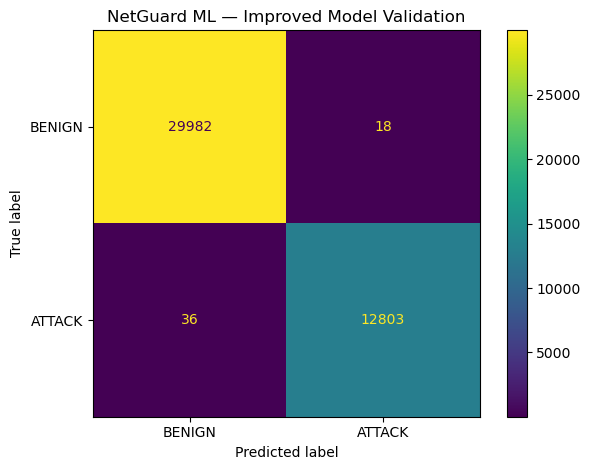

In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_val_pred = improved_model.predict(X_val_bal)

print("IMPROVED MODEL — VALIDATION RESULTS")
print("-" * 45)
print(f"Accuracy: {accuracy_score(y_val_bal, y_val_pred):.4f}")
print(f"Attack precision: {precision_score(y_val_bal, y_val_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack recall: {recall_score(y_val_bal, y_val_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack F1-score: {f1_score(y_val_bal, y_val_pred, pos_label='ATTACK', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_val_bal,
    y_val_pred,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))

cm = confusion_matrix(
    y_val_bal,
    y_val_pred,
    labels=["BENIGN", "ATTACK"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot(values_format="d")

plt.title("NetGuard ML — Improved Model Validation")
plt.tight_layout()
plt.show()

NETGUARD ML — WEDNESDAY HOLDOUT RESULTS
---------------------------------------------
Accuracy: 0.9992
Attack precision: 0.9987
Attack recall: 0.9987
Attack F1-score: 0.9987

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    417035
      ATTACK       1.00      1.00      1.00    193759

    accuracy                           1.00    610794
   macro avg       1.00      1.00      1.00    610794
weighted avg       1.00      1.00      1.00    610794



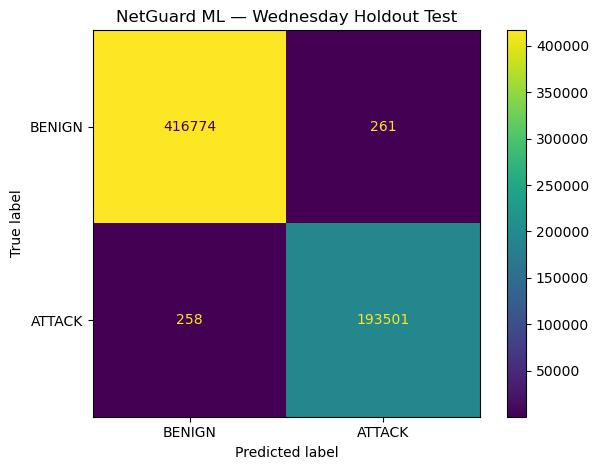

In [45]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on the separate Wednesday capture
y_wed_pred = improved_model.predict(X_test_day)

print("NETGUARD ML — WEDNESDAY HOLDOUT RESULTS")
print("-" * 45)
print(f"Accuracy: {accuracy_score(y_test_day, y_wed_pred):.4f}")
print(
    "Attack precision:",
    f"{precision_score(y_test_day, y_wed_pred, pos_label='ATTACK', zero_division=0):.4f}"
)
print(
    "Attack recall:",
    f"{recall_score(y_test_day, y_wed_pred, pos_label='ATTACK', zero_division=0):.4f}"
)
print(
    "Attack F1-score:",
    f"{f1_score(y_test_day, y_wed_pred, pos_label='ATTACK', zero_division=0):.4f}"
)

print("\nClassification Report:")
print(classification_report(
    y_test_day,
    y_wed_pred,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))

cm = confusion_matrix(
    y_test_day, y_wed_pred,
    labels=["BENIGN", "ATTACK"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot(values_format="d")

plt.title("NetGuard ML — Wednesday Holdout Test")
plt.tight_layout()
plt.show()

In [46]:
import pandas as pd

# Ensure both datasets use the same feature order
X_train_check = X_train_bal[X_test_day.columns]
X_test_check = X_test_day[X_train_check.columns]

# Hash each feature row for efficient comparison
train_hashes = pd.util.hash_pandas_object(
    X_train_check, index=False
)
test_hashes = pd.util.hash_pandas_object(
    X_test_check, index=False
)

train_hash_set = set(train_hashes)

overlap_count = test_hashes.isin(train_hash_set).sum()
total_test_rows = len(X_test_check)

print("DATA LEAKAGE CHECK")
print("-" * 35)
print(f"Wednesday test rows: {total_test_rows:,}")
print(f"Rows matching training features: {overlap_count:,}")
print(
    f"Overlap percentage: "
    f"{(overlap_count / total_test_rows) * 100:.4f}%"
)

DATA LEAKAGE CHECK
-----------------------------------
Wednesday test rows: 610,794
Rows matching training features: 66,975
Overlap percentage: 10.9652%


In [47]:

# Remove Wednesday rows whose features exactly match training rows
unseen_mask = ~test_hashes.isin(train_hash_set)

X_wed_unseen = X_test_check.loc[unseen_mask].copy()
y_wed_unseen = y_test_day.loc[unseen_mask].copy()

print("CLEANER WEDNESDAY TEST SET")
print("-" * 40)
print(f"Original test rows: {len(X_test_check):,}")
print(f"Matching rows removed: {(~unseen_mask).sum():,}")
print(f"Remaining test rows: {len(X_wed_unseen):,}")
print("\nClass distribution:")
print(y_wed_unseen.value_counts())


CLEANER WEDNESDAY TEST SET
----------------------------------------
Original test rows: 610,794
Matching rows removed: 66,975
Remaining test rows: 543,819

Class distribution:
target
BENIGN    390801
ATTACK    153018
Name: count, dtype: int64


In [48]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

y_unseen_pred = improved_model.predict(X_wed_unseen)

print("\nEXACT-OVERLAP-REMOVED RESULTS")
print("-" * 40)
print(f"Accuracy: {accuracy_score(y_wed_unseen, y_unseen_pred):.4f}")
print(f"Attack precision: {precision_score(y_wed_unseen, y_unseen_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack recall: {recall_score(y_wed_unseen, y_unseen_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack F1-score: {f1_score(y_wed_unseen, y_unseen_pred, pos_label='ATTACK', zero_division=0):.4f}")
print("\n", classification_report(
    y_wed_unseen, y_unseen_pred,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(
    y_wed_unseen, y_unseen_pred,
    labels=["BENIGN", "ATTACK"]
))



EXACT-OVERLAP-REMOVED RESULTS
----------------------------------------
Accuracy: 0.9991
Attack precision: 0.9984
Attack recall: 0.9984
Attack F1-score: 0.9984

               precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    390801
      ATTACK       1.00      1.00      1.00    153018

    accuracy                           1.00    543819
   macro avg       1.00      1.00      1.00    543819
weighted avg       1.00      1.00      1.00    543819

Confusion matrix:
[[390556    245]
 [   242 152776]]


In [49]:

import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

# Train only on non-Wednesday data
generalization_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()
generalization_model.fit(X_train_day, y_train_day)

# Evaluate on Wednesday data
y_generalization_pred = generalization_model.predict(X_test_day)

print("UNSEEN-DAY GENERALIZATION RESULTS")
print("-" * 40)
print(f"Accuracy: {accuracy_score(y_test_day, y_generalization_pred):.4f}")
print(f"Attack precision: {precision_score(y_test_day, y_generalization_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack recall: {recall_score(y_test_day, y_generalization_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack F1-score: {f1_score(y_test_day, y_generalization_pred, pos_label='ATTACK', zero_division=0):.4f}")
print("\n", classification_report(
    y_test_day, y_generalization_pred,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))
print(f"Training and evaluation time: {(time.time()-start)/60:.2f} minutes")


UNSEEN-DAY GENERALIZATION RESULTS
----------------------------------------
Accuracy: 0.6828
Attack precision: 0.6211
Attack recall: 0.0003
Attack F1-score: 0.0006

               precision    recall  f1-score   support

      BENIGN       0.68      1.00      0.81    417035
      ATTACK       0.62      0.00      0.00    193759

    accuracy                           0.68    610794
   macro avg       0.65      0.50      0.41    610794
weighted avg       0.66      0.68      0.55    610794

Training and evaluation time: 1.62 minutes


In [50]:

# Compare predictions against original Wednesday attack categories
wed_results = pd.DataFrame({
    "original_label": raw_all.loc[
        raw_all["source_file"].str.contains("Wednesday", case=False),
        "Label"
    ].reset_index(drop=True)
})

print("Before proceeding, verify that the labels align with X_test_day.")
print("Use the safer method below to build a label-aligned test table.")

# Build from the same deduplicated Wednesday rows used for the holdout.
# This assumes the earlier variable wed_data contains that exact table.


Before proceeding, verify that the labels align with X_test_day.
Use the safer method below to build a label-aligned test table.


In [51]:
print("Available Wednesday-related variables:")
for name in ["raw_all", "X_test_day", "y_test_day", "wed_data", "day_model"]:
    print(name, "exists:", name in globals())

Available Wednesday-related variables:
raw_all exists: True
X_test_day exists: True
y_test_day exists: True
wed_data exists: False
day_model exists: True


In [52]:

# Inspect the columns and available variables
print("raw_all shape:", raw_all.shape)
print("raw_all columns:", raw_all.columns.tolist()[-5:])

print("\nWednesday source-file names:")
print(
    raw_all.loc[
        raw_all["source_file"].str.contains("Wednesday", case=False, na=False),
        "source_file"
    ].value_counts()
)

print("\nTest feature shape:", X_test_day.shape)
print("Test target shape:", y_test_day.shape)
print("Target counts:")
print(y_test_day.value_counts())


raw_all shape: (2318531, 80)
raw_all columns: ['Idle Std', 'Idle Max', 'Idle Min', 'Label', 'source_file']

Wednesday source-file names:
source_file
Wednesday-workingHours.pcap_ISCX.csv    692703
Name: count, dtype: int64

Test feature shape: (610794, 78)
Test target shape: (610794,)
Target counts:
target
BENIGN    417035
ATTACK    193759
Name: count, dtype: int64


In [53]:

# Rebuild the Wednesday feature/label dataset
wed_raw = raw_all[
    raw_all["source_file"].str.contains(
        "Wednesday", case=False, na=False
    )
].copy()

# Convert labels to binary and prepare numeric features
wed_raw["target"] = wed_raw["Label"].apply(
    lambda label: "BENIGN" if str(label).strip().upper() == "BENIGN"
    else "ATTACK"
)

wed_features = wed_raw.drop(
    columns=["Label", "source_file", "target"]
).select_dtypes(include="number")

wed_features = wed_features.replace(
    [float("inf"), float("-inf")], float("nan")
)

# Remove columns that contain no usable numeric values
wed_features = wed_features.dropna(axis=1, how="all")

# Deduplicate using the original attack label
wed_labeled = wed_features.copy()
wed_labeled["original_label"] = wed_raw["Label"].values
wed_labeled["target"] = wed_raw["target"].values

wed_labeled = wed_labeled.drop_duplicates(
    subset=list(wed_features.columns) + ["original_label"]
).reset_index(drop=True)

print("Reconstructed Wednesday records:", len(wed_labeled))
print("\nOriginal attack categories:")
print(wed_labeled["original_label"].value_counts())


Reconstructed Wednesday records: 610794

Original attack categories:
original_label
BENIGN              417035
DoS Hulk            172849
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed              11
Name: count, dtype: int64


In [54]:

from sklearn.metrics import recall_score
import pandas as pd

# Confirm row counts before combining predictions and labels
assert len(wed_labeled) == len(X_test_day)
assert len(y_generalization_pred) == len(X_test_day)

attack_results = pd.DataFrame({
    "original_label": wed_labeled["original_label"].to_numpy(),
    "actual_target": y_test_day.to_numpy(),
    "predicted_target": y_generalization_pred
})

print("DETECTION PERFORMANCE BY ORIGINAL ATTACK TYPE")
print("-" * 55)

for attack_name, group in attack_results.groupby("original_label"):
    if attack_name.strip().upper() == "BENIGN":
        continue

    detected = (group["predicted_target"] == "ATTACK").sum()
    total = len(group)
    recall = detected / total if total else 0

    print(
        f"{attack_name}: "
        f"detected {detected:,}/{total:,} | "
        f"recall {recall:.4%}"
    )


DETECTION PERFORMANCE BY ORIGINAL ATTACK TYPE
-------------------------------------------------------
DoS GoldenEye: detected 41/10,286 | recall 0.3986%
DoS Hulk: detected 7/172,849 | recall 0.0040%
DoS Slowhttptest: detected 5/5,228 | recall 0.0956%
DoS slowloris: detected 6/5,385 | recall 0.1114%
Heartbleed: detected 0/11 | recall 0.0000%


In [55]:

import numpy as np
import time

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Train only on non-Wednesday data
X_train_gb = X_train_day.copy()
y_train_gb = y_train_day.copy()

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_gb
)

gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

start = time.time()
print("Training gradient boosting model...")

gb_model.fit(
    X_train_gb,
    y_train_gb,
    classifier__sample_weight=sample_weights
)

print(f"Training completed in {(time.time()-start)/60:.2f} minutes.")

gb_pred = gb_model.predict(X_test_day)

print("\nWEDNESDAY HOLDOUT RESULTS")
print("-" * 35)
print(f"Accuracy: {accuracy_score(y_test_day, gb_pred):.4f}")
print(f"Attack precision: {precision_score(y_test_day, gb_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack recall: {recall_score(y_test_day, gb_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack F1-score: {f1_score(y_test_day, gb_pred, pos_label='ATTACK', zero_division=0):.4f}")



Training gradient boosting model...


C:\Users\royal\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\royal\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\royal\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\royal\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Training completed in 0.72 minutes.

WEDNESDAY HOLDOUT RESULTS
-----------------------------------
Accuracy: 0.6853
Attack precision: 0.9586
Attack recall: 0.0085
Attack F1-score: 0.0168


In [56]:

# Inspect likely useful network-flow features
candidate_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s"
]

available_features = [
    feature for feature in candidate_features
    if feature in X_train_day.columns and feature in X_test_day.columns
]

print("Available features:", available_features)

for feature in available_features:
    print(f"\n{feature}")
    print("Training data:")
    print(X_train_day[feature].describe(
        percentiles=[0.25, 0.50, 0.75]
    ).round(3))

    print("Wednesday data:")
    print(X_test_day[feature].describe(
        percentiles=[0.25, 0.50, 0.75]
    ).round(3))


Available features: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s']

Flow Duration
Training data:
count    1.506369e+06
mean     1.143343e+07
std      3.033746e+07
min     -1.200000e+01
25%      1.930000e+02
50%      3.251000e+04
75%      5.872150e+05
max      1.200000e+08
Name: Flow Duration, dtype: float64
Wednesday data:
count    6.107940e+05
mean     3.175187e+07
std      4.421601e+07
min     -1.000000e+00
25%      1.264000e+03
50%      1.497000e+05
75%      8.493914e+07
max      1.200000e+08
Name: Flow Duration, dtype: float64

Total Fwd Packets
Training data:
count    1506369.000
mean          11.635
std          894.011
min            1.000
25%            2.000
50%            2.000
75%            4.000
max       219759.000
Name: Total Fwd Packets, dtype: float64
Wednesday data:
count    610794.000
mean         10.555
std         795.717
min           1.000
25%           2.000
50%           3.000
75%           7.000
max      2039

In [57]:

import numpy as np

X_train_clean = X_train_day.copy()
X_test_clean = X_test_day.copy()

# Replace infinities and invalid negative flow statistics
for df in (X_train_clean, X_test_clean):
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

    nonnegative_features = [
        "Flow Duration",
        "Flow Bytes/s",
        "Flow Packets/s",
        "Flow IAT Mean",
        "Flow IAT Std",
        "Flow IAT Max",
        "Flow IAT Min"
    ]

    for feature in nonnegative_features:
        if feature in df.columns:
            df.loc[df[feature] < 0, feature] = np.nan

print("Invalid-value cleanup complete.")
print("Training shape:", X_train_clean.shape)
print("Wednesday test shape:", X_test_clean.shape)

for feature in ["Flow Duration", "Flow Bytes/s", "Flow Packets/s"]:
    if feature in X_train_clean.columns:
        print(
            feature,
            "| negative training values:",
            int((X_train_clean[feature] < 0).sum()),
            "| negative Wednesday values:",
            int((X_test_clean[feature] < 0).sum())
        )


Invalid-value cleanup complete.
Training shape: (1506369, 78)
Wednesday test shape: (610794, 78)
Flow Duration | negative training values: 0 | negative Wednesday values: 0
Flow Bytes/s | negative training values: 0 | negative Wednesday values: 0
Flow Packets/s | negative training values: 0 | negative Wednesday values: 0


In [58]:

import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

clean_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()
print("Training Random Forest on cleaned data...")

clean_model.fit(X_train_clean, y_train_day)

clean_pred = clean_model.predict(X_test_clean)

print(f"\nTraining and evaluation time: {(time.time()-start)/60:.2f} minutes")
print("\nCLEANED MODEL — WEDNESDAY HOLDOUT")
print("-" * 40)
print(f"Accuracy: {accuracy_score(y_test_day, clean_pred):.4f}")
print(f"Attack precision: {precision_score(y_test_day, clean_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack recall: {recall_score(y_test_day, clean_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack F1-score: {f1_score(y_test_day, clean_pred, pos_label='ATTACK', zero_division=0):.4f}")


Training Random Forest on cleaned data...

Training and evaluation time: 1.33 minutes

CLEANED MODEL — WEDNESDAY HOLDOUT
----------------------------------------
Accuracy: 0.6828
Attack precision: 0.6774
Attack recall: 0.0004
Attack F1-score: 0.0009


In [59]:

print("TRAINING LABEL DISTRIBUTION")
print("-" * 35)
print(y_train_day.value_counts())
print("\nTraining percentages:")
print((y_train_day.value_counts(normalize=True) * 100).round(2))

print("\nWEDNESDAY LABEL DISTRIBUTION")
print("-" * 35)
print(y_test_day.value_counts())
print("\nWednesday percentages:")
print((y_test_day.value_counts(normalize=True) * 100).round(2))

print("\nORIGINAL ATTACK TYPES IN NON-WEDNESDAY FILES")
print("-" * 50)

non_wednesday = raw_all[
    ~raw_all["source_file"].str.contains(
        "Wednesday", case=False, na=False
    )
]

print(non_wednesday["Label"].value_counts().to_string())


TRAINING LABEL DISTRIBUTION
-----------------------------------
target
BENIGN    1493085
ATTACK      13284
Name: count, dtype: int64

Training percentages:
target
BENIGN    99.12
ATTACK     0.88
Name: proportion, dtype: float64

WEDNESDAY LABEL DISTRIBUTION
-----------------------------------
target
BENIGN    417035
ATTACK    193759
Name: count, dtype: int64

Wednesday percentages:
target
BENIGN    68.28
ATTACK    31.72
Name: proportion, dtype: float64

ORIGINAL ATTACK TYPES IN NON-WEDNESDAY FILES
--------------------------------------------------
Label
BENIGN                        1607811
FTP-Patator                      7938
SSH-Patator                      5897
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21


In [60]:

import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

# Random Forest probability for the ATTACK class
clean_classes = list(clean_model.named_steps["classifier"].classes_)
attack_index = clean_classes.index("ATTACK")

attack_probs = clean_model.predict_proba(X_test_clean)[:, attack_index]

print("ATTACK PROBABILITY DISTRIBUTION")
print("-" * 40)
print(pd.Series(attack_probs).describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
).round(5))

print("\nTHRESHOLD COMPARISON")
print("-" * 40)

for threshold in [0.50, 0.30, 0.20, 0.10, 0.05, 0.01]:
    pred = np.where(attack_probs >= threshold, "ATTACK", "BENIGN")
    tn, fp, fn, tp = confusion_matrix(
        y_test_day, pred, labels=["BENIGN", "ATTACK"]
    ).ravel()

    recall = tp / (tp + fn) if tp + fn else 0
    precision = tp / (tp + fp) if tp + fp else 0
    false_positive_rate = fp / (fp + tn) if fp + tn else 0

    print(
        f"Threshold={threshold:.2f} | "
        f"Attack recall={recall:.4%} | "
        f"Precision={precision:.4%} | "
        f"False-positive rate={false_positive_rate:.4%}"
    )


ATTACK PROBABILITY DISTRIBUTION
----------------------------------------
count    610794.00000
mean          0.01082
std           0.02788
min           0.00000
50%           0.00000
75%           0.00974
90%           0.02982
95%           0.04945
99%           0.11635
99.9%         0.35187
max           0.99574
dtype: float64

THRESHOLD COMPARISON
----------------------------------------
Threshold=0.50 | Attack recall=0.0434% | Precision=67.7419% | False-positive rate=0.0096%
Threshold=0.30 | Attack recall=0.2978% | Precision=66.8598% | False-positive rate=0.0686%
Threshold=0.20 | Attack recall=0.4702% | Precision=40.6515% | False-positive rate=0.3189%
Threshold=0.10 | Attack recall=1.1870% | Precision=30.8476% | False-positive rate=1.2363%
Threshold=0.05 | Attack recall=8.3769% | Precision=61.8607% | False-positive rate=2.3996%
Threshold=0.01 | Attack recall=54.9445% | Precision=77.1215% | False-positive rate=7.5730%


In [61]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Use the non-Wednesday training data for a diagnostic check.
# This is NOT an independent test because the model has seen these rows.
train_probs = clean_model.predict_proba(X_train_clean)
classes = list(clean_model.named_steps["classifier"].classes_)
attack_index = classes.index("ATTACK")

train_attack_probs = train_probs[:, attack_index]
train_pred_001 = np.where(
    train_attack_probs >= 0.01, "ATTACK", "BENIGN"
)

print("TRAINING-DATA DIAGNOSTIC AT THRESHOLD 0.01")
print("-" * 50)
print(classification_report(
    y_train_day,
    train_pred_001,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(
    y_train_day,
    train_pred_001,
    labels=["BENIGN", "ATTACK"]
))


TRAINING-DATA DIAGNOSTIC AT THRESHOLD 0.01
--------------------------------------------------
              precision    recall  f1-score   support

      BENIGN       1.00      0.94      0.97   1493085
      ATTACK       0.13      1.00      0.23     13284

    accuracy                           0.94   1506369
   macro avg       0.56      0.97      0.60   1506369
weighted avg       0.99      0.94      0.96   1506369

Confusion matrix:
[[1402192   90893]
 [      0   13284]]


In [62]:

from sklearn.model_selection import train_test_split
import numpy as np

# Split only the non-Wednesday dataset
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_clean,
    y_train_day,
    test_size=0.20,
    random_state=42,
    stratify=y_train_day
)

print("TRAIN / VALIDATION SPLIT")
print("-" * 35)
print("Training records:", len(X_fit))
print("Validation records:", len(X_val))

print("\nTraining labels:")
print(y_fit.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())


TRAIN / VALIDATION SPLIT
-----------------------------------
Training records: 1205095
Validation records: 301274

Training labels:
target
BENIGN    1194468
ATTACK      10627
Name: count, dtype: int64

Validation labels:
target
BENIGN    298617
ATTACK      2657
Name: count, dtype: int64


In [63]:

import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

validation_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()
print("Training validation model...")

validation_model.fit(X_fit, y_fit)

print("Training complete.")
print(f"Time taken: {(time.time() - start) / 60:.2f} minutes")


Training validation model...
Training complete.
Time taken: 1.09 minutes


In [64]:

import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

classes = list(validation_model.named_steps["classifier"].classes_)
attack_index = classes.index("ATTACK")

val_probs = validation_model.predict_proba(X_val)[:, attack_index]

print("VALIDATION THRESHOLD COMPARISON")
print("-" * 65)

for threshold in [0.50, 0.20, 0.10, 0.05, 0.02, 0.01]:
    val_pred = np.where(val_probs >= threshold, "ATTACK", "BENIGN")
    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=["BENIGN", "ATTACK"]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    fpr = fp / (fp + tn) if fp + tn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    print(
        f"Threshold={threshold:.2f} | "
        f"Precision={precision:.4f} | Recall={recall:.4f} | "
        f"F1={f1:.4f} | False-positive rate={fpr:.4f}"
    )


VALIDATION THRESHOLD COMPARISON
-----------------------------------------------------------------
Threshold=0.50 | Precision=0.9955 | Recall=0.9887 | F1=0.9921 | False-positive rate=0.0000
Threshold=0.20 | Precision=0.8055 | Recall=0.9944 | F1=0.8900 | False-positive rate=0.0021
Threshold=0.10 | Precision=0.4910 | Recall=0.9970 | F1=0.6580 | False-positive rate=0.0092
Threshold=0.05 | Precision=0.3151 | Recall=0.9992 | F1=0.4791 | False-positive rate=0.0193
Threshold=0.02 | Precision=0.1933 | Recall=0.9992 | F1=0.3239 | False-positive rate=0.0371
Threshold=0.01 | Precision=0.1366 | Recall=1.0000 | F1=0.2403 | False-positive rate=0.0562


In [65]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import numpy as np

# Keep the threshold selected on validation data
FINAL_THRESHOLD = 0.50

# Predict attack probabilities on Wednesday
wed_probs = validation_model.predict_proba(X_test_clean)[:, attack_index]
wed_pred = np.where(
    wed_probs >= FINAL_THRESHOLD,
    "ATTACK",
    "BENIGN"
)

print("FINAL WEDNESDAY HOLDOUT EVALUATION")
print("-" * 45)
print(f"Threshold: {FINAL_THRESHOLD:.2f}")
print(f"Accuracy: {accuracy_score(y_test_day, wed_pred):.4f}")
print(f"Attack precision: {precision_score(y_test_day, wed_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack recall: {recall_score(y_test_day, wed_pred, pos_label='ATTACK', zero_division=0):.4f}")
print(f"Attack F1-score: {f1_score(y_test_day, wed_pred, pos_label='ATTACK', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_day,
    wed_pred,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test_day,
    wed_pred,
    labels=["BENIGN", "ATTACK"]
))


FINAL WEDNESDAY HOLDOUT EVALUATION
---------------------------------------------
Threshold: 0.50
Accuracy: 0.6828
Attack precision: 0.5672
Attack recall: 0.0002
Attack F1-score: 0.0004

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.68      1.00      0.81    417035
      ATTACK       0.57      0.00      0.00    193759

    accuracy                           0.68    610794
   macro avg       0.62      0.50      0.41    610794
weighted avg       0.65      0.68      0.55    610794

Confusion matrix:
[[417006     29]
 [193721     38]]


In [66]:

print("ORIGINAL ATTACK LABEL COUNTS")
print("-" * 40)

print(raw_all["Label"].value_counts().to_string())

print("\nCapture files:")
print(raw_all["source_file"].value_counts().to_string())


ORIGINAL ATTACK LABEL COUNTS
----------------------------------------
Label
BENIGN                        2047842
DoS Hulk                       231073
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11

Capture files:
source_file
Wednesday-workingHours.pcap_ISCX.csv                           692703
Monday-WorkingHours.pcap_ISCX.csv                              529918
Tuesday-WorkingHours.pcap_ISCX.csv                             445909
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv    288602
Friday-WorkingHours-Morning.pcap_ISCX.csv                      191033
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.c

In [67]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Keep original labels and numeric network-flow features
multi_data = raw_all.drop(
    columns=["source_file"]
).copy()

multi_labels = multi_data["Label"].astype(str).str.strip()

multi_X = multi_data.drop(columns=["Label"]).select_dtypes(
    include="number"
)
multi_X = multi_X.replace([np.inf, -np.inf], np.nan)
multi_X = multi_X.dropna(axis=1, how="all")

# Combine features and labels, then remove exact duplicate rows
multi_data_clean = multi_X.copy()
multi_data_clean["original_label"] = multi_labels.to_numpy()

multi_data_clean = multi_data_clean.drop_duplicates(
    subset=list(multi_X.columns) + ["original_label"]
).reset_index(drop=True)

X_multi = multi_data_clean[multi_X.columns]
y_multi = multi_data_clean["original_label"]

print("Multiclass dataset shape:", X_multi.shape)
print("\nOriginal label counts:")
print(y_multi.value_counts().to_string())

# Stratified split: every class with enough examples can appear in both sets
X_multi_train, X_multi_val, y_multi_train, y_multi_val = train_test_split(
    X_multi,
    y_multi,
    test_size=0.20,
    random_state=42,
    stratify=y_multi
)

print("\nTraining records:", len(X_multi_train))
print("Validation records:", len(X_multi_val))


Multiclass dataset shape: (2099101, 78)

Original label counts:
original_label
BENIGN                        1892058
DoS Hulk                       172849
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11

Training records: 1679280
Validation records: 419821


In [68]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
import joblib
import os

# Build the multiclass classification pipeline
multiclass_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training multiclass model...")

multiclass_model.fit(X_multi_train, y_multi_train)

print("Training completed successfully!")

# Predict validation records
y_multi_pred = multiclass_model.predict(X_multi_val)

# Evaluate performance
print("\nValidation Accuracy:",
      round(accuracy_score(y_multi_val, y_multi_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_multi_val,
    y_multi_pred,
    zero_division=0
))

Training multiclass model...
Training completed successfully!

Validation Accuracy: 0.9943

Classification Report:
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.99      1.00    378412
                       Bot       0.17      0.99      0.29       391
             DoS GoldenEye       0.99      1.00      0.99      2057
                  DoS Hulk       0.99      1.00      1.00     34570
          DoS Slowhttptest       0.99      0.99      0.99      1046
             DoS slowloris       1.00      0.99      1.00      1077
               FTP-Patator       1.00      1.00      1.00      1187
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.86      0.92         7
               SSH-Patator       1.00      1.00      1.00       644
  Web Attack � Brute Force       0.79      0.60      0.68       294
Web Attack � Sql Injection       0.50      0.25      0.33         4


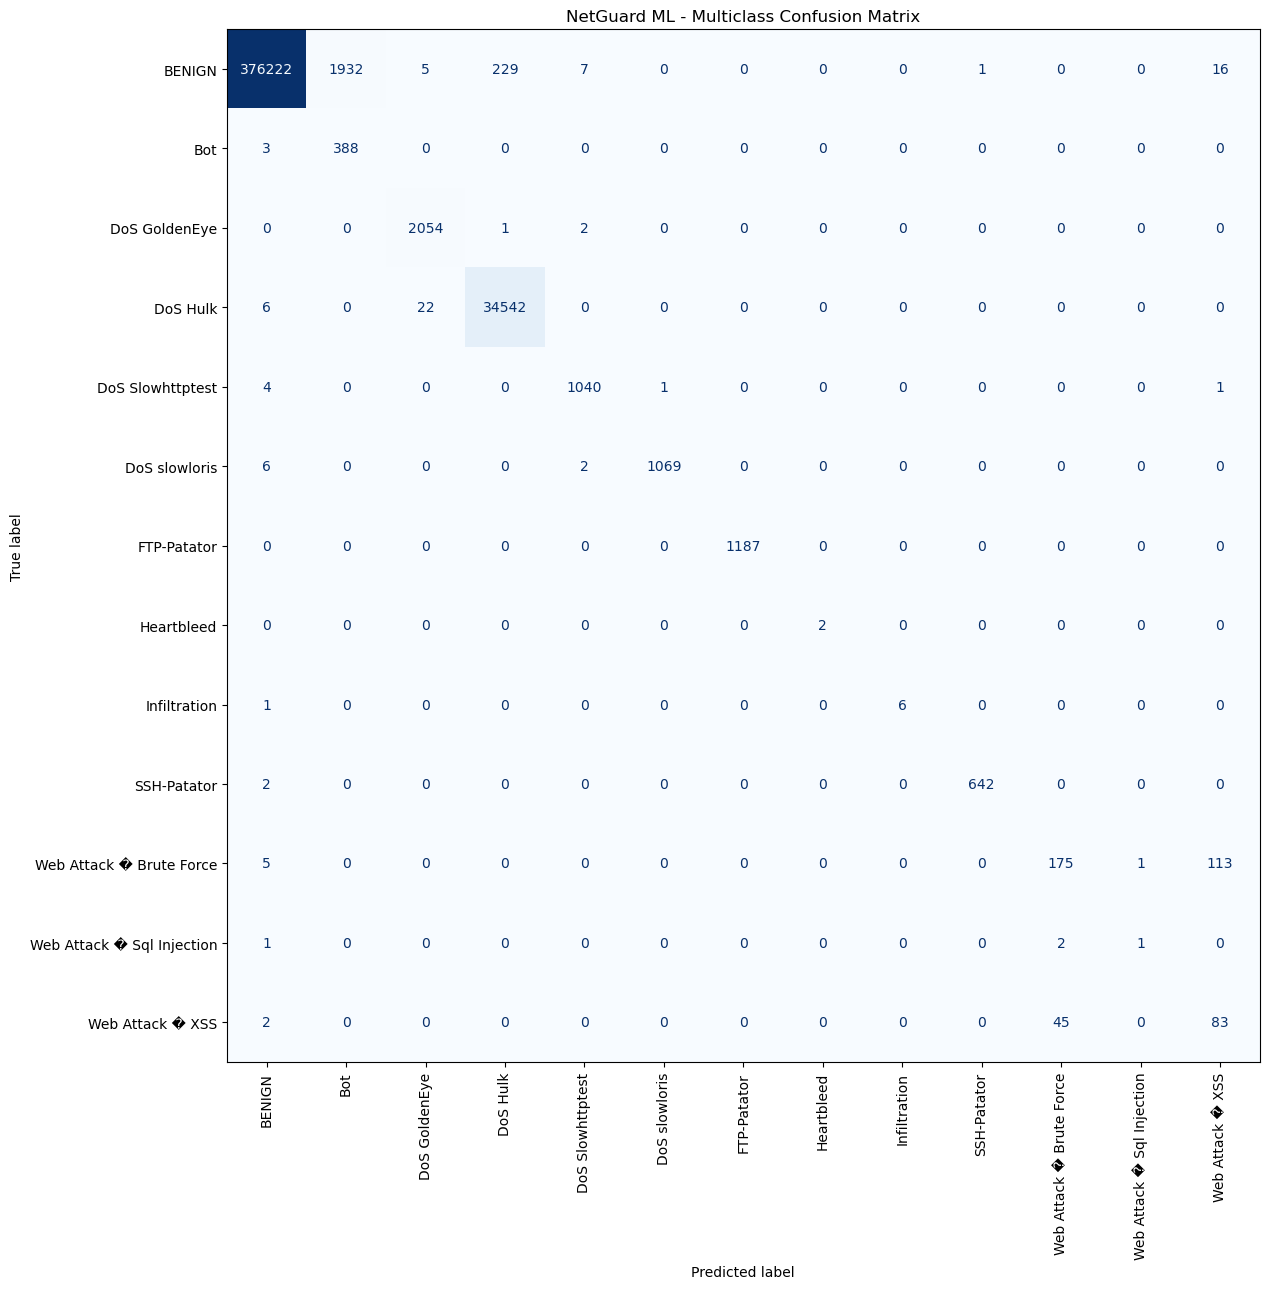

In [69]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = multiclass_model.named_steps["classifier"].classes_

cm = confusion_matrix(
    y_multi_val,
    y_multi_pred,
    labels=labels
)

fig, ax = plt.subplots(figsize=(16, 13))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("NetGuard ML - Multiclass Confusion Matrix")
plt.tight_layout()
plt.show()

In [70]:
import os
import joblib
import json

# Ensure the models directory exists
os.makedirs("models", exist_ok=True)

# Save the trained model
model_path = "models/netguard_multiclass_model.joblib"
joblib.dump(multiclass_model, model_path)

# Save the class labels
class_labels = multiclass_model.named_steps["classifier"].classes_.tolist()

with open("models/class_labels.json", "w", encoding="utf-8") as f:
    json.dump(class_labels, f, indent=4, ensure_ascii=False)

print("Model saved:", os.path.abspath(model_path))
print("Class labels saved:", os.path.abspath("models/class_labels.json"))
print("\nSupported classes:")
for label in class_labels:
    print("-", label)

Model saved: C:\Users\royal\NetGuard-ML\models\netguard_multiclass_model.joblib
Class labels saved: C:\Users\royal\NetGuard-ML\models\class_labels.json

Supported classes:
- BENIGN
- Bot
- DoS GoldenEye
- DoS Hulk
- DoS Slowhttptest
- DoS slowloris
- FTP-Patator
- Heartbleed
- Infiltration
- SSH-Patator
- Web Attack � Brute Force
- Web Attack � Sql Injection
- Web Attack � XSS


In [71]:
import os

project_path = r"C:\Users\royal\NetGuard-ML"

print("Project folder exists:", os.path.exists(project_path))
print("\nFiles in project folder:")

for item in os.listdir(project_path):
    print(item)

Project folder exists: True

Files in project folder:
.ipynb_checkpoints
app.py
data
models
NetGuard_ML.ipynb
outputs


In [72]:
app_path = r"C:\Users\royal\NetGuard-ML\app.py"

with open(app_path, "r", encoding="utf-8") as file:
    app_code = file.read()

print(app_code)

import streamlit as st
import pandas as pd
import joblib
import numpy as np

st.set_page_config(
    page_title="NetGuard ML",
    page_icon="🛡️",
    layout="wide"
)

st.title("🛡️ NetGuard ML")
st.subheader("Machine Learning-Based Network Intrusion Detection System")

st.write(
    "Upload a CSV file containing network traffic features "
    "to classify records as BENIGN or ATTACK."
)

@st.cache_resource
def load_model():
    return joblib.load("models/netguard_intrusion_detector.joblib")

try:
    model = load_model()
    st.success("Intrusion detection model loaded successfully.")

    uploaded_file = st.file_uploader(
        "Upload network traffic CSV",
        type=["csv"]
    )

    if uploaded_file is not None:
        df = pd.read_csv(uploaded_file)
        df.columns = df.columns.str.strip()

        st.write("### Uploaded Data Preview")
        st.dataframe(df.head())

        expected_features = list(
            model.named_steps["imputer"].feature_names_in_
        )

 

In [73]:
from pathlib import Path

app_path = Path(r"C:\Users\royal\NetGuard-ML\app.py")

new_app_code = r'''
import streamlit as st
import pandas as pd
import joblib
import numpy as np
from pathlib import Path

st.set_page_config(
    page_title="NetGuard ML",
    page_icon="🛡️",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "netguard_multiclass_model.joblib"

st.title("🛡️ NetGuard ML")
st.subheader("Machine Learning-Based Network Intrusion Detection System")

st.write(
    "Upload a CSV containing network-flow features to classify records "
    "as BENIGN or into a supported attack category."
)

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

try:
    model = load_model()
    st.success("Multiclass intrusion detection model loaded successfully.")

    uploaded_file = st.file_uploader(
        "Upload network traffic CSV",
        type=["csv"]
    )

    if uploaded_file is not None:
        df = pd.read_csv(uploaded_file)
        df.columns = df.columns.str.strip()

        st.write("### Uploaded Data Preview")
        st.dataframe(df.head(10), use_container_width=True)
        st.caption(f"Uploaded records: {len(df):,}")

        expected_features = list(
            model.named_steps["imputer"].feature_names_in_
        )

        missing_features = [
            col for col in expected_features if col not in df.columns
        ]

        if missing_features:
            st.error(
                f"Missing {len(missing_features)} required feature(s). "
                "The uploaded CSV must contain the features used during training."
            )
            st.write("Missing features:", missing_features[:30])
        else:
            X_input = df[expected_features].apply(
                pd.to_numeric, errors="coerce"
            )
            X_input = X_input.replace([np.inf, -np.inf], np.nan)

            if X_input.isna().all(axis=1).any():
                st.warning(
                    "Some rows contain no usable numeric feature values. "
                    "Review those rows before relying on their predictions."
                )

            if st.button("Analyze Network Traffic", type="primary"):
                with st.spinner("Analyzing network-flow records..."):
                    predictions = model.predict(X_input)

                results = df.copy()
                results["Prediction"] = predictions
                results["Status"] = np.where(
                    results["Prediction"] == "BENIGN",
                    "BENIGN",
                    "POTENTIAL ATTACK"
                )

                st.write("### Detection Summary")

                benign_count = int((predictions == "BENIGN").sum())
                attack_count = int((predictions != "BENIGN").sum())

                col1, col2, col3 = st.columns(3)
                col1.metric("Total Records", f"{len(results):,}")
                col2.metric("Benign Records", f"{benign_count:,}")
                col3.metric("Potential Attack Records", f"{attack_count:,}")

                st.write("### Predicted Class Distribution")
                distribution = (
                    results["Prediction"]
                    .value_counts()
                    .rename_axis("Class")
                    .reset_index(name="Records")
                )
                st.dataframe(distribution, use_container_width=True)

                st.write("### Detection Results")
                selected_class = st.selectbox(
                    "Filter predictions",
                    ["All"] + sorted(results["Prediction"].unique().tolist())
                )

                if selected_class == "All":
                    filtered_results = results
                else:
                    filtered_results = results[
                        results["Prediction"] == selected_class
                    ]

                st.dataframe(filtered_results, use_container_width=True)

                st.download_button(
                    "Download Results CSV",
                    data=results.to_csv(index=False).encode("utf-8"),
                    file_name="netguard_multiclass_results.csv",
                    mime="text/csv"
                )

                st.warning(
                    "Predictions are model-based indicators, not proof of "
                    "malicious activity. This model was evaluated using a "
                    "random dataset split and may not generalize to unseen "
                    "traffic or attack families. Review alerts before acting."
                )

except Exception as e:
    st.error(f"Unable to load or run the model: {e}")
'''

app_path.write_text(new_app_code.strip() + "\n", encoding="utf-8")

print("app.py updated successfully!")
print("Location:", app_path)

app.py updated successfully!
Location: C:\Users\royal\NetGuard-ML\app.py


In [74]:
import pandas as pd
import os

project_path = r"C:\Users\royal\NetGuard-ML"
test_file = os.path.join(project_path, "data", "processed", "netguard_test_sample.csv")

# Use the multiclass dataset prepared earlier
test_sample = X_multi_val.head(100).copy()

# Save the 78 expected feature columns
os.makedirs(os.path.dirname(test_file), exist_ok=True)
test_sample.to_csv(test_file, index=False)

print("Test CSV created successfully!")
print("Location:", test_file)
print("Rows:", len(test_sample))
print("Columns:", len(test_sample.columns))

Test CSV created successfully!
Location: C:\Users\royal\NetGuard-ML\data\processed\netguard_test_sample.csv
Rows: 100
Columns: 78


In [75]:
import numpy as np
import pandas as pd
from pathlib import Path

print("=== NETGUARD ML: DATASET AUDIT ===")

# 1. Dataset dimensions
print("\n1. Dataset dimensions")
print("Features:", X_multi.shape)
print("Labels:", y_multi.shape)

# 2. Label distribution
print("\n2. Class distribution")
class_counts = y_multi.value_counts()
class_summary = pd.DataFrame({
    "Records": class_counts,
    "Percentage": (class_counts / len(y_multi) * 100).round(4)
})
print(class_summary.to_string())

# 3. Missing and infinite values
print("\n3. Data quality")
X_check = X_multi.replace([np.inf, -np.inf], np.nan)
print("Missing feature values:", int(X_check.isna().sum().sum()))
print("Infinite values:", int(np.isinf(X_multi.to_numpy(dtype=float)).sum()))
print("Features with all values missing:", int(X_check.isna().all().sum()))

# 4. Exact duplicate feature rows
print("\n4. Duplicate analysis")
print("Duplicate feature rows:", int(X_multi.duplicated().sum()))
print(
    "Duplicate feature rows with the same label:",
    int(multi_data_clean.duplicated(
        subset=list(X_multi.columns) + ["original_label"]
    ).sum())
)

# 5. Capture-file availability
print("\n5. Source files")
raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")
if raw_dir.exists():
    for file in sorted(raw_dir.glob("*.csv")):
        print(f"{file.name}: {file.stat().st_size / (1024**2):.1f} MB")
else:
    print("Raw data folder not found.")

print("\nAudit complete.")

=== NETGUARD ML: DATASET AUDIT ===

1. Dataset dimensions
Features: (2099101, 78)
Labels: (2099101,)

2. Class distribution
                            Records  Percentage
original_label                                 
BENIGN                      1892058     90.1366
DoS Hulk                     172849      8.2344
DoS GoldenEye                 10286      0.4900
FTP-Patator                    5933      0.2826
DoS slowloris                  5385      0.2565
DoS Slowhttptest               5228      0.2491
SSH-Patator                    3219      0.1534
Bot                            1953      0.0930
Web Attack � Brute Force       1470      0.0700
Web Attack � XSS                652      0.0311
Infiltration                     36      0.0017
Web Attack � Sql Injection       21      0.0010
Heartbleed                       11      0.0005

3. Data quality
Missing feature values: 2420
Infinite values: 0
Features with all values missing: 0

4. Duplicate analysis
Duplicate feature rows: 125
Dupl

In [76]:
from pathlib import Path
import pandas as pd

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

print("=== CAPTURE-FILE EVALUATION PLAN ===\n")

for file in sorted(raw_dir.glob("*.csv")):
    # Read only the label column to minimize memory usage
    labels = pd.read_csv(file, encoding="utf-8-sig",
                         encoding_errors="replace", low_memory=False,
                         usecols=lambda c: c.strip() == "Label")

    labels.columns = labels.columns.str.strip()
    counts = labels["Label"].astype(str).str.strip().value_counts()

    print(f"\nFile: {file.name}")
    print("Rows:", f"{len(labels):,}")
    print("Number of classes:", len(counts))
    print("Top labels:")
    print(counts.head(8).to_string())

    print("Rare labels present:")
    rare = counts[counts.index.str.contains(
        "Heartbleed|Infiltration|Sql Injection", case=False, regex=True
    )]
    print(rare.to_string() if len(rare) else "None")

=== CAPTURE-FILE EVALUATION PLAN ===


File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows: 191,033
Number of classes: 2
Top labels:
Label
BENIGN    189067
Bot         1966
Rare labels present:
None

File: Monday-WorkingHours.pcap_ISCX.csv
Rows: 529,918
Number of classes: 1
Top labels:
Label
BENIGN    529918
Rare labels present:
None

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows: 288,602
Number of classes: 2
Top labels:
Label
BENIGN          288566
Infiltration        36
Rare labels present:
Label
Infiltration    36

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows: 170,366
Number of classes: 4
Top labels:
Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Rare labels present:
Label
Web Attack � Sql Injection    21

File: Tuesday-WorkingHours.pcap_ISCX.csv
Rows: 445,909
Number of classes: 3
Top labels:
Label
BENIGN         432074
FTP-Patator

In [77]:
from pathlib import Path
import pandas as pd
import numpy as np

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

def load_capture(filename):
    df = pd.read_csv(
        raw_dir / filename,
        encoding="utf-8-sig",
        encoding_errors="replace",
        low_memory=False
    )
    df.columns = df.columns.str.strip()

    labels = df["Label"].astype(str).str.strip()
    features = df.drop(columns=["Label"]).select_dtypes(include="number")
    features = features.replace([np.inf, -np.inf], np.nan)

    return features, labels

monday_file = "Monday-WorkingHours.pcap_ISCX.csv"
monday_X, monday_y = load_capture(monday_file)

training_files = [
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv"
]

# Align features to the same columns and order
training_frames = []

for filename in training_files:
    X_file, y_file = load_capture(filename)
    training_frames.append(X_file.reindex(columns=monday_X.columns))

training_X = pd.concat(training_frames, ignore_index=True)

# Use exact numeric row matches, with NaNs treated consistently
def row_hashes(df):
    normalized = df.copy()
    normalized = normalized.astype("float64")
    normalized = normalized.fillna(np.nan)
    return pd.util.hash_pandas_object(normalized, index=False)

train_hash_set = set(row_hashes(training_X).tolist())
monday_hashes = row_hashes(monday_X)

overlap_mask = monday_hashes.isin(train_hash_set)

print("Monday records:", f"{len(monday_X):,}")
print("Exact feature-row matches in other files:",
      f"{int(overlap_mask.sum()):,}")
print("Overlap percentage:",
      f"{overlap_mask.mean() * 100:.3f}%")
print("Monday labels:")
print(monday_y.value_counts().to_string())

Monday records: 529,918
Exact feature-row matches in other files: 3,014
Overlap percentage: 0.569%
Monday labels:
Label
BENIGN    529918


In [78]:
from pathlib import Path
import pandas as pd
import numpy as np

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

monday_file = raw_dir / "Monday-WorkingHours.pcap_ISCX.csv"

monday_df = pd.read_csv(
    monday_file,
    encoding="utf-8-sig",
    encoding_errors="replace",
    low_memory=False
)
monday_df.columns = monday_df.columns.str.strip()

monday_X_test = (
    monday_df
    .drop(columns=["Label"])
    .select_dtypes(include="number")
    .replace([np.inf, -np.inf], np.nan)
)

expected_features = list(multiclass_model.feature_names_in_) if hasattr(
    multiclass_model, "feature_names_in_"
) else list(X_multi.columns)

monday_X_test = monday_X_test.reindex(columns=expected_features)

monday_predictions = multiclass_model.predict(monday_X_test)

prediction_counts = pd.Series(
    monday_predictions,
    name="Predicted class"
).value_counts()

false_alarms = int(np.sum(monday_predictions != "BENIGN"))
total_records = len(monday_predictions)
false_alarm_rate = false_alarms / total_records * 100

print(f"Monday records evaluated: {total_records:,}")
print(f"Predicted BENIGN: {total_records - false_alarms:,}")
print(f"Predicted as attack: {false_alarms:,}")
print(f"False-positive rate: {false_alarm_rate:.4f}%")
print("\nPredicted class distribution:")
print(prediction_counts.to_string())

Monday records evaluated: 529,918
Predicted BENIGN: 527,081
Predicted as attack: 2,837
False-positive rate: 0.5354%

Predicted class distribution:
Predicted class
BENIGN              527081
Bot                   2385
DoS Hulk               432
Web Attack � XSS        15
DoS GoldenEye            3
SSH-Patator              1
FTP-Patator              1


In [79]:
from pathlib import Path
import pandas as pd

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

capture_files = [
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv"
]

print("Capture files found:")
for filename in capture_files:
    path = raw_dir / filename
    print(f"{filename}: {'Found' if path.exists() else 'MISSING'}")

print("\nExisting model feature count:", len(expected_features))
print("Monday feature count:", monday_X_test.shape[1])
print("Feature columns match:",
      list(monday_X_test.columns) == list(expected_features))

Capture files found:
Friday-WorkingHours-Morning.pcap_ISCX.csv: Found
Monday-WorkingHours.pcap_ISCX.csv: Found
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: Found
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: Found
Tuesday-WorkingHours.pcap_ISCX.csv: Found
Wednesday-workingHours.pcap_ISCX.csv: Found

Existing model feature count: 78
Monday feature count: 78
Feature columns match: True


In [80]:
from pathlib import Path
import pandas as pd
import numpy as np

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

training_files = [
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv"
]

training_frames = []

for filename in training_files:
    print(f"Loading: {filename}")

    df = pd.read_csv(
        raw_dir / filename,
        encoding="utf-8-sig",
        encoding_errors="replace",
        low_memory=False
    )

    df.columns = df.columns.str.strip()
    df["Label"] = df["Label"].astype(str).str.strip()

    X_file = df.drop(columns=["Label"]).select_dtypes(include="number")
    X_file = X_file.replace([np.inf, -np.inf], np.nan)

    # Align feature columns with the Monday test dataset
    X_file = X_file.reindex(columns=monday_X_test.columns)

    frame = X_file.copy()
    frame["Label"] = df["Label"].values
    training_frames.append(frame)

train_capture_df = pd.concat(training_frames, ignore_index=True)

X_capture_train = train_capture_df.drop(columns=["Label"])
y_capture_train = train_capture_df["Label"]

print("\n--- Capture-separated dataset summary ---")
print("Training records:", f"{len(X_capture_train):,}")
print("Training features:", X_capture_train.shape[1])
print("Monday test records:", f"{len(monday_X_test):,}")
print("\nTraining label distribution:")
print(y_capture_train.value_counts().to_string())

print("\nMonday included in training: No")
print("Feature columns aligned:",
      list(X_capture_train.columns) == list(monday_X_test.columns))

Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

--- Capture-separated dataset summary ---
Training records: 1,788,613
Training features: 78
Monday test records: 529,918

Training label distribution:
Label
BENIGN                        1517924
DoS Hulk                       231073
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11

Monday included in training: No
Feature columns aligned: True


In [81]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd
import time

print("Starting capture-separated model training...")

capture_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

start_time = time.time()

capture_model.fit(X_capture_train, y_capture_train)

training_time = time.time() - start_time

print(f"\nTraining completed in {training_time / 60:.2f} minutes.")

print("\nEvaluating on Monday BENIGN traffic...")
monday_predictions = capture_model.predict(monday_X_test)

total_records = len(monday_predictions)
false_alarms = int(np.sum(monday_predictions != "BENIGN"))
correct_benign = total_records - false_alarms

print("\n--- Capture-separated evaluation ---")
print(f"Monday records: {total_records:,}")
print(f"Predicted BENIGN: {correct_benign:,}")
print(f"Predicted as attack: {false_alarms:,}")
print(f"False-positive rate: {false_alarms / total_records * 100:.4f}%")

print("\nPredicted class distribution:")
print(
    pd.Series(monday_predictions, name="Predicted class")
      .value_counts()
      .to_string()
)

Starting capture-separated model training...


MemoryError: Unable to allocate 1.04 GiB for an array with shape (1788613, 78) and data type int64

In [82]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd
import time
import gc

# Use float32 to reduce feature-array memory usage
X_train_small = X_capture_train.astype(np.float32)
X_test_small = monday_X_test.astype(np.float32)

# Replace infinite values with missing values
X_train_small = X_train_small.replace([np.inf, -np.inf], np.nan)
X_test_small = X_test_small.replace([np.inf, -np.inf], np.nan)

capture_model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("classifier", RandomForestClassifier(
        n_estimators=50,
        max_depth=16,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=2
    ))
])

print("Training memory-efficient model...")
start_time = time.time()

capture_model.fit(X_train_small, y_capture_train)

print(f"Training completed in {(time.time() - start_time) / 60:.2f} minutes.")

print("Evaluating on Monday BENIGN traffic...")
monday_predictions = capture_model.predict(X_test_small)

false_alarms = int(np.sum(monday_predictions != "BENIGN"))
total_records = len(monday_predictions)

print("\n--- Capture-separated evaluation ---")
print(f"Monday records: {total_records:,}")
print(f"Predicted BENIGN: {total_records - false_alarms:,}")
print(f"Predicted as attack: {false_alarms:,}")
print(f"False-positive rate: {false_alarms / total_records * 100:.4f}%")

print("\nPredicted class distribution:")
print(pd.Series(monday_predictions).value_counts().to_string())

del X_train_small, X_test_small
gc.collect()

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\royal\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py", line 2168, in showtraceback
    stb = self.InteractiveTB.structured_traceback(
        etype, value, tb, tb_offset=tb_offset
    )
  File "C:\Users\royal\anaconda3\Lib\site-packages\IPython\core\ultratb.py", line 1457, in structured_traceback
    return FormattedTB.structured_traceback(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        self, etype, evalue, etb, tb_offset, number_of_lines_of_context
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\royal\anaconda3\Lib\site-packages\IPython\core\ultratb.py", line 1348, in structured_traceback
    return VerboseTB.structured_traceback(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        self, etype, value, tb, tb_offset, number_of_lines_of_context
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\royal\anaconda3\Lib\sit

In [83]:
from pathlib import Path

project_dir = Path(r"C:\Users\royal\NetGuard-ML")
models_dir = project_dir / "models"

for filename in [
    "netguard_multiclass_model.joblib",
    "netguard_intrusion_detector.joblib",
    "class_labels.json"
]:
    path = models_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")

netguard_multiclass_model.joblib: FOUND
netguard_intrusion_detector.joblib: FOUND
class_labels.json: FOUND


In [84]:
from pathlib import Path
import os
import psutil

project_dir = Path(r"C:\Users\royal\NetGuard-ML")
raw_dir = project_dir / "data" / "raw"
models_dir = project_dir / "models"

memory = psutil.virtual_memory()

print("Project directory exists:", project_dir.exists())
print("Raw data directory exists:", raw_dir.exists())
print("Models directory exists:", models_dir.exists())
print(f"Available system memory: {memory.available / (1024**3):.2f} GB")
print(f"Total system memory: {memory.total / (1024**3):.2f} GB")

Project directory exists: True
Raw data directory exists: True
Models directory exists: True
Available system memory: 1.08 GB
Total system memory: 15.23 GB


In [85]:
import psutil
import gc

gc.collect()

memory = psutil.virtual_memory()

print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM currently used: {memory.percent}%")

Available RAM: 4.76 GB
RAM currently used: 68.8%


In [86]:
from pathlib import Path
import pandas as pd
import numpy as np
import gc

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

training_files = [
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.csv",  # corrected below if needed
]

# Use the actual filename from your dataset
training_files[-1] = "Wednesday-workingHours.pcap_ISCX.csv"

SAMPLE_SIZE = 50_000
CHUNK_SIZE = 50_000
rng = np.random.default_rng(42)

# Reservoir-style random sampling per file
sampled_parts = []

for filename in training_files:
    print(f"Sampling: {filename}")
    file_sample = []
    seen = 0

    for chunk in pd.read_csv(
        raw_dir / filename,
        encoding="utf-8-sig",
        encoding_errors="replace",
        low_memory=False,
        chunksize=CHUNK_SIZE
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk["Label"] = chunk["Label"].astype(str).str.strip()

        # Keep only numeric features plus the target label
        feature_cols = chunk.drop(columns=["Label"]).select_dtypes(
            include="number"
        ).columns.tolist()

        chunk = chunk[feature_cols + ["Label"]]
        chunk = chunk.replace([np.inf, -np.inf], np.nan)

        # Sample a small portion of each chunk
        take = min(2_000, len(chunk))
        if take:
            part = chunk.sample(
                n=take,
                random_state=int(rng.integers(0, 2**31 - 1))
            )
            file_sample.append(part)

        seen += len(chunk)
        del chunk
        gc.collect()

    if file_sample:
        sampled_parts.append(pd.concat(file_sample, ignore_index=True))

    print(f"  Rows scanned: {seen:,}")

train_sample_df = pd.concat(sampled_parts, ignore_index=True)

# Limit to the desired sample size
if len(train_sample_df) > SAMPLE_SIZE:
    train_sample_df = train_sample_df.sample(
        n=SAMPLE_SIZE, random_state=42
    ).reset_index(drop=True)

print("\nSample ready.")
print("Training sample shape:", train_sample_df.shape)
print("\nSample label distribution:")
print(train_sample_df["Label"].value_counts().to_string())

Sampling: Friday-WorkingHours-Morning.pcap_ISCX.csv
  Rows scanned: 191,033
Sampling: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  Rows scanned: 288,602
Sampling: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
  Rows scanned: 170,366
Sampling: Tuesday-WorkingHours.pcap_ISCX.csv
  Rows scanned: 445,909
Sampling: Wednesday-workingHours.pcap_ISCX.csv
  Rows scanned: 692,703

Sample ready.
Training sample shape: (50000, 79)

Sample label distribution:
Label
BENIGN                        42674
DoS Hulk                       6219
DoS GoldenEye                   286
FTP-Patator                     234
SSH-Patator                     175
DoS slowloris                   159
DoS Slowhttptest                136
Bot                              62
Web Attack � Brute Force         38
Web Attack � XSS                 14
Infiltration                      2
Web Attack � Sql Injection        1


In [87]:
import gc
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Separate features and target
X_sample = train_sample_df.drop(columns=["Label"]).astype(np.float32)
y_sample = train_sample_df["Label"].astype(str)

# Replace infinite values with missing values
X_sample = X_sample.replace([np.inf, -np.inf], np.nan)

# Remove features that are entirely missing in this sample
valid_columns = X_sample.columns[X_sample.notna().any()]
X_sample = X_sample[valid_columns]

print("Sample feature shape:", X_sample.shape)
print("Missing feature values:", int(X_sample.isna().sum().sum()))
print("Number of classes:", y_sample.nunique())

# Split for an initial internal validation
X_train, X_val, y_train, y_val = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    random_state=42,
    stratify=y_sample
)

print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_val))

sample_model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=2
    ))
])

print("\nTraining lightweight model...")
sample_model.fit(X_train, y_train)

val_predictions = sample_model.predict(X_val)

print("\nValidation accuracy:", round(
    accuracy_score(y_val, val_predictions), 4
))
print("\nValidation classification report:")
print(classification_report(
    y_val,
    val_predictions,
    zero_division=0
))

Sample feature shape: (50000, 78)
Missing feature values: 140
Number of classes: 12


ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [88]:
class_counts = y_sample.value_counts()

print("Classes with fewer than 2 records:")
print(class_counts[class_counts < 2].to_string())

print("\nTotal classes:", len(class_counts))

Classes with fewer than 2 records:
Label
Web Attack � Sql Injection    1

Total classes: 12


In [89]:
from sklearn.model_selection import train_test_split

# Keep classes that have enough records for stratification
eligible_classes = class_counts[class_counts >= 2].index
eligible_mask = y_sample.isin(eligible_classes)

X_split = X_sample.loc[eligible_mask]
y_split = y_sample.loc[eligible_mask]

X_train, X_val, y_train, y_val = train_test_split(
    X_split,
    y_split,
    test_size=0.20,
    random_state=42,
    stratify=y_split
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Classes included:", y_split.nunique())
print("Rare-class records excluded from this split:",
      int((~eligible_mask).sum()))

Training rows: 39999
Validation rows: 10000
Classes included: 11
Rare-class records excluded from this split: 1


In [90]:
import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

sample_model = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=2
    ))
])

print("Training lightweight NetGuard ML model...")
start_time = time.time()

sample_model.fit(X_train, y_train)

print(f"Training time: {(time.time() - start_time):.1f} seconds")

val_predictions = sample_model.predict(X_val)

print("\n--- Internal validation results ---")
print(f"Accuracy: {accuracy_score(y_val, val_predictions):.4f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    val_predictions,
    zero_division=0
))

Training lightweight NetGuard ML model...
Training time: 2.2 seconds

--- Internal validation results ---
Accuracy: 0.9799

Classification report:
                          precision    recall  f1-score   support

                  BENIGN       1.00      0.98      0.99      8535
                     Bot       0.07      1.00      0.13        12
           DoS GoldenEye       0.93      0.93      0.93        57
                DoS Hulk       0.98      1.00      0.99      1244
        DoS Slowhttptest       0.96      1.00      0.98        27
           DoS slowloris       1.00      1.00      1.00        32
             FTP-Patator       1.00      1.00      1.00        47
             SSH-Patator       1.00      1.00      1.00        35
Web Attack � Brute Force       0.70      0.88      0.78         8
        Web Attack � XSS       0.00      0.00      0.00         3

                accuracy                           0.98     10000
               macro avg       0.76      0.88      0.78    

In [91]:
import gc
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

print("Preparing Monday test features...")

# Use only the features present in the trained sample model
model_features = list(X_train.columns)

# Reuse monday_X_test if it exists and matches the expected features.
# Otherwise, load Monday in chunks to avoid high memory usage.
if (
    "monday_X_test" in globals()
    and list(monday_X_test.columns) == model_features
):
    X_monday = monday_X_test.astype(np.float32)
else:
    from pathlib import Path

    monday_path = Path(
        r"C:\Users\royal\NetGuard-ML\data\raw"
    ) / "Monday-WorkingHours.pcap_ISCX.csv"

    monday_parts = []

    for chunk in pd.read_csv(
        monday_path,
        encoding="utf-8-sig",
        encoding_errors="replace",
        low_memory=False,
        chunksize=50_000
    ):
        chunk.columns = chunk.columns.str.strip()
        features = chunk.drop(columns=["Label"]).select_dtypes(
            include="number"
        )
        features = features.replace([np.inf, -np.inf], np.nan)
        features = features.reindex(columns=model_features)
        monday_parts.append(features.astype(np.float32))
        del chunk, features
        gc.collect()

    X_monday = pd.concat(monday_parts, ignore_index=True)
    del monday_parts
    gc.collect()

print("Monday test shape:", X_monday.shape)

print("\nPredicting Monday traffic...")
monday_pred = sample_model.predict(X_monday)

false_alarms = int(np.sum(monday_pred != "BENIGN"))
total = len(monday_pred)

print("\n--- Monday capture evaluation ---")
print(f"Total BENIGN records: {total:,}")
print(f"Predicted BENIGN: {total - false_alarms:,}")
print(f"Predicted as attacks: {false_alarms:,}")
print(f"False-positive rate: {false_alarms / total * 100:.4f}%")

print("\nPredicted class distribution:")
print(pd.Series(monday_pred).value_counts().to_string())

Preparing Monday test features...
Monday test shape: (529918, 78)

Predicting Monday traffic...

--- Monday capture evaluation ---
Total BENIGN records: 529,918
Predicted BENIGN: 510,661
Predicted as attacks: 19,257
False-positive rate: 3.6340%

Predicted class distribution:
BENIGN              510661
Bot                  16356
DoS Hulk              2720
DoS Slowhttptest       100
DoS GoldenEye           39
Web Attack � XSS        19
SSH-Patator             13
DoS slowloris           10


In [92]:
import numpy as np
import pandas as pd

# Compare Monday records predicted BENIGN vs predicted Bot
monday_diagnostic = X_monday.copy()
monday_diagnostic["Prediction"] = monday_pred

benign_rows = monday_diagnostic[
    monday_diagnostic["Prediction"] == "BENIGN"
]
bot_rows = monday_diagnostic[
    monday_diagnostic["Prediction"] == "Bot"
]

print("BENIGN predictions:", len(benign_rows))
print("Bot predictions:", len(bot_rows))

# Find numeric features with the largest standardized mean differences
feature_cols = X_monday.columns

benign_mean = benign_rows[feature_cols].mean()
bot_mean = bot_rows[feature_cols].mean()

benign_std = benign_rows[feature_cols].std().replace(0, np.nan)
bot_std = bot_rows[feature_cols].std().replace(0, np.nan)

pooled_std = np.sqrt(
    (benign_std ** 2 + bot_std ** 2) / 2
).replace(0, np.nan)

difference = (
    (bot_mean - benign_mean) / pooled_std
).replace([np.inf, -np.inf], np.nan)

diagnostics = pd.DataFrame({
    "BENIGN_mean": benign_mean,
    "Bot_mean": bot_mean,
    "standardized_difference": difference
})

diagnostics["absolute_difference"] = (
    diagnostics["standardized_difference"].abs()
)

print("\nFeatures with largest mean differences:")
print(
    diagnostics.sort_values(
        "absolute_difference", ascending=False
    ).head(15).round(3).to_string()
)

BENIGN predictions: 510661
Bot predictions: 16356

Features with largest mean differences:
                          BENIGN_mean       Bot_mean  standardized_difference  absolute_difference
URG Flag Count           9.400000e-02       0.965000                    3.585                3.585
Destination Port         9.338135e+03   50952.296875                    2.403                2.403
ACK Flag Count           2.810000e-01       1.000000                    2.265                2.265
Bwd Packets/s            5.058214e+03   36779.136719                    0.652                0.652
Flow Duration            1.076729e+07      48.830002                   -0.522                0.522
Init_Win_bytes_backward  2.846544e+03   10099.039062                    0.453                0.453
Flow IAT Max             4.479094e+06      48.830002                   -0.445                0.445
Init_Win_bytes_forward   9.254438e+03    4294.012207                   -0.331                0.331
Flow IAT Mean     

In [93]:
import numpy as np
import pandas as pd

features_to_check = [
    "URG Flag Count",
    "Destination Port",
    "ACK Flag Count",
    "Bwd Packets/s",
    "Flow Duration",
    "Flow IAT Max",
    "Flow IAT Mean",
    "Init_Win_bytes_backward"
]

# Inspect the Monday records predicted as Bot
bot_mask = np.asarray(monday_pred) == "Bot"
bot_features = X_monday.loc[bot_mask, features_to_check]

print("--- Predicted Bot feature distributions ---")
print(
    bot_features.describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    ).T.round(3).to_string()
)

print("\n--- Missing and infinite values in Monday features ---")
print("Missing values:", int(X_monday.isna().sum().sum()))
print(
    "Infinite values:",
    int(np.isinf(X_monday.to_numpy()).sum())
)

print("\n--- Sample of predicted Bot records ---")
print(bot_features.head(10).to_string())

--- Predicted Bot feature distributions ---
                           count       mean        std     min        1%        25%        50%        75%         99%        max
URG Flag Count           16356.0      0.965      0.184     0.0     0.000      1.000      1.000      1.000       1.000        1.0
Destination Port         16356.0  50952.297  13727.797    80.0  3018.100  50581.750  53062.000  57328.750   65167.450    65534.0
ACK Flag Count           16356.0      1.000      0.014     0.0     1.000      1.000      1.000      1.000       1.000        1.0
Bwd Packets/s            16356.0  36779.137  59782.453  8000.0  8547.009  15151.516  22222.223  35714.285  333333.344  1000000.0
Flow Duration            16356.0     48.830     26.438     1.0     3.000     28.000     45.000     66.000     117.000      125.0
Flow IAT Max             16356.0     48.830     26.438     1.0     3.000     28.000     45.000     66.000     117.000      125.0
Flow IAT Mean            16356.0     48.830     26.43

In [94]:

import numpy as np
import pandas as pd

time_features = [
    "Flow Duration",
    "Flow IAT Max",
    "Flow IAT Mean",
    "Flow IAT Min"
]

# Use the existing data without copying the entire dataset
bot_mask = np.asarray(monday_pred) == "Bot"

print("Correlation across all Monday records:")
print(X_monday[time_features].corr().round(4))

print("\nUnique-value counts among predicted Bot records:")
for col in time_features:
    values = X_monday.loc[bot_mask, col]
    print(
        f"{col}: unique={values.nunique()}, "
        f"missing={values.isna().sum()}, "
        f"sample={values.dropna().head(5).tolist()}"
    )

print("\nFirst 10 predicted Bot records:")
print(X_monday.loc[bot_mask, time_features].head(10).to_string())


Correlation across all Monday records:
               Flow Duration  Flow IAT Max  Flow IAT Mean  Flow IAT Min
Flow Duration         1.0000        0.6754         0.4250        0.1092
Flow IAT Max          0.6754        1.0000         0.7151        0.2562
Flow IAT Mean         0.4250        0.7151         1.0000        0.7490
Flow IAT Min          0.1092        0.2562         0.7490        1.0000

Unique-value counts among predicted Bot records:
Flow Duration: unique=125, missing=0, sample=[55.0, 73.0, 71.0, 69.0, 67.0]
Flow IAT Max: unique=125, missing=0, sample=[55.0, 73.0, 71.0, 69.0, 67.0]
Flow IAT Mean: unique=125, missing=0, sample=[55.0, 73.0, 71.0, 69.0, 67.0]
Flow IAT Min: unique=125, missing=0, sample=[55.0, 73.0, 71.0, 69.0, 67.0]

First 10 predicted Bot records:
     Flow Duration  Flow IAT Max  Flow IAT Mean  Flow IAT Min
39            55.0          55.0           55.0          55.0
49            73.0          73.0           73.0          73.0
65            71.0          71

In [95]:

import numpy as np
import pandas as pd

# Get class probabilities from the existing model
probabilities = sample_model.predict_proba(X_monday)

classes = sample_model.named_steps["classifier"].classes_
bot_index = np.where(classes == "Bot")[0][0]
benign_index = np.where(classes == "BENIGN")[0][0]

bot_probability = probabilities[:, bot_index]
benign_probability = probabilities[:, benign_index]

predicted_bot = np.asarray(monday_pred) == "Bot"
predicted_benign = np.asarray(monday_pred) == "BENIGN"

print("Predicted Bot records:")
print(pd.Series(bot_probability[predicted_bot]).describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
).round(4))

print("\nPredicted BENIGN records — Bot probability:")
print(pd.Series(bot_probability[predicted_benign]).describe(
    percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
).round(4))

print("\nPredicted Bot records — BENIGN probability:")
print(pd.Series(benign_probability[predicted_bot]).describe().round(4))


Predicted Bot records:
count    16356.0000
mean         0.6531
std          0.1107
min          0.4729
10%          0.5094
25%          0.5699
50%          0.6338
75%          0.7295
90%          0.8290
max          0.9627
dtype: float64

Predicted BENIGN records — Bot probability:
count    510661.0000
mean          0.0058
std           0.0406
min           0.0000
50%           0.0000
90%           0.0000
95%           0.0000
99%           0.2215
99.9%         0.4733
max           0.4804
dtype: float64

Predicted Bot records — BENIGN probability:
count    16356.0000
mean         0.3461
std          0.1102
min          0.0371
25%          0.2703
50%          0.3660
75%          0.4299
max          0.4995
dtype: float64


In [96]:

import numpy as np
import pandas as pd

bot_thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

bot_mask = np.asarray(monday_pred) == "Bot"
bot_prob = probabilities[:, bot_index]

print("Monday capture: threshold analysis")
print("All records are from a BENIGN-only capture.\n")

for threshold in bot_thresholds:
    flagged = bot_prob >= threshold
    count = int(flagged.sum())
    rate = count / len(bot_prob) * 100

    print(
        f"Threshold >= {threshold:.2f}: "
        f"{count:,} Bot alerts ({rate:.3f}% of Monday records)"
    )

print("\nExisting model's Bot predictions:")
print(f"{int(bot_mask.sum()):,} records")
print(
    "Minimum Bot probability among existing Bot predictions: "
    f"{bot_prob[bot_mask].min():.4f}"
)


Monday capture: threshold analysis
All records are from a BENIGN-only capture.

Threshold >= 0.50: 16,336 Bot alerts (3.083% of Monday records)
Threshold >= 0.60: 11,143 Bot alerts (2.103% of Monday records)
Threshold >= 0.70: 5,240 Bot alerts (0.989% of Monday records)
Threshold >= 0.80: 1,936 Bot alerts (0.365% of Monday records)
Threshold >= 0.90: 243 Bot alerts (0.046% of Monday records)

Existing model's Bot predictions:
16,356 records
Minimum Bot probability among existing Bot predictions: 0.4729


In [97]:

print("Sample-model evaluation setup")
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Validation classes:", sorted(pd.Series(y_val).astype(str).unique()))

print("\nMonday capture labels:")
print("Ground truth: BENIGN only")
print("Rows:", len(X_monday))

print("\nOther capture files available:")
from pathlib import Path

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")
for path in sorted(raw_dir.glob("*.csv")):
    print(f"{path.name}: {path.stat().st_size / (1024**2):.1f} MB")


Sample-model evaluation setup
Training rows: 39999
Validation rows: 10000
Validation classes: ['BENIGN', 'Bot', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � XSS']

Monday capture labels:
Ground truth: BENIGN only
Rows: 529918

Other capture files available:
Friday-WorkingHours-Morning.pcap_ISCX.csv: 55.6 MB
Monday-WorkingHours.pcap_ISCX.csv: 168.7 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 79.3 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 49.6 MB
Tuesday-WorkingHours.pcap_ISCX.csv: 128.8 MB
Wednesday-workingHours.pcap_ISCX.csv: 214.7 MB


In [98]:

import pandas as pd
from pathlib import Path

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

capture_files = [
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
]

for filename in capture_files:
    path = raw_dir / filename

    # Read only the label column
    labels = pd.read_csv(path, usecols=lambda c: c.strip() == "Label",
                         low_memory=False)
    labels.columns = labels.columns.str.strip()
    labels["Label"] = labels["Label"].astype(str).str.strip()

    print(f"\n--- {filename} ---")
    print("Rows:", len(labels))
    print(labels["Label"].value_counts().head(15).to_string())

    del labels



--- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv ---
Rows: 170366
Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21

--- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ---
Rows: 288602
Label
BENIGN          288566
Infiltration        36

--- Friday-WorkingHours-Morning.pcap_ISCX.csv ---
Rows: 191033
Label
BENIGN    189067
Bot         1966

--- Tuesday-WorkingHours.pcap_ISCX.csv ---
Rows: 445909
Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897

--- Wednesday-workingHours.pcap_ISCX.csv ---
Rows: 692703
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11


In [99]:

import pandas as pd
from pathlib import Path

web_attack_file = (
    Path(r"C:\Users\royal\NetGuard-ML\data\raw")
    / "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

# Select a manageable sample from each label without loading the whole file.
sample_parts = []
sample_limit_per_class = 1000

for chunk in pd.read_csv(web_attack_file, chunksize=20000, low_memory=False):
    chunk.columns = chunk.columns.str.strip()
    label_col = "Label"
    chunk[label_col] = chunk[label_col].astype(str).str.strip()

    for label, group in chunk.groupby(label_col, sort=False):
        already_collected = sum(
            len(part) for part in sample_parts
            if part["Label"].iloc[0] == label
        )
        remaining = sample_limit_per_class - already_collected

        if remaining > 0:
            sample_parts.append(
                group.sample(n=min(remaining, len(group)), random_state=42)
            )

web_test_sample = pd.concat(sample_parts, ignore_index=True)
web_test_sample = web_test_sample.drop_duplicates()

print("Sample shape:", web_test_sample.shape)
print("\nLabel distribution:")
print(web_test_sample["Label"].value_counts().to_string())


Sample shape: (2648, 79)

Label distribution:
Label
BENIGN                        997
Web Attack � Brute Force      978
Web Attack � XSS              652
Web Attack � Sql Injection     21


In [100]:

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# Separate ground-truth labels from features
y_web_test = web_test_sample["Label"].astype(str).str.strip()

X_web_test = web_test_sample.drop(columns=["Label"]).copy()
X_web_test.columns = X_web_test.columns.str.strip()

# Keep exactly the feature columns used during training
X_web_test = X_web_test.reindex(columns=X_train.columns)

# Convert features to numeric and handle invalid values
X_web_test = X_web_test.apply(pd.to_numeric, errors="coerce")
X_web_test = X_web_test.replace([np.inf, -np.inf], np.nan)

# Predict using the existing model; do not retrain or overwrite files
web_predictions = sample_model.predict(X_web_test)

print("Diagnostic accuracy:", round(
    accuracy_score(y_web_test, web_predictions), 4
))

print("\nClassification report:")
print(classification_report(
    y_web_test,
    web_predictions,
    labels=sorted(y_web_test.unique()),
    zero_division=0,
))

print("\nTrue label vs predicted label:")
print(pd.crosstab(
    y_web_test,
    pd.Series(web_predictions, name="Predicted"),
    dropna=False
).to_string())


Diagnostic accuracy: 0.6703

Classification report:
                            precision    recall  f1-score   support

                    BENIGN       0.79      0.96      0.87       997
  Web Attack � Brute Force       0.64      0.62      0.63       978
Web Attack � Sql Injection       0.00      0.00      0.00        21
          Web Attack � XSS       0.51      0.32      0.39       652

                 micro avg       0.69      0.67      0.68      2648
                 macro avg       0.49      0.48      0.47      2648
              weighted avg       0.66      0.67      0.66      2648


True label vs predicted label:
Predicted                 BENIGN  Bot  DoS GoldenEye  DoS Hulk  DoS Slowhttptest  DoS slowloris  Web Attack � Brute Force  Web Attack � XSS
Label                                                                                                                                      
BENIGN                       955   35              0         5                 1         

In [101]:

print("SQL Injection labels in the test sample:")
sql_mask = y_web_test.str.contains("Sql Injection", case=False, na=False)
print("Matching true labels:", int(sql_mask.sum()))
print(y_web_test[sql_mask].value_counts().to_string())

print("\nPredictions for those records:")
print(pd.Series(web_predictions[sql_mask]).value_counts().to_string())

print("\nAll true label representations:")
for label in sorted(y_web_test.unique()):
    print(repr(label))

print("\nAll predicted label representations:")
for label in sorted(pd.Series(web_predictions).unique()):
    print(repr(label))


SQL Injection labels in the test sample:
Matching true labels: 21
Label
Web Attack � Sql Injection    21

Predictions for those records:
BENIGN           18
DoS GoldenEye     2
DoS Hulk          1

All true label representations:
'BENIGN'
'Web Attack � Brute Force'
'Web Attack � Sql Injection'
'Web Attack � XSS'

All predicted label representations:
'BENIGN'
'Bot'
'DoS GoldenEye'
'DoS Hulk'
'DoS Slowhttptest'
'DoS slowloris'
'Web Attack � Brute Force'
'Web Attack � XSS'


In [102]:

classifier = sample_model.named_steps["classifier"]

print("Classes learned by the model:")
for label in classifier.classes_:
    print(repr(label))

print("\nSQL Injection class learned?",
      any("Sql Injection" in str(label) for label in classifier.classes_))

print("\nTraining labels actually used:")
print(pd.Series(y_train).value_counts().to_string())


Classes learned by the model:
'BENIGN'
'Bot'
'DoS GoldenEye'
'DoS Hulk'
'DoS Slowhttptest'
'DoS slowloris'
'FTP-Patator'
'Infiltration'
'SSH-Patator'
'Web Attack � Brute Force'
'Web Attack � XSS'

SQL Injection class learned? False

Training labels actually used:
Label
BENIGN                      34139
DoS Hulk                     4975
DoS GoldenEye                 229
FTP-Patator                   187
SSH-Patator                   140
DoS slowloris                 127
DoS Slowhttptest              109
Bot                            50
Web Attack � Brute Force       30
Web Attack � XSS               11
Infiltration                    2


In [103]:

import pandas as pd
from pathlib import Path

raw_dir = Path(r"C:\Users\royal\NetGuard-ML\data\raw")

training_files = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
]

# Bounded sampling: keep memory use manageable.
# This captures common classes and any rare classes present in these files.
MAX_PER_CLASS = 15000
RANDOM_STATE = 42

samples_by_class = {}

for filename in training_files:
    path = raw_dir / filename
    print("Reading:", filename)

    for chunk in pd.read_csv(path, chunksize=20000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        chunk["Label"] = chunk["Label"].astype(str).str.strip()

        for label, group in chunk.groupby("Label", sort=False):
            current = samples_by_class.get(label)

            if current is None:
                current = pd.DataFrame(columns=group.columns)

            remaining = MAX_PER_CLASS - len(current)
            if remaining <= 0:
                continue

            take = min(remaining, len(group))
            part = group.sample(n=take, random_state=RANDOM_STATE)

            samples_by_class[label] = pd.concat(
                [current, part], ignore_index=True
            )

training_sample_df = pd.concat(
    samples_by_class.values(), ignore_index=True
)

print("\nTraining sample shape:", training_sample_df.shape)
print("\nClass counts:")
print(training_sample_df["Label"].value_counts().to_string())


Reading: Monday-WorkingHours.pcap_ISCX.csv


C:\Users\royal\AppData\Local\Temp\ipykernel_18916\35520350.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  samples_by_class[label] = pd.concat(


Reading: Friday-WorkingHours-Morning.pcap_ISCX.csv


C:\Users\royal\AppData\Local\Temp\ipykernel_18916\35520350.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  samples_by_class[label] = pd.concat(


Reading: Tuesday-WorkingHours.pcap_ISCX.csv


...

Reading: Wednesday-workingHours.pcap_ISCX.csv


C:\Users\royal\AppData\Local\Temp\ipykernel_18916\35520350.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  samples_by_class[label] = pd.concat(
C:\Users\royal\AppData\Local\Temp\ipykernel_18916\35520350.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  samples_by_class[label] = pd.concat(
C:\Users\royal\AppData\Local\Temp\ipykernel_18916\35520350.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no lon

Reading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv


C:\Users\royal\AppData\Local\Temp\ipykernel_18916\35520350.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  samples_by_class[label] = pd.concat(



Training sample shape: (67436, 79)

Class counts:
Label
BENIGN              15000
DoS Hulk            15000
DoS GoldenEye       10293
FTP-Patator          7938
SSH-Patator          5897
DoS slowloris        5796
DoS Slowhttptest     5499
Bot                  1966
Infiltration           36
Heartbleed             11


In [104]:

import numpy as np
import pandas as pd

# Separate labels and numeric features
y_new = training_sample_df["Label"].astype(str).str.strip()

X_new = training_sample_df.drop(columns=["Label"]).copy()
X_new.columns = X_new.columns.str.strip()

# Remove non-feature columns if any exist
non_feature_cols = [
    col for col in X_new.columns
    if col.strip().lower() in {"source_file", "flow_id"}
]
X_new = X_new.drop(columns=non_feature_cols, errors="ignore")

# Convert features to numeric; invalid values become missing
X_new = X_new.apply(pd.to_numeric, errors="coerce")
X_new = X_new.replace([np.inf, -np.inf], np.nan)

print("Feature matrix shape:", X_new.shape)
print("Number of classes:", y_new.nunique())
print("Missing feature values:", int(X_new.isna().sum().sum()))
print("Infinite feature values:", int(np.isinf(X_new.to_numpy()).sum()))
print("\nClass counts:")
print(y_new.value_counts().to_string())

print("\nFeatures with most missing values:")
print(X_new.isna().sum().sort_values(ascending=False).head(10).to_string())


Feature matrix shape: (67436, 78)
Number of classes: 10
Missing feature values: 168
Infinite feature values: 0

Class counts:
Label
BENIGN              15000
DoS Hulk            15000
DoS GoldenEye       10293
FTP-Patator          7938
SSH-Patator          5897
DoS slowloris        5796
DoS Slowhttptest     5499
Bot                  1966
Infiltration           36
Heartbleed             11

Features with most missing values:
Flow Packets/s            84
Flow Bytes/s              84
Total Fwd Packets          0
Total Backward Packets     0
Destination Port           0
Flow Duration              0
Fwd Packet Length Max      0
Fwd Packet Length Min      0
Fwd Packet Length Mean     0
Fwd Packet Length Std      0


In [105]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

# Stratified split preserves the rare classes where possible
X_train_new, X_val_new, y_train_new, y_val_new = train_test_split(
    X_new,
    y_new,
    test_size=0.20,
    random_state=42,
    stratify=y_new
)

print("Training rows:", len(X_train_new))
print("Validation rows:", len(X_val_new))

# Memory-conscious multiclass model
netguard_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=40,
        max_depth=16,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=2
    ))
])

netguard_v2.fit(X_train_new, y_train_new)

val_predictions_new = netguard_v2.predict(X_val_new)

print("\nValidation accuracy:",
      round(accuracy_score(y_val_new, val_predictions_new), 4))

print("\nClassification report:")
print(classification_report(
    y_val_new,
    val_predictions_new,
    zero_division=0
))


Training rows: 53948
Validation rows: 13488

Validation accuracy: 0.9982

Classification report:
                  precision    recall  f1-score   support

          BENIGN       1.00      1.00      1.00      3000
             Bot       0.99      1.00      0.99       393
   DoS GoldenEye       1.00      1.00      1.00      2059
        DoS Hulk       1.00      1.00      1.00      3000
DoS Slowhttptest       0.99      0.99      0.99      1100
   DoS slowloris       1.00      1.00      1.00      1159
     FTP-Patator       1.00      1.00      1.00      1588
      Heartbleed       1.00      1.00      1.00         2
    Infiltration       1.00      1.00      1.00         7
     SSH-Patator       1.00      1.00      1.00      1180

        accuracy                           1.00     13488
       macro avg       1.00      1.00      1.00     13488
    weighted avg       1.00      1.00      1.00     13488



In [106]:

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# Use the existing Thursday sample, which was excluded from v2 training
y_thursday = web_test_sample["Label"].astype(str).str.strip()

X_thursday = web_test_sample.drop(columns=["Label"]).copy()
X_thursday.columns = X_thursday.columns.str.strip()
X_thursday = X_thursday.reindex(columns=X_train_new.columns)

X_thursday = X_thursday.apply(pd.to_numeric, errors="coerce")
X_thursday = X_thursday.replace([np.inf, -np.inf], np.nan)

thursday_predictions_v2 = netguard_v2.predict(X_thursday)

print("Thursday capture — diagnostic accuracy:",
      round(accuracy_score(y_thursday, thursday_predictions_v2), 4))

print("\nClassification report:")
print(classification_report(
    y_thursday,
    thursday_predictions_v2,
    labels=sorted(y_thursday.unique()),
    zero_division=0
))

print("\nTrue vs predicted labels:")
print(pd.crosstab(
    y_thursday,
    pd.Series(thursday_predictions_v2, name="Predicted"),
    dropna=False
).to_string())


Thursday capture — diagnostic accuracy: 0.3603

Classification report:
                            precision    recall  f1-score   support

                    BENIGN       0.37      0.96      0.53       997
  Web Attack � Brute Force       0.00      0.00      0.00       978
Web Attack � Sql Injection       0.00      0.00      0.00        21
          Web Attack � XSS       0.00      0.00      0.00       652

                 micro avg       0.37      0.36      0.37      2648
                 macro avg       0.09      0.24      0.13      2648
              weighted avg       0.14      0.36      0.20      2648


True vs predicted labels:
Predicted                 BENIGN  Bot  DoS GoldenEye  DoS Hulk  DoS Slowhttptest  DoS slowloris
Label                                                                                          
BENIGN                       954   37              0         2                 4              0
Web Attack � Brute Force     962    0              0         3     

In [107]:

# Inspect Web Attack coverage in both datasets

print("Current training sample:")
print(training_sample_df["Label"].value_counts().to_string())

print("\nThursday sample:")
print(web_test_sample["Label"].value_counts().to_string())

web_attack_names = [
    "Web Attack � Brute Force",
    "Web Attack � XSS",
    "Web Attack � Sql Injection",
]

print("\nWeb Attack coverage in training sample:")
for name in web_attack_names:
    count = int((training_sample_df["Label"].astype(str).str.strip() == name).sum())
    print(f"{name}: {count}")


Current training sample:
Label
BENIGN              15000
DoS Hulk            15000
DoS GoldenEye       10293
FTP-Patator          7938
SSH-Patator          5897
DoS slowloris        5796
DoS Slowhttptest     5499
Bot                  1966
Infiltration           36
Heartbleed             11

Thursday sample:
Label
BENIGN                        997
Web Attack � Brute Force      978
Web Attack � XSS              652
Web Attack � Sql Injection     21

Web Attack coverage in training sample:
Web Attack � Brute Force: 0
Web Attack � XSS: 0
Web Attack � Sql Injection: 0


In [108]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

web_file = (
    Path(r"C:\Users\royal\NetGuard-ML\data\raw")
    / "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

# Read the Thursday capture in chunks, retaining a manageable number
# of rows per class for this initial experiment.
parts = []

for chunk in pd.read_csv(web_file, chunksize=20000, low_memory=False):
    chunk.columns = chunk.columns.str.strip()
    chunk["Label"] = chunk["Label"].astype(str).str.strip()

    for label, group in chunk.groupby("Label", sort=False):
        parts.append(group.sample(
            n=min(len(group), 1000),
            random_state=42
        ))

web_capture_sample = pd.concat(parts, ignore_index=True)
web_capture_sample = web_capture_sample.drop_duplicates()

# Split independently within each label where possible.
web_train_parts = []
web_eval_parts = []

for label, group in web_capture_sample.groupby("Label"):
    if len(group) >= 2:
        train_part, eval_part = train_test_split(
            group,
            test_size=0.25,
            random_state=42
        )
        web_train_parts.append(train_part)
        web_eval_parts.append(eval_part)
    else:
        web_train_parts.append(group)

web_train = pd.concat(web_train_parts, ignore_index=True)
web_eval = pd.concat(web_eval_parts, ignore_index=True)

print("Web Attack training sample:", web_train.shape)
print(web_train["Label"].value_counts().to_string())

print("\nWeb Attack evaluation sample:", web_eval.shape)
print(web_eval["Label"].value_counts().to_string())


Web Attack training sample: (8306, 79)
Label
BENIGN                        6700
Web Attack � Brute Force      1102
Web Attack � XSS               489
Web Attack � Sql Injection      15

Web Attack evaluation sample: (2771, 79)
Label
BENIGN                        2234
Web Attack � Brute Force       368
Web Attack � XSS               163
Web Attack � Sql Injection       6


In [109]:
import pandas as pd
import numpy as np

# Combine the non-WebAttack training sample with WebAttack training data
training_sample_df.columns = training_sample_df.columns.str.strip()
web_train.columns = web_train.columns.str.strip()

combined_v3 = pd.concat(
    [training_sample_df, web_train],
    ignore_index=True
)

# Clean labels and remove rows with missing labels
combined_v3["Label"] = combined_v3["Label"].astype(str).str.strip()
combined_v3 = combined_v3.dropna(subset=["Label"])

# Remove duplicate rows, if any
combined_v3 = combined_v3.drop_duplicates()

# Separate features and target
X_v3 = combined_v3.drop(columns=["Label"])
y_v3 = combined_v3["Label"]

# Convert features to numeric and handle invalid values
X_v3 = X_v3.apply(pd.to_numeric, errors="coerce")
X_v3 = X_v3.replace([np.inf, -np.inf], np.nan)

print("Combined dataset shape:", combined_v3.shape)
print("\nFeature matrix shape:", X_v3.shape)
print("Target shape:", y_v3.shape)
print("\nMissing feature values:", int(X_v3.isna().sum().sum()))
print("\nClass distribution:")
print(y_v3.value_counts())
print("\nDuplicate rows remaining:", int(combined_v3.duplicated().sum()))

Combined dataset shape: (68040, 79)

Feature matrix shape: (68040, 78)
Target shape: (68040,)

Missing feature values: 70

Class distribution:
Label
BENIGN                        21545
DoS Hulk                      12838
DoS GoldenEye                 10286
FTP-Patator                    5933
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1953
Web Attack � Brute Force       1102
Web Attack � XSS                489
Infiltration                     36
Web Attack � Sql Injection       15
Heartbleed                       11
Name: count, dtype: int64

Duplicate rows remaining: 0


In [110]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Prepare the separate Web Attack evaluation dataset
web_eval.columns = web_eval.columns.str.strip()

X_web_eval = web_eval.drop(columns=["Label"]).copy()
y_web_eval = web_eval["Label"].astype(str).str.strip()

# Ensure evaluation features match the training feature columns
X_web_eval = X_web_eval.reindex(columns=X_v3.columns)
X_web_eval = X_web_eval.apply(pd.to_numeric, errors="coerce")
X_web_eval = X_web_eval.replace([np.inf, -np.inf], np.nan)

# Create the model pipeline
netguard_v3 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=40,
        max_depth=16,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=2
    ))
])

# Train on the combined training dataset
netguard_v3.fit(X_v3, y_v3)

# Evaluate only on the held-out Web Attack records
y_web_pred = netguard_v3.predict(X_web_eval)

print("NETGUARD ML V3 — WEB ATTACK HOLDOUT EVALUATION")
print("-" * 55)
print("Training rows:", len(X_v3))
print("Evaluation rows:", len(X_web_eval))
print("Number of classes:", len(netguard_v3.classes_))
print("Accuracy:", round(accuracy_score(y_web_eval, y_web_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_web_eval,
    y_web_pred,
    labels=netguard_v3.classes_,
    zero_division=0
))

print("\nConfusion Matrix:")
print(pd.DataFrame(
    confusion_matrix(
        y_web_eval,
        y_web_pred,
        labels=netguard_v3.classes_
    ),
    index=netguard_v3.classes_,
    columns=netguard_v3.classes_
))

NETGUARD ML V3 — WEB ATTACK HOLDOUT EVALUATION
-------------------------------------------------------
Training rows: 68040
Evaluation rows: 2771
Number of classes: 13
Accuracy: 0.899

Classification Report:
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.97      0.98      2234
                       Bot       0.00      0.00      0.00         0
             DoS GoldenEye       0.00      0.00      0.00         0
                  DoS Hulk       0.00      0.00      0.00         0
          DoS Slowhttptest       0.00      0.00      0.00         0
             DoS slowloris       0.00      0.00      0.00         0
               FTP-Patator       0.00      0.00      0.00         0
                Heartbleed       0.00      0.00      0.00         0
              Infiltration       0.00      0.00      0.00         0
               SSH-Patator       0.00      0.00      0.00         0
  Web Attack � Brute Force       0.81      

In [111]:
# Build a compact error-analysis table
error_analysis = pd.DataFrame({
    "Actual": y_web_eval.reset_index(drop=True),
    "Predicted": pd.Series(y_web_pred),
    "Max_Probability": netguard_v3.predict_proba(X_web_eval).max(axis=1)
})

# Show actual-to-predicted counts for Web Attack classes
web_attack_errors = error_analysis[
    error_analysis["Actual"].str.contains("Web Attack", case=False, na=False)
    & (error_analysis["Actual"] != error_analysis["Predicted"])
]

print("Misclassified Web Attack records:", len(web_attack_errors))
print("\nActual label -> Predicted label:")
print(
    web_attack_errors.groupby(["Actual", "Predicted"])
    .size()
    .sort_values(ascending=False)
    .to_string()
)

print("\nConfidence statistics for misclassified Web Attacks:")
print(web_attack_errors["Max_Probability"].describe().round(3))

print("\nSample misclassified records:")
display(web_attack_errors.head(15))

Misclassified Web Attack records: 210

Actual label -> Predicted label:
Actual                      Predicted                 
Web Attack � Brute Force    Web Attack � XSS              146
Web Attack � XSS            Web Attack � Brute Force       51
Web Attack � Brute Force    Web Attack � Sql Injection      4
Web Attack � Sql Injection  DoS GoldenEye                   2
                            BENIGN                          2
Web Attack � XSS            BENIGN                          2
Web Attack � Brute Force    BENIGN                          1
Web Attack � XSS            DoS GoldenEye                   1
                            Web Attack � Sql Injection      1

Confidence statistics for misclassified Web Attacks:
count    210.000
mean       0.604
std        0.109
min        0.326
25%        0.541
50%        0.592
75%        0.640
max        0.975
Name: Max_Probability, dtype: float64

Sample misclassified records:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [112]:
from IPython.display import display as show_table

# Display errors without relying on the overwritten display variable
print("Misclassified Web Attack examples:")
show_table(web_attack_errors.head(15))

# Compare correct and incorrect predictions for each Web Attack class
for attack_label in [
    "Web Attack � Brute Force",
    "Web Attack � XSS",
    "Web Attack � Sql Injection"
]:
    actual_mask = y_web_eval.reset_index(drop=True) == attack_label
    correct_mask = actual_mask & (pd.Series(y_web_pred).values == attack_label)
    incorrect_mask = actual_mask & (pd.Series(y_web_pred).values != attack_label)

    print(f"\n{attack_label}")
    print("Total:", int(actual_mask.sum()))
    print("Correct:", int(correct_mask.sum()))
    print("Incorrect:", int(incorrect_mask.sum()))

# Show the features most different between correctly and incorrectly
# classified Brute Force records
brute_label = "Web Attack � Brute Force"
brute_mask = y_web_eval.reset_index(drop=True) == brute_label
brute_correct = brute_mask & (pd.Series(y_web_pred).values == brute_label)
brute_wrong = brute_mask & (pd.Series(y_web_pred).values != brute_label)

if brute_correct.sum() > 0 and brute_wrong.sum() > 0:
    feature_comparison = pd.DataFrame({
        "Correct_Median": X_web_eval.loc[brute_correct].median(),
        "Misclassified_Median": X_web_eval.loc[brute_wrong].median()
    })
    feature_comparison["Absolute_Difference"] = (
        feature_comparison["Correct_Median"]
        - feature_comparison["Misclassified_Median"]
    ).abs()

    print("\nTop 15 differing feature medians for Brute Force:")
    show_table(
        feature_comparison.sort_values(
            "Absolute_Difference", ascending=False
        ).head(15).round(3)
    )
    

Misclassified Web Attack examples:


,Actual,Predicted,Max_Probability
2235,Web Attack � Brute Force,Web Attack � XSS,0.645828
2236,Web Attack � Brute Force,Web Attack � XSS,0.585339
2237,Web Attack � Brute Force,Web Attack � XSS,0.566550
2238,Web Attack � Brute Force,Web Attack � XSS,0.688409
2242,Web Attack � Brute Force,Web Attack � XSS,0.692828
2243,Web Attack � Brute Force,Web Attack � XSS,0.526739
2247,Web Attack � Brute Force,Web Attack � XSS,0.539734
2249,Web Attack � Brute Force,Web Attack � XSS,0.587851
2251,Web Attack � Brute Force,Web Attack � XSS,0.570513
2256,Web Attack � Brute Force,Web Attack � XSS,0.581701



Web Attack � Brute Force
Total: 368
Correct: 217
Incorrect: 151

Web Attack � XSS
Total: 163
Correct: 108
Incorrect: 55

Web Attack � Sql Injection
Total: 6
Correct: 2
Incorrect: 4

Top 15 differing feature medians for Brute Force:


,Correct_Median,Misclassified_Median,Absolute_Difference
Flow Duration,5819000.000,5363734.000,455266.000
Fwd IAT Total,5761511.000,5358555.000,402956.000
Flow IAT Max,5711892.000,5357678.000,354214.000
Fwd IAT Max,5711892.000,5357678.000,354214.000
Fwd IAT Std,4038282.585,3787830.313,250452.272
Flow IAT Std,3297503.169,3093003.687,204499.482
Fwd IAT Mean,2856395.000,2679277.500,177117.500
Flow IAT Mean,1904263.333,1786185.000,118078.333
Fwd IAT Min,845.000,874.000,29.000
Flow IAT Min,118.000,124.000,6.000


In [113]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Reuse the same training and held-out evaluation datasets.
# The current Random Forest model is netguard_v3.

extra_trees = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", ExtraTreesClassifier(
        n_estimators=60,
        max_depth=16,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

print("Training Extra Trees...")
extra_trees.fit(X_v3, y_v3)

# Predictions on the same held-out Web Attack records
pred_rf = netguard_v3.predict(X_web_eval)
pred_et = extra_trees.predict(X_web_eval)

# Compare only the classes that occur in this evaluation set
evaluated_classes = sorted(y_web_eval.unique())

comparison = pd.DataFrame([
    {
        "Model": "Random Forest v3",
        "Accuracy": accuracy_score(y_web_eval, pred_rf),
        "Macro F1": f1_score(
            y_web_eval, pred_rf,
            labels=evaluated_classes,
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "Extra Trees",
        "Accuracy": accuracy_score(y_web_eval, pred_et),
        "Macro F1": f1_score(
            y_web_eval, pred_et,
            labels=evaluated_classes,
            average="macro",
            zero_division=0
        )
    }
])

print("\nModel comparison:")
display(comparison.round(4))

print("\nExtra Trees classification report:")
print(classification_report(
    y_web_eval,
    pred_et,
    labels=evaluated_classes,
    zero_division=0
))
``

SyntaxError: invalid syntax (552522134.py, line 64)

In [114]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import pandas as pd

# Train the alternative model
extra_trees = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", ExtraTreesClassifier(
        n_estimators=60,
        max_depth=16,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

print("Training Extra Trees model...")
extra_trees.fit(X_v3, y_v3)

# Predict on the same held-out evaluation records
pred_rf = netguard_v3.predict(X_web_eval)
pred_et = extra_trees.predict(X_web_eval)

# Compare performance on classes present in the evaluation set
evaluated_classes = sorted(y_web_eval.unique())

results = []

for model_name, predictions in [
    ("Random Forest v3", pred_rf),
    ("Extra Trees", pred_et)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_web_eval, predictions),
        "Macro F1": f1_score(
            y_web_eval,
            predictions,
            labels=evaluated_classes,
            average="macro",
            zero_division=0
        )
    })

comparison = pd.DataFrame(results)

print("\nModel comparison:")
print(comparison.round(4).to_string(index=False))

print("\nExtra Trees classification report:")
print(classification_report(
    y_web_eval,
    pred_et,
    labels=evaluated_classes,
    zero_division=0
))

Training Extra Trees model...

Model comparison:
           Model  Accuracy  Macro F1
Random Forest v3    0.8990    0.6222
     Extra Trees    0.8589    0.5444

Extra Trees classification report:
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.93      0.96      2234
  Web Attack � Brute Force       0.83      0.47      0.60       368
Web Attack � Sql Injection       0.04      0.50      0.07         6
          Web Attack � XSS       0.42      0.79      0.54       163

                 micro avg       0.89      0.86      0.87      2771
                 macro avg       0.57      0.67      0.54      2771
              weighted avg       0.94      0.86      0.89      2771



In [115]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

pred_rf = netguard_v3.predict(X_web_eval)
evaluated_classes = sorted(y_web_eval.unique())

print("RANDOM FOREST V3 — WEB ATTACK EVALUATION")
print(classification_report(
    y_web_eval,
    pred_rf,
    labels=evaluated_classes,
    zero_division=0
))

print("Confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(
        y_web_eval,
        pred_rf,
        labels=evaluated_classes
    ),
    index=evaluated_classes,
    columns=evaluated_classes
))

# Measure false alarms on benign evaluation records
benign_mask = y_web_eval.to_numpy() == "BENIGN"
benign_count = int(benign_mask.sum())
benign_false_alarms = int(
    (pred_rf[benign_mask] != "BENIGN").sum()
)

print("\nBenign records:", benign_count)
print("False alarms on benign records:", benign_false_alarms)
print(
    "Benign false-positive rate:",
    round(benign_false_alarms / benign_count, 4)
    if benign_count else "N/A"
)

RANDOM FOREST V3 — WEB ATTACK EVALUATION
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.97      0.98      2234
  Web Attack � Brute Force       0.81      0.59      0.68       368
Web Attack � Sql Injection       0.29      0.33      0.31         6
          Web Attack � XSS       0.42      0.66      0.52       163

                 micro avg       0.92      0.90      0.91      2771
                 macro avg       0.63      0.64      0.62      2771
              weighted avg       0.94      0.90      0.91      2771

Confusion matrix:
                            BENIGN  Web Attack � Brute Force  \
BENIGN                        2164                         1   
Web Attack � Brute Force         1                       217   
Web Attack � Sql Injection       2                         0   
Web Attack � XSS                 2                        51   

                            Web Attack � Sql Injection  Web Attack � XSS 

In [116]:
from pathlib import Path

project_dir = Path(r"C:\Users\royal\NetGuard-ML")
models_dir = project_dir / "models"

print("Project directory exists:", project_dir.exists())
print("Models directory exists:", models_dir.exists())

print("\nExisting model files:")
for path in sorted(models_dir.glob("*")):
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size:,} bytes")

print("\nProposed new model path:")
print(models_dir / "netguard_multiclass_model_v3.joblib")

print("\nCurrent v3 model fitted:", hasattr(netguard_v3, "classes_"))
print("V3 classes:", len(netguard_v3.named_steps["classifier"].classes_))

Project directory exists: True
Models directory exists: True

Existing model files:
class_labels.json — 295 bytes
netguard_intrusion_detector.joblib — 15,067,602 bytes
netguard_multiclass_model.joblib — 35,087,130 bytes

Proposed new model path:
C:\Users\royal\NetGuard-ML\models\netguard_multiclass_model_v3.joblib

Current v3 model fitted: True
V3 classes: 13


In [117]:
from pathlib import Path
import joblib
import json

project_dir = Path(r"C:\Users\royal\NetGuard-ML")
models_dir = project_dir / "models"

v3_path = models_dir / "netguard_multiclass_model_v3.joblib"
labels_path = models_dir / "class_labels_v3.json"

# Safety check: never overwrite an existing file
if v3_path.exists() or labels_path.exists():
    print("STOP: A v3 output file already exists.")
    print("No files were overwritten.")
else:
    # Save the new model separately
    joblib.dump(netguard_v3, v3_path)

    # Save the model's class labels
    class_labels_v3 = [
        str(label) for label in netguard_v3.named_steps["classifier"].classes_
    ]

    with open(labels_path, "w", encoding="utf-8") as f:
        json.dump(class_labels_v3, f, indent=2, ensure_ascii=False)

    # Verify that the files were created
    print("Model saved:", v3_path.exists())
    print("Model size:", f"{v3_path.stat().st_size:,} bytes")
    print("Labels saved:", labels_path.exists())
    print("Number of classes:", len(class_labels_v3))
    print("\nExisting models were not modified.")

Model saved: True
Model size: 5,403,146 bytes
Labels saved: True
Number of classes: 13

Existing models were not modified.


In [118]:
import joblib
import numpy as np
from pathlib import Path

v3_path = Path(
    r"C:\Users\royal\NetGuard-ML\models\netguard_multiclass_model_v3.joblib"
)

# Reload the saved model
loaded_v3 = joblib.load(v3_path)

# Predict a small batch of held-out records
test_rows = X_web_eval.head(20)
saved_predictions = loaded_v3.predict(test_rows)
original_predictions = netguard_v3.predict(test_rows)

print("Model loaded:", loaded_v3 is not None)
print("Predictions generated:", len(saved_predictions))
print(
    "Predictions match original model:",
    np.array_equal(saved_predictions, original_predictions)
)
print("\nSample predictions:")
print(saved_predictions[:10])

Model loaded: True
Predictions generated: 20
Predictions match original model: True

Sample predictions:
['BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN']


In [119]:
from pathlib import Path

app_path = Path(r"C:\Users\royal\NetGuard-ML\app.py")

print("App file exists:", app_path.exists())

if app_path.exists():
    lines = app_path.read_text(encoding="utf-8").splitlines()

    print("\nModel-loading and prediction-related lines:")
    for i, line in enumerate(lines, start=1):
        if any(term in line.lower() for term in [
            "joblib.load", "model_path", "model.predict",
            "predict_proba", "class_labels", "classes_"
        ]):
            print(f"{i}: {line}")
else:
    print("Could not find app.py at the expected path.")

App file exists: True

Model-loading and prediction-related lines:
14: MODEL_PATH = BASE_DIR / "models" / "netguard_multiclass_model.joblib"
26:     return joblib.load(MODEL_PATH)
73:                     predictions = model.predict(X_input)


In [120]:
from pathlib import Path

app_path = Path(r"C:\Users\royal\NetGuard-ML\app.py")
app_lines = app_path.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(app_lines, start=1):
    print(f"{i:03}: {line}")

001: import streamlit as st
002: import pandas as pd
003: import joblib
004: import numpy as np
005: from pathlib import Path
006: 
007: st.set_page_config(
008:     page_title="NetGuard ML",
009:     page_icon="🛡️",
010:     layout="wide"
011: )
012: 
013: BASE_DIR = Path(__file__).resolve().parent
014: MODEL_PATH = BASE_DIR / "models" / "netguard_multiclass_model.joblib"
015: 
016: st.title("🛡️ NetGuard ML")
017: st.subheader("Machine Learning-Based Network Intrusion Detection System")
018: 
019: st.write(
020:     "Upload a CSV containing network-flow features to classify records "
021:     "as BENIGN or into a supported attack category."
022: )
023: 
024: @st.cache_resource
025: def load_model():
026:     return joblib.load(MODEL_PATH)
027: 
028: try:
029:     model = load_model()
030:     st.success("Multiclass intrusion detection model loaded successfully.")
031: 
032:     uploaded_file = st.file_uploader(
033:         "Upload network traffic CSV",
034:         type=["csv"]
035: 

In [121]:
from pathlib import Path

app_path = Path(r"C:\Users\royal\NetGuard-ML\app.py")
backup_path = app_path.with_name("app_backup_before_v3.py")

# Never overwrite an existing backup
if backup_path.exists():
    print("STOP: Backup already exists:", backup_path)
else:
    source = app_path.read_text(encoding="utf-8")

    old_section = '''BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "netguard_multiclass_model.joblib"

st.title("🛡️ NetGuard ML")
'''

    new_section = '''BASE_DIR = Path(__file__).resolve().parent
MODEL_OPTIONS = {
    "Original model": BASE_DIR / "models" / "netguard_multiclass_model.joblib",
    "NetGuard ML v3": BASE_DIR / "models" / "netguard_multiclass_model_v3.joblib",
}

st.title("🛡️ NetGuard ML")
'''

    if source.count(old_section) != 1:
        print("STOP: Expected code section was not found exactly once.")
        print("No files were changed.")
    else:
        # Create backup before changing the app
        backup_path.write_text(source, encoding="utf-8")

        updated = source.replace(old_section, new_section, 1)

        old_loader = '''@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

try:
    model = load_model()
    st.success("Multiclass intrusion detection model loaded successfully.")
'''

        new_loader = '''@st.cache_resource
def load_model(model_path):
    return joblib.load(model_path)

selected_model_name = st.selectbox(
    "Select intrusion detection model",
    list(MODEL_OPTIONS.keys())
)
MODEL_PATH = MODEL_OPTIONS[selected_model_name]

try:
    if not MODEL_PATH.exists():
        st.error(f"Model file not found: {MODEL_PATH.name}")
        st.stop()

    model = load_model(str(MODEL_PATH))
    st.success(f"{selected_model_name} loaded successfully.")
'''

        if updated.count(old_loader) != 1:
            print("STOP: Expected model-loading section was not found.")
            print("Backup created, but app.py was not changed.")
        else:
            updated = updated.replace(old_loader, new_loader, 1)
            app_path.write_text(updated, encoding="utf-8")

            print("Updated app.py successfully.")
            print("Backup:", backup_path)
            print("Model options:", list(MODEL_OPTIONS.keys()))
            print("Original model file preserved.")
            print("V3 model file preserved.")

Updated app.py successfully.
Backup: C:\Users\royal\NetGuard-ML\app_backup_before_v3.py


NameError: name 'MODEL_OPTIONS' is not defined

In [122]:
from pathlib import Path

app_path = Path(r"C:\Users\royal\NetGuard-ML\app.py")
source = app_path.read_text(encoding="utf-8")

print("App file exists:", app_path.exists())
print(
    "Original model configured:",
    "netguard_multiclass_model.joblib" in source
)
print(
    "V3 model configured:",
    "netguard_multiclass_model_v3.joblib" in source
)
print(
    "Model selector configured:",
    "Select intrusion detection model" in source
)
print(
    "Backup exists:",
    Path(
        r"C:\Users\royal\NetGuard-ML\app_backup_before_v3.py"
    ).exists()
)

App file exists: True
Original model configured: True
V3 model configured: True
Model selector configured: True
Backup exists: True


In [123]:
import pandas as pd
from pathlib import Path

# Source dataset
project_dir = Path(r"C:\Users\royal\NetGuard-ML")
source_file = (
    project_dir / "data" / "raw"
    / "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

# Output file for Streamlit testing
output_dir = project_dir / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "netguard_test_100.csv"

# Read a small sample
df = pd.read_csv(source_file, nrows=100, low_memory=False)
df.columns = df.columns.str.strip()

# Save the sample with its original columns
df.to_csv(output_file, index=False)

print("Test CSV created successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("File:", output_file)
print("\nFirst 5 labels:")
if "Label" in df.columns:
    print(df["Label"].value_counts())

Test CSV created successfully!
Rows: 100
Columns: 79
File: C:\Users\royal\NetGuard-ML\data\processed\netguard_test_100.csv

First 5 labels:
Label
BENIGN    100
Name: count, dtype: int64


In [124]:

from pathlib import Path
import pandas as pd

# Use the existing sampled Web Attacks dataset
# It should contain network features and a Label column.
assert "web_capture_sample" in globals(), (
    "web_capture_sample is not available. Tell me, and I'll give you "
    "the code to reload the dataset."
)

test_df = (
    web_capture_sample
    .groupby("Label", group_keys=False)
    .sample(n=30, random_state=42, replace=False)
)

output_path = Path(
    r"C:\Users\royal\NetGuard-ML\data\processed\netguard_test_mixed.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)
test_df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Dataset shape:", test_df.shape)
print("\nRecords per class:")
print(test_df["Label"].value_counts())


ValueError: Cannot take a larger sample than population when 'replace=False'

In [125]:

from pathlib import Path
import pandas as pd

# Sample up to 30 records from each available class
test_df = (
    web_capture_sample
    .groupby("Label", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(30, len(group)),
            random_state=42
        ),
        include_groups=True
    )
    .reset_index(drop=True)
)

output_path = Path(
    r"C:\Users\royal\NetGuard-ML\data\processed\netguard_test_mixed.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)
test_df.to_csv(output_path, index=False)

print("Saved successfully:", output_path)
print("Dataset shape:", test_df.shape)
print("\nRecords per class:")
print(test_df["Label"].value_counts())


Saved successfully: C:\Users\royal\NetGuard-ML\data\processed\netguard_test_mixed.csv
Dataset shape: (111, 79)

Records per class:
Label
BENIGN                        30
Web Attack � Brute Force      30
Web Attack � XSS              30
Web Attack � Sql Injection    21
Name: count, dtype: int64


C:\Users\royal\AppData\Local\Temp\ipykernel_18916\3754205307.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [126]:

import pandas as pd
from pathlib import Path

results_path = Path(
    r"C:\Users\royal\NetGuard-ML\data\processed\netguard_multiclass_results.csv"
)

# If the exported results are saved under a different name,
# update results_path to the correct file.
results = pd.read_csv(results_path)

print("Dataset shape:", results.shape)
print("\nAvailable columns:")
print(results.columns.tolist())

print("\nPredicted class distribution:")
print(results["Prediction"].value_counts())

if "Label" in results.columns:
    print("\nActual vs predicted:")
    print(pd.crosstab(
        results["Label"],
        results["Prediction"],
        rownames=["Actual"],
        colnames=["Predicted"]
    ))
else:
    print(
        "\nThe results file does not contain the actual Label column. "
        "We will need to match it with the original test CSV."
    )


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\royal\\NetGuard-ML\\data\\processed\\netguard_multiclass_results.csv'

In [127]:

from pathlib import Path

project_dir = Path(r"C:\Users\royal\NetGuard-ML")

print("Searching for results CSV files...\n")

matches = list(project_dir.rglob("*netguard_multiclass_results*.csv"))

if matches:
    for i, path in enumerate(matches, start=1):
        print(f"{i}. {path}")
else:
    print("No matching results file found inside the project folder.")

print("\nProcessed folder CSV files:")
processed_dir = project_dir / "data" / "processed"

if processed_dir.exists():
    for path in processed_dir.glob("*.csv"):
        print(path.name)
else:
    print("Processed folder does not exist.")


Searching for results CSV files...

No matching results file found inside the project folder.

Processed folder CSV files:
netguard_test_100.csv
netguard_test_mixed.csv
netguard_test_sample.csv


In [128]:

import pandas as pd
import joblib
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

project_dir = Path(r"C:\Users\royal\NetGuard-ML")

test_path = project_dir / "data" / "processed" / "netguard_test_mixed.csv"
model_path = project_dir / "models" / "netguard_multiclass_model_v3.joblib"

# Load the mixed test dataset and saved model
test_df = pd.read_csv(test_path)
model = joblib.load(model_path)

# Separate actual labels from input features
y_true = test_df["Label"].astype(str).str.strip()
expected_features = list(model.named_steps["imputer"].feature_names_in_)

missing = [c for c in expected_features if c not in test_df.columns]
if missing:
    raise ValueError(f"Missing model features: {missing}")

X_test = test_df[expected_features].apply(pd.to_numeric, errors="coerce")
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Predict using the saved model
y_pred = model.predict(X_test)

print("Test records:", len(test_df))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification report:")
print(classification_report(y_true, y_pred, zero_division=0))

print("\nConfusion matrix:")
labels = sorted(set(y_true) | set(y_pred))
cm = confusion_matrix(y_true, y_pred, labels=labels)

display(pd.DataFrame(
    cm,
    index=pd.Index(labels, name="Actual"),
    columns=pd.Index(labels, name="Predicted")
))


Test records: 111
Accuracy: 0.7838

Classification report:
                            precision    recall  f1-score   support

                    BENIGN       0.94      1.00      0.97        30
             DoS GoldenEye       0.00      0.00      0.00         0
  Web Attack � Brute Force       0.69      0.60      0.64        30
Web Attack � Sql Injection       1.00      0.81      0.89        21
          Web Attack � XSS       0.65      0.73      0.69        30

                  accuracy                           0.78       111
                 macro avg       0.66      0.63      0.64       111
              weighted avg       0.80      0.78      0.79       111


Confusion matrix:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [129]:

from IPython.display import display as show_table
from sklearn.metrics import confusion_matrix
import pandas as pd

labels = sorted(set(y_true) | set(y_pred))
cm = confusion_matrix(y_true, y_pred, labels=labels)

confusion_df = pd.DataFrame(
    cm,
    index=pd.Index(labels, name="Actual"),
    columns=pd.Index(labels, name="Predicted")
)

show_table(confusion_df)


Predicted,BENIGN,DoS GoldenEye,Web Attack � Brute Force,Web Attack � Sql Injection,Web Attack � XSS
Actual,,,,,
BENIGN,30,0,0,0,0
DoS GoldenEye,0,0,0,0,0
Web Attack � Brute Force,0,0,18,0,12
Web Attack � Sql Injection,2,2,0,17,0
Web Attack � XSS,0,0,8,0,22


In [130]:

# Inspect the dataset used to train NetGuard ML v3

print("Training dataset available:", "combined_v3" in globals())

if "combined_v3" in globals():
    print("\nDataset shape:", combined_v3.shape)
    print("\nRecords per class:")
    print(combined_v3["Label"].value_counts().to_string())

    print("\nMissing labels:", combined_v3["Label"].isna().sum())
    print("Unique labels:", combined_v3["Label"].nunique())
else:
    print(
        "combined_v3 is not currently in memory. "
        "Tell me, and we'll reload the saved training sample."
    )


Training dataset available: True

Dataset shape: (68040, 79)

Records per class:
Label
BENIGN                        21545
DoS Hulk                      12838
DoS GoldenEye                 10286
FTP-Patator                    5933
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1953
Web Attack � Brute Force       1102
Web Attack � XSS                489
Infiltration                     36
Web Attack � Sql Injection       15
Heartbleed                       11

Missing labels: 0
Unique labels: 13


In [131]:

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report

project_dir = Path(r"C:\Users\royal\NetGuard-ML")
model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Use the training dataset already in memory
X_train_v4 = combined_v3.drop(columns=["Label"]).copy()
y_train_v4 = combined_v3["Label"].astype(str).str.strip()

# Train a new candidate model; do not overwrite v3
netguard_v4 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", ExtraTreesClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

print("Training NetGuard ML v4...")
netguard_v4.fit(X_train_v4, y_train_v4)

v4_path = model_dir / "netguard_multiclass_model_v4.joblib"
joblib.dump(netguard_v4, v4_path)

print("Saved candidate model:", v4_path)
print("Training records:", len(X_train_v4))
print("Training classes:", y_train_v4.nunique())

# Evaluate on the existing mixed test sample
test_path = project_dir / "data" / "processed" / "netguard_test_mixed.csv"
test_df = pd.read_csv(test_path)

feature_names = list(netguard_v4.named_steps["imputer"].feature_names_in_)
X_test_v4 = test_df[feature_names].apply(pd.to_numeric, errors="coerce")
X_test_v4 = X_test_v4.replace([np.inf, -np.inf], np.nan)
y_test_v4 = test_df["Label"].astype(str).str.strip()

pred_v4 = netguard_v4.predict(X_test_v4)

print("\nV4 accuracy:", round(accuracy_score(y_test_v4, pred_v4), 4))
print("\nV4 classification report:")
print(classification_report(y_test_v4, pred_v4, zero_division=0))


Training NetGuard ML v4...


ValueError: Input X contains infinity or a value too large for dtype('float64').

In [132]:

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report

project_dir = Path(r"C:\Users\royal\NetGuard-ML")
model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Separate features and labels
X_train_v4 = combined_v3.drop(columns=["Label"]).copy()
y_train_v4 = combined_v3["Label"].astype(str).str.strip()

# Convert features to numeric and replace infinity with missing values
X_train_v4 = X_train_v4.apply(pd.to_numeric, errors="coerce")
X_train_v4 = X_train_v4.replace([np.inf, -np.inf], np.nan)

print("Training shape:", X_train_v4.shape)
print("Infinite values remaining:", np.isinf(
    X_train_v4.to_numpy(dtype=np.float64)
).sum())
print("Missing values to impute:", int(X_train_v4.isna().sum().sum()))

# Train a new candidate model
netguard_v4 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", ExtraTreesClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

print("\nTraining NetGuard ML v4...")
netguard_v4.fit(X_train_v4, y_train_v4)

v4_path = model_dir / "netguard_multiclass_model_v4.joblib"
joblib.dump(netguard_v4, v4_path)
print("Saved:", v4_path)

# Evaluate on the same mixed test set
test_path = project_dir / "data" / "processed" / "netguard_test_mixed.csv"
test_df = pd.read_csv(test_path)

feature_names = list(netguard_v4.named_steps["imputer"].feature_names_in_)
X_test_v4 = test_df[feature_names].apply(pd.to_numeric, errors="coerce")
X_test_v4 = X_test_v4.replace([np.inf, -np.inf], np.nan)
y_test_v4 = test_df["Label"].astype(str).str.strip()

pred_v4 = netguard_v4.predict(X_test_v4)

print("\nV4 accuracy:", round(accuracy_score(y_test_v4, pred_v4), 4))
print("\nV4 classification report:")
print(classification_report(y_test_v4, pred_v4, zero_division=0))


Training shape: (68040, 78)
Infinite values remaining: 0
Missing values to impute: 70

Training NetGuard ML v4...
Saved: C:\Users\royal\NetGuard-ML\models\netguard_multiclass_model_v4.joblib

V4 accuracy: 0.7748

V4 classification report:
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.97      0.98        30
                       Bot       0.00      0.00      0.00         0
             DoS GoldenEye       0.00      0.00      0.00         0
  Web Attack � Brute Force       0.67      0.47      0.55        30
Web Attack � Sql Injection       0.90      0.86      0.88        21
          Web Attack � XSS       0.64      0.83      0.72        30

                  accuracy                           0.77       111
                 macro avg       0.53      0.52      0.52       111
              weighted avg       0.79      0.77      0.78       111



In [133]:

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

project_dir = Path(r"C:\Users\royal\NetGuard-ML")
test_df = pd.read_csv(
    project_dir / "data" / "processed" / "netguard_test_mixed.csv"
)

y_true = test_df["Label"].astype(str).str.strip()
rows = []

for version in ["v3", "v4"]:
    model_path = (
        project_dir / "models" /
        f"netguard_multiclass_model_{version}.joblib"
    )
    model = joblib.load(model_path)

    features = list(model.named_steps["imputer"].feature_names_in_)
    X = test_df[features].apply(pd.to_numeric, errors="coerce")
    X = X.replace([np.inf, -np.inf], np.nan)

    pred = model.predict(X)

    benign_mask = y_true == "BENIGN"
    benign_false_positives = int(
        ((pred != "BENIGN") & benign_mask).sum()
    )

    rows.append({
        "Model": version.upper(),
        "Accuracy": round(accuracy_score(y_true, pred), 4),
        "Macro F1": round(f1_score(y_true, pred, average="macro"), 4),
        "Weighted F1": round(f1_score(y_true, pred, average="weighted"), 4),
        "Brute Force Recall": round(
            recall_score(y_true, pred,
                         labels=["Web Attack � Brute Force"],
                         average="macro", zero_division=0), 4
        ),
        "XSS Recall": round(
            recall_score(y_true, pred,
                         labels=["Web Attack � XSS"],
                         average="macro", zero_division=0), 4
        ),
        "SQL Injection Recall": round(
            recall_score(y_true, pred,
                         labels=["Web Attack � Sql Injection"],
                         average="macro", zero_division=0), 4
        ),
        "Benign False Positives": benign_false_positives
    })

comparison = pd.DataFrame(rows).set_index("Model")
print(comparison)


       Accuracy  Macro F1  Weighted F1  Brute Force Recall  XSS Recall  \
Model                                                                    
V3       0.7838    0.6386       0.7904              0.6000      0.7333   
V4       0.7748    0.5225       0.7760              0.4667      0.8333   

       SQL Injection Recall  Benign False Positives  
Model                                                
V3                   0.8095                       0  
V4                   0.8571                       1  


In [134]:

MODEL_OPTIONS = {
    "Original model": BASE_DIR / "models" / "netguard_multiclass_model.joblib",
    "NetGuard ML v3": BASE_DIR / "models" / "netguard_multiclass_model_v3.joblib",
    "NetGuard ML v4": BASE_DIR / "models" / "netguard_multiclass_model_v4.joblib",
}


NameError: name 'BASE_DIR' is not defined

In [135]:

from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent

MODEL_OPTIONS = {
    "Original model": BASE_DIR / "models" / "netguard_multiclass_model.joblib",
    "NetGuard ML v3": BASE_DIR / "models" / "netguard_multiclass_model_v3.joblib",
    "NetGuard ML v4": BASE_DIR / "models" / "netguard_multiclass_model_v4.joblib",
}


NameError: name '__file__' is not defined

In [136]:

from pathlib import Path

# Explicit project path for Jupyter Notebook
BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")

MODEL_OPTIONS = {
    "Original model": BASE_DIR / "models" / "netguard_multiclass_model.joblib",
    "NetGuard ML v3": BASE_DIR / "models" / "netguard_multiclass_model_v3.joblib",
    "NetGuard ML v4": BASE_DIR / "models" / "netguard_multiclass_model_v4.joblib",
}

for name, path in MODEL_OPTIONS.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")


Original model: FOUND
NetGuard ML v3: FOUND
NetGuard ML v4: FOUND


In [137]:

from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
RAW_DIR = BASE_DIR / "data" / "raw"

print("Available raw dataset files:\n")

for file in sorted(RAW_DIR.glob("*.csv")):
    print(f"{file.name} | {file.stat().st_size / (1024 * 1024):.2f} MB")


Available raw dataset files:

Friday-WorkingHours-Morning.pcap_ISCX.csv | 55.62 MB
Monday-WorkingHours.pcap_ISCX.csv | 168.73 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv | 79.25 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv | 49.61 MB
Tuesday-WorkingHours.pcap_ISCX.csv | 128.82 MB
Wednesday-workingHours.pcap_ISCX.csv | 214.74 MB


In [138]:

import json
from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
MODEL_DIR = BASE_DIR / "models"

print("Model files:")
for file in sorted(MODEL_DIR.glob("*")):
    if file.is_file():
        print(f"- {file.name}")

print("\nAvailable project notebooks:")
for file in sorted(BASE_DIR.glob("*.ipynb")):
    print("-", file.name)


Model files:
- class_labels.json
- class_labels_v3.json
- netguard_intrusion_detector.joblib
- netguard_multiclass_model.joblib
- netguard_multiclass_model_v3.joblib
- netguard_multiclass_model_v4.joblib

Available project notebooks:
- NetGuard_ML.ipynb


In [139]:

import json
from pathlib import Path

notebook_path = Path(r"C:\Users\royal\NetGuard-ML\NetGuard_ML.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "train_test_split",
    "netguard_multiclass_model.joblib",
    "raw_all",
    "multi_data_clean",
    "source_file",
    "RandomForestClassifier",
]

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    matches = [word for word in keywords if word in source]

    if matches:
        print(f"\n--- Cell {i} | Matches: {', '.join(matches)} ---")
        print(source[:1800])



--- Cell 16 | Matches: train_test_split ---
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training features:", X_train.shape[1])

--- Cell 17 | Matches: RandomForestClassifier ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
import time

start_time = time.time()

# Handle missing values and train the model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest... Please wait.")


In [140]:

from pathlib import Path
import joblib

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
MODEL_DIR = BASE_DIR / "models"

model_files = {
    "Original": "netguard_multiclass_model.joblib",
    "v3": "netguard_multiclass_model_v3.joblib",
    "v4": "netguard_multiclass_model_v4.joblib",
}

for name, filename in model_files.items():
    path = MODEL_DIR / filename
    model = joblib.load(path)
    features = list(model.named_steps["imputer"].feature_names_in_)

    print(f"\n{name} model")
    print("Feature count:", len(features))
    print("First 8 features:", features[:8])



Original model
Feature count: 78
First 8 features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min']

v3 model
Feature count: 78
First 8 features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min']

v4 model
Feature count: 78
First 8 features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min']


In [141]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
wednesday_file = (
    BASE_DIR / "data" / "raw"
    / "Wednesday-workingHours.pcap_ISCX.csv"
)

df_wed = pd.read_csv(wednesday_file, low_memory=False)
df_wed.columns = df_wed.columns.str.strip()
df_wed["Label"] = df_wed["Label"].astype(str).str.strip()

print("Wednesday dataset shape:", df_wed.shape)
print("\nLabel distribution:")
print(df_wed["Label"].value_counts().to_string())

print("\nTotal records:", len(df_wed))
print("Unique labels:", df_wed["Label"].nunique())


ParserError: Error tokenizing data. C error: out of memory

In [142]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
wednesday_file = (
    BASE_DIR / "data" / "raw"
    / "Wednesday-workingHours.pcap_ISCX.csv"
)

label_counts = {}
total_rows = 0

for chunk in pd.read_csv(
    wednesday_file,
    usecols=["Label"],
    chunksize=50000,
    low_memory=True
):
    chunk["Label"] = chunk["Label"].astype(str).str.strip()

    counts = chunk["Label"].value_counts()
    for label, count in counts.items():
        label_counts[label] = label_counts.get(label, 0) + int(count)

    total_rows += len(chunk)

print("Total records:", total_rows)
print("Unique labels:", len(label_counts))
print("\nLabel distribution:")

for label, count in sorted(
    label_counts.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{label}: {count:,}")


ValueError: Usecols do not match columns, columns expected but not found: ['Label']

In [143]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
wednesday_file = (
    BASE_DIR / "data" / "raw"
    / "Wednesday-workingHours.pcap_ISCX.csv"
)

# Read only the header row
header = pd.read_csv(wednesday_file, nrows=0, encoding="utf-8-sig")

print("Number of columns:", len(header.columns))
print("\nFirst 15 column names:")
for column in header.columns[:15]:
    print(repr(column))

print("\nColumns containing 'label' (case-insensitive):")
for column in header.columns:
    if "label" in str(column).lower():
        print(repr(column))


Number of columns: 79

First 15 column names:
' Destination Port'
' Flow Duration'
' Total Fwd Packets'
' Total Backward Packets'
'Total Length of Fwd Packets'
' Total Length of Bwd Packets'
' Fwd Packet Length Max'
' Fwd Packet Length Min'
' Fwd Packet Length Mean'
' Fwd Packet Length Std'
'Bwd Packet Length Max'
' Bwd Packet Length Min'
' Bwd Packet Length Mean'
' Bwd Packet Length Std'
'Flow Bytes/s'

Columns containing 'label' (case-insensitive):
' Label'


In [144]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
wednesday_file = (
    BASE_DIR / "data" / "raw"
    / "Wednesday-workingHours.pcap_ISCX.csv"
)

label_counts = {}
total_rows = 0

for chunk in pd.read_csv(
    wednesday_file,
    usecols=lambda col: col.strip().lower() == "label",
    chunksize=20000,
    low_memory=True,
    encoding="utf-8-sig"
):
    chunk.columns = chunk.columns.str.strip()
    labels = chunk["Label"].astype(str).str.strip()
    counts = labels.value_counts()

    for label, count in counts.items():
        label_counts[label] = label_counts.get(label, 0) + int(count)

    total_rows += len(chunk)

print("Total records:", f"{total_rows:,}")
print("Unique labels:", len(label_counts))
print("\nLabel distribution:")

for label, count in sorted(
    label_counts.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{label}: {count:,}")


Total records: 692,703
Unique labels: 6

Label distribution:
BENIGN: 440,031
DoS Hulk: 231,073
DoS GoldenEye: 10,293
DoS slowloris: 5,796
DoS Slowhttptest: 5,499
Heartbleed: 11


In [145]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
DATA_DIR = BASE_DIR / "data" / "raw"

files = [
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
]

for filename in files:
    path = DATA_DIR / filename
    counts = {}
    
    for chunk in pd.read_csv(
        path,
        usecols=lambda col: col.strip().lower() == "label",
        chunksize=20000,
        encoding="utf-8-sig",
        low_memory=True
    ):
        chunk.columns = chunk.columns.str.strip()
        values = chunk["Label"].astype(str).str.strip().value_counts()
        
        for label, count in values.items():
            counts[label] = counts.get(label, 0) + int(count)

    print(f"\n--- {filename} ---")
    for label, count in sorted(
        counts.items(), key=lambda item: item[1], reverse=True
    ):
        print(f"{label}: {count:,}")



--- Friday-WorkingHours-Morning.pcap_ISCX.csv ---
BENIGN: 189,067
Bot: 1,966

--- Monday-WorkingHours.pcap_ISCX.csv ---
BENIGN: 529,918

--- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ---
BENIGN: 288,566
Infiltration: 36

--- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv ---
BENIGN: 168,186
Web Attack � Brute Force: 1,507
Web Attack � XSS: 652
Web Attack � Sql Injection: 21

--- Tuesday-WorkingHours.pcap_ISCX.csv ---
BENIGN: 432,074
FTP-Patator: 7,938
SSH-Patator: 5,897


In [146]:

print("raw_all available:", "raw_all" in globals())
print("multi_data_clean available:", "multi_data_clean" in globals())
print("y_multi available:", "y_multi" in globals())

if "raw_all" in globals():
    print("\nraw_all shape:", raw_all.shape)
    print("raw_all columns containing label:", [
        repr(c) for c in raw_all.columns
        if "label" in str(c).lower()
    ])
    print("raw_all columns containing source:", [
        repr(c) for c in raw_all.columns
        if "source" in str(c).lower()
    ])

if "multi_data_clean" in globals():
    print("\nmulti_data_clean shape:", multi_data_clean.shape)

if "y_multi" in globals():
    print("\ny_multi label counts:")
    print(y_multi.value_counts().to_string())


raw_all available: True
multi_data_clean available: True
y_multi available: True

raw_all shape: (2318531, 80)
raw_all columns containing label: ["'Label'"]
raw_all columns containing source: ["'source_file'"]

multi_data_clean shape: (2099101, 79)

y_multi label counts:
original_label
BENIGN                        1892058
DoS Hulk                       172849
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11


In [147]:

import pandas as pd
import numpy as np

# Normalize source and label text
raw_all["source_file"] = raw_all["source_file"].astype(str).str.strip()
raw_all["Label"] = raw_all["Label"].astype(str).str.strip()

# Identify Wednesday using the source filename
wednesday_mask = raw_all["source_file"].str.contains(
    "Wednesday-workingHours.pcap_ISCX.csv",
    case=False,
    regex=False
)

print("Wednesday rows found:", int(wednesday_mask.sum()))
print("Other-capture rows:", int((~wednesday_mask).sum()))

print("\nWednesday label counts:")
print(raw_all.loc[wednesday_mask, "Label"].value_counts().to_string())

print("\nOther-capture label counts:")
print(raw_all.loc[~wednesday_mask, "Label"].value_counts().to_string())


Wednesday rows found: 692703
Other-capture rows: 1625828

Wednesday label counts:
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11

Other-capture label counts:
Label
BENIGN                        1607811
FTP-Patator                      7938
SSH-Patator                      5897
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21


In [148]:

# Check feature/label alignment without training or saving anything

print("Clean dataset shape:", multi_data_clean.shape)
print("Target length:", len(y_multi))
print("Raw dataset rows:", len(raw_all))

print("\nCleaned feature columns:", multi_data_clean.shape[1] - 1)
print("Target name:", y_multi.name)

print("\nMissing values in cleaned dataset:",
      int(multi_data_clean.isna().sum().sum()))

print("\nFeature columns match the original model:",
      list(
          multi_data_clean.drop(columns=["original_label"], errors="ignore").columns
      ) == list(
          __import__("joblib").load(
              r"C:\Users\royal\NetGuard-ML\models\netguard_multiclass_model.joblib"
          ).named_steps["imputer"].feature_names_in_
      ))


Clean dataset shape: (2099101, 79)
Target length: 2099101
Raw dataset rows: 2318531

Cleaned feature columns: 78
Target name: original_label

Missing values in cleaned dataset: 2420

Feature columns match the original model: True


In [149]:

import pandas as pd

# Use the original combined dataset and its capture identifiers
features = list(
    __import__("joblib").load(
        r"C:\Users\royal\NetGuard-ML\models\netguard_multiclass_model.joblib"
    ).named_steps["imputer"].feature_names_in_
)

wednesday_mask = raw_all["source_file"].str.contains(
    "Wednesday-workingHours.pcap_ISCX.csv",
    case=False,
    regex=False
)

# Test sample: up to 5,000 rows per Wednesday label
test_parts = []
for label, group in raw_all.loc[wednesday_mask].groupby("Label"):
    test_parts.append(group.sample(
        n=min(len(group), 5000),
        random_state=42
    ))

test_sample = pd.concat(test_parts, ignore_index=True)

# Training sample: up to 5,000 rows per label from non-Wednesday captures
train_parts = []
for label, group in raw_all.loc[~wednesday_mask].groupby("Label"):
    train_parts.append(group.sample(
        n=min(len(group), 5000),
        random_state=42
    ))

train_sample = pd.concat(train_parts, ignore_index=True)

X_train_exp = train_sample[features].apply(pd.to_numeric, errors="coerce")
y_train_exp = train_sample["Label"].astype(str).str.strip()

X_test_exp = test_sample[features].apply(pd.to_numeric, errors="coerce")
y_test_exp = test_sample["Label"].astype(str).str.strip()

print("Training sample:", X_train_exp.shape)
print("Test sample:", X_test_exp.shape)

print("\nTraining labels:")
print(y_train_exp.value_counts().to_string())

print("\nTest labels:")
print(y_test_exp.value_counts().to_string())

print("\nWednesday labels unseen during training:")
print(sorted(set(y_test_exp) - set(y_train_exp)))


MemoryError: Unable to allocate 37.2 MiB for an array with shape (3, 1625828) and data type float64

In [150]:

import gc
import numpy as np
import pandas as pd

# Release temporary objects left by the failed cell
for name in [
    "train_parts", "test_parts", "train_sample", "test_sample",
    "X_train_exp", "y_train_exp", "X_test_exp", "y_test_exp"
]:
    globals().pop(name, None)

gc.collect()

# Use existing source/label columns; avoid full-data groupby copies
source = raw_all["source_file"]
labels = raw_all["Label"].astype(str).str.strip()

wednesday_mask = source.str.contains(
    "Wednesday-workingHours.pcap_ISCX.csv",
    case=False,
    regex=False
)

print("Wednesday rows:", int(wednesday_mask.sum()))
print("Other-capture rows:", int((~wednesday_mask).sum()))
print("Available memory check complete.")


Wednesday rows: 692703
Other-capture rows: 1625828
Available memory check complete.


In [151]:

import numpy as np
import pandas as pd
import gc

# Use the existing dataset without grouping or copying all rows
labels = raw_all["Label"].astype(str).str.strip()
source = raw_all["source_file"]

wednesday_mask = source.str.contains(
    "Wednesday-workingHours.pcap_ISCX.csv",
    case=False,
    regex=False
).to_numpy()

label_values = labels.to_numpy()
rng = np.random.default_rng(42)

def sample_indices(mask, labels_array, max_per_class=2000):
    selected = []

    for label in pd.unique(labels_array[mask]):
        positions = np.flatnonzero(mask & (labels_array == label))
        count = min(len(positions), max_per_class)
        selected.extend(rng.choice(positions, size=count, replace=False))

    return np.asarray(selected, dtype=np.int64)

train_idx = sample_indices(~wednesday_mask, label_values)
test_idx = sample_indices(wednesday_mask, label_values)

print("Training sample size:", len(train_idx))
print("Test sample size:", len(test_idx))

print("\nTraining labels:")
print(pd.Series(label_values[train_idx]).value_counts().to_string())

print("\nTest labels:")
print(pd.Series(label_values[test_idx]).value_counts().to_string())

print("\nTest classes unseen in training:")
print(sorted(set(label_values[test_idx]) - set(label_values[train_idx])))


Training sample size: 10182
Test sample size: 10011

Training labels:
BENIGN                        2000
SSH-Patator                   2000
FTP-Patator                   2000
Bot                           1966
Web Attack � Brute Force      1507
Web Attack � XSS               652
Infiltration                    36
Web Attack � Sql Injection      21

Test labels:
BENIGN              2000
DoS slowloris       2000
DoS Slowhttptest    2000
DoS Hulk            2000
DoS GoldenEye       2000
Heartbleed            11

Test classes unseen in training:
['DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'Heartbleed']


In [152]:

import joblib
import pandas as pd
import numpy as np
import gc

BASE_DIR = r"C:\Users\royal\NetGuard-ML"

saved_model = joblib.load(
    BASE_DIR + r"\models\netguard_multiclass_model.joblib"
)

feature_names = list(
    saved_model.named_steps["imputer"].feature_names_in_
)

# Select only the sampled rows and required features
X_train_exp = raw_all.iloc[train_idx][feature_names].copy()
X_test_exp = raw_all.iloc[test_idx][feature_names].copy()

y_train_exp = pd.Series(
    label_values[train_idx], name="Label"
)
y_test_exp = pd.Series(
    label_values[test_idx], name="Label"
)

# Normalize feature values without changing the saved models
X_train_exp = X_train_exp.apply(pd.to_numeric, errors="coerce")
X_test_exp = X_test_exp.apply(pd.to_numeric, errors="coerce")

print("Training features:", X_train_exp.shape)
print("Test features:", X_test_exp.shape)
print("Training labels:", len(y_train_exp))
print("Test labels:", len(y_test_exp))
print("Training missing values:", int(X_train_exp.isna().sum().sum()))
print("Test missing values:", int(X_test_exp.isna().sum().sum()))


Training features: (10182, 78)
Test features: (10011, 78)
Training labels: 10182
Test labels: 10011
Training missing values: 0
Test missing values: 10


In [153]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
import joblib
from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Train only on captures other than Wednesday
capture_test_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=2
    ))
])

capture_test_model.fit(X_train_exp, y_train_exp)

# Save separately; do not overwrite any existing model
experimental_path = MODEL_DIR / "netguard_capture_holdout_experiment.joblib"
joblib.dump(capture_test_model, experimental_path)

print("Experimental model trained successfully.")
print("Saved to:", experimental_path)
print("Classes learned:", len(capture_test_model.classes_))
print("Training classes:")
print(capture_test_model.classes_.tolist())


ValueError: Input X contains infinity or a value too large for dtype('float64').

In [154]:

from pathlib import Path

model_path = Path(
    r"C:\Users\royal\NetGuard-ML\models"
    r"\netguard_capture_holdout_experiment.joblib"
)

print("Experimental model file exists:", model_path.exists())

if model_path.exists():
    print("File size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))
else:
    print("The experimental model was not saved at this path.")


Experimental model file exists: False
The experimental model was not saved at this path.


In [155]:

print("Checking experimental training variables...")

for name in [
    "X_train_exp", "y_train_exp",
    "X_test_exp", "y_test_exp",
    "capture_test_model", "train_idx", "test_idx"
]:
    exists = name in globals()
    print(f"{name}: {'Available' if exists else 'Missing'}")

if "X_train_exp" in globals():
    print("Training feature shape:", X_train_exp.shape)

if "y_train_exp" in globals():
    print("Training label count:", len(y_train_exp))

if "X_test_exp" in globals():
    print("Test feature shape:", X_test_exp.shape)


Checking experimental training variables...
X_train_exp: Available
y_train_exp: Available
X_test_exp: Available
y_test_exp: Available
capture_test_model: Available
train_idx: Available
test_idx: Available
Training feature shape: (10182, 78)
Training label count: 10182
Test feature shape: (10011, 78)


In [156]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Starting small training test...")

test_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=20,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1
    ))
])

test_model.fit(X_train_exp, y_train_exp)

print("\nTraining test successful!")
print("Classes learned:", len(test_model.classes_))
print("Training rows:", len(X_train_exp))


Starting small training test...


ValueError: Input X contains infinity or a value too large for dtype('float64').

In [157]:

import numpy as np

# Replace infinite and excessively large values with NaN
for name in ["X_train_exp", "X_test_exp"]:
    df = globals()[name]

    # Convert infinity to NaN
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

    # CIC-IDS2017 may contain extremely large numeric values
    df[df.abs() > 1e15] = np.nan

    globals()[name] = df

print("Training infinity values:",
      int(np.isinf(X_train_exp.to_numpy(dtype=float)).sum()))

print("Test infinity values:",
      int(np.isinf(X_test_exp.to_numpy(dtype=float)).sum()))

print("Training missing values:",
      int(X_train_exp.isna().sum().sum()))

print("Test missing values:",
      int(X_test_exp.isna().sum().sum()))


Training infinity values: 0
Test infinity values: 0
Training missing values: 24
Test missing values: 24


In [158]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Starting training with cleaned features...")

test_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=20,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1
    ))
])

test_model.fit(X_train_exp, y_train_exp)

print("\nTraining test successful!")
print("Classes learned:", len(test_model.classes_))
print("Training rows:", len(X_train_exp))
print("Training features:", len(X_train_exp.columns))


Starting training with cleaned features...

Training test successful!
Classes learned: 8
Training rows: 10182
Training features: 78


In [159]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Predict on the separate Wednesday sample
y_pred_exp = test_model.predict(X_test_exp)

print("Capture-separated evaluation")
print("=" * 45)
print("Test records:", len(y_test_exp))
print("Accuracy:", round(accuracy_score(y_test_exp, y_pred_exp), 4))

print("\nClassification report:")
print(classification_report(
    y_test_exp,
    y_pred_exp,
    labels=sorted(set(y_test_exp) | set(y_pred_exp)),
    zero_division=0
))

print("\nActual label vs predicted label:")
print(pd.crosstab(
    y_test_exp,
    pd.Series(y_pred_exp, name="Predicted"),
    rownames=["Actual"],
    colnames=["Predicted"]
).to_string())


Capture-separated evaluation
Test records: 10011
Accuracy: 0.1955

Classification report:
                            precision    recall  f1-score   support

                    BENIGN       0.20      0.98      0.33      2000
                       Bot       0.00      0.00      0.00         0
             DoS GoldenEye       0.00      0.00      0.00      2000
                  DoS Hulk       0.00      0.00      0.00      2000
          DoS Slowhttptest       0.00      0.00      0.00      2000
             DoS slowloris       0.00      0.00      0.00      2000
                Heartbleed       0.00      0.00      0.00        11
  Web Attack � Brute Force       0.00      0.00      0.00         0
Web Attack � Sql Injection       0.00      0.00      0.00         0
          Web Attack � XSS       0.00      0.00      0.00         0

                  accuracy                           0.20     10011
                 macro avg       0.02      0.10      0.03     10011
              weighted a

In [160]:

# Prepare binary labels for the capture-separated experiment.
# This does not modify or overwrite any saved model.

y_train_binary = y_train_exp.astype(str).str.strip().map(
    lambda label: "BENIGN" if label == "BENIGN" else "ATTACK"
)

y_test_binary = y_test_exp.astype(str).str.strip().map(
    lambda label: "BENIGN" if label == "BENIGN" else "ATTACK"
)

print("Training label counts:")
print(y_train_binary.value_counts())

print("\nWednesday test label counts:")
print(y_test_binary.value_counts())

print("\nMissing training labels:", int(y_train_binary.isna().sum()))
print("Missing test labels:", int(y_test_binary.isna().sum()))


Training label counts:
Label
ATTACK    8182
BENIGN    2000
Name: count, dtype: int64

Wednesday test label counts:
Label
ATTACK    8011
BENIGN    2000
Name: count, dtype: int64

Missing training labels: 0
Missing test labels: 0


Training binary intrusion detector...
Training complete.

CAPTURE-SEPARATED BINARY EVALUATION
Test records: 10011
Accuracy: 0.2645

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.21      0.98      0.35      2000
      ATTACK       0.96      0.08      0.16      8011

    accuracy                           0.26     10011
   macro avg       0.58      0.53      0.25     10011
weighted avg       0.81      0.26      0.19     10011

Confusion matrix (rows=actual, columns=predicted):
Label order: BENIGN, ATTACK
[[1968   32]
 [7331  680]]


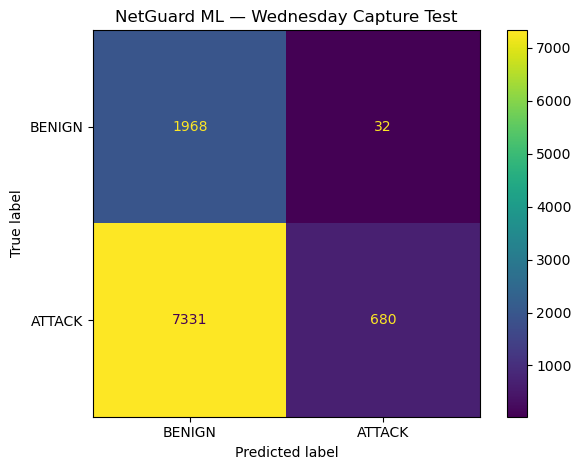

In [161]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Separate experimental model; original saved models remain untouched
binary_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1
    ))
])

print("Training binary intrusion detector...")
binary_model.fit(X_train_exp, y_train_binary)

print("Training complete.")

# Predict on the held-out Wednesday capture
y_pred_binary = binary_model.predict(X_test_exp)

print("\nCAPTURE-SEPARATED BINARY EVALUATION")
print("=" * 45)
print("Test records:", len(y_test_binary))
print("Accuracy:", round(accuracy_score(y_test_binary, y_pred_binary), 4))

print("\nClassification report:")
print(classification_report(
    y_test_binary,
    y_pred_binary,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))

print("Confusion matrix (rows=actual, columns=predicted):")
print("Label order: BENIGN, ATTACK")
print(confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=["BENIGN", "ATTACK"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_pred_binary,
    labels=["BENIGN", "ATTACK"],
    display_labels=["BENIGN", "ATTACK"],
    values_format="d"
)
plt.title("NetGuard ML — Wednesday Capture Test")
plt.tight_layout()
plt.show()


In [163]:
Training binary intrusion detector...
Training complete.

CAPTURE-SEPARATED BINARY EVALUATION
=============================================
Test records: 10011
Accuracy: 0.2645

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.21      0.98      0.35      2000
      ATTACK       0.96      0.08      0.16      8011

    accuracy                           0.26     10011
   macro avg       0.58      0.53      0.25     10011
weighted avg       0.81      0.26      0.19     10011

Confusion matrix (rows=actual, columns=predicted):
Label order: BENIGN, ATTACK
[[1968   32]
 [7331  680]]

IndentationError: unindent does not match any outer indentation level (<string>, line 12)

In [164]:

import numpy as np
import pandas as pd

# Compare feature medians in training and Wednesday test data
train_medians = X_train_exp.median(numeric_only=True)
test_medians = X_test_exp.median(numeric_only=True)

comparison = pd.DataFrame({
    "train_median": train_medians,
    "wednesday_median": test_medians
})

comparison["absolute_difference"] = (
    comparison["train_median"] - comparison["wednesday_median"]
).abs()

comparison = comparison.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=["absolute_difference"])

comparison = comparison.sort_values(
    "absolute_difference", ascending=False
)

print("Top 15 features with the largest median differences:")
display(comparison.head(15))

print("\nTotal features compared:", len(comparison))


Top 15 features with the largest median differences:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [165]:

# Restore notebook display functionality
from IPython.display import display as show_table

print("Top 15 features with the largest median differences:")
show_table(comparison.head(15))

print("\nTotal features compared:", len(comparison))


Top 15 features with the largest median differences:


,train_median,wednesday_median,absolute_difference
Flow Duration,210532.500000,1.191353e+07,1.170299e+07
Fwd IAT Total,159068.000000,7.435418e+06,7.276350e+06
Fwd IAT Max,116184.500000,6.890204e+06,6.774020e+06
Flow IAT Max,170092.000000,6.899153e+06,6.729061e+06
Idle Max,0.000000,6.602357e+06,6.602357e+06
Idle Mean,0.000000,6.598712e+06,6.598712e+06
Idle Min,0.000000,5.806965e+06,5.806965e+06
Flow IAT Std,56071.067975,2.198673e+06,2.142602e+06
Fwd IAT Mean,38251.000000,1.779970e+06,1.741719e+06
Flow IAT Mean,49867.650000,1.501862e+06,1.451994e+06



Total features compared: 78


In [166]:

# Compare feature medians for BENIGN and ATTACK traffic
# within the Wednesday test sample.

benign_mask = y_test_binary.to_numpy() == "BENIGN"
attack_mask = y_test_binary.to_numpy() == "ATTACK"

benign_medians = X_test_exp.loc[benign_mask].median(numeric_only=True)
attack_medians = X_test_exp.loc[attack_mask].median(numeric_only=True)

class_comparison = pd.DataFrame({
    "BENIGN_median": benign_medians,
    "ATTACK_median": attack_medians
})

class_comparison["absolute_difference"] = (
    class_comparison["BENIGN_median"]
    - class_comparison["ATTACK_median"]
).abs()

class_comparison = class_comparison.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=["absolute_difference"])

class_comparison = class_comparison.sort_values(
    "absolute_difference", ascending=False
)

from IPython.display import display as show_table

print("Top 15 feature differences within Wednesday traffic:")
show_table(class_comparison.head(15))


Top 15 feature differences within Wednesday traffic:


,BENIGN_median,ATTACK_median,absolute_difference
Fwd IAT Total,4.000000,5.360000e+07,5.360000e+07
Flow Duration,30723.500000,5.355211e+07,5.352139e+07
Idle Max,0.000000,3.200000e+07,3.200000e+07
Fwd IAT Max,4.000000,3.200000e+07,3.200000e+07
Flow IAT Max,30529.000000,3.200000e+07,3.196947e+07
Idle Mean,0.000000,1.870000e+07,1.870000e+07
Fwd IAT Mean,4.000000,7.891705e+06,7.891701e+06
Idle Min,0.000000,6.650146e+06,6.650146e+06
Flow IAT Mean,10580.000000,6.098612e+06,6.088032e+06
Flow IAT Std,108.975438,3.886432e+06,3.886323e+06


In [167]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Rows = actual class; columns = predicted class
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=["BENIGN", "ATTACK"]
)

tn, fp, fn, tp = cm.ravel()

print("Confusion matrix:")
print(pd.DataFrame(
    cm,
    index=["Actual BENIGN", "Actual ATTACK"],
    columns=["Predicted BENIGN", "Predicted ATTACK"]
))

print("\nDetailed detection metrics")
print("-" * 35)
print(f"True negatives (TN): {tn}")
print(f"False positives (FP): {fp}")
print(f"False negatives (FN): {fn}")
print(f"True positives (TP): {tp}")

attack_recall = tp / (tp + fn) if (tp + fn) else 0
false_positive_rate = fp / (fp + tn) if (fp + tn) else 0
attack_precision = tp / (tp + fp) if (tp + fp) else 0

print(f"\nAttack recall: {attack_recall:.2%}")
print(f"Benign false-positive rate: {false_positive_rate:.2%}")
print(f"Attack precision: {attack_precision:.2%}")

print("\nPredicted class counts:")
print(pd.Series(y_pred_binary, name="Prediction").value_counts())


Confusion matrix:
               Predicted BENIGN  Predicted ATTACK
Actual BENIGN              1968                32
Actual ATTACK              7331               680

Detailed detection metrics
-----------------------------------
True negatives (TN): 1968
False positives (FP): 32
False negatives (FN): 7331
True positives (TP): 680

Attack recall: 8.49%
Benign false-positive rate: 1.60%
Attack precision: 95.51%

Predicted class counts:
Prediction
BENIGN    9299
ATTACK     712
Name: count, dtype: int64


In [168]:

# Inspect the binary model's predicted attack probabilities.
# This is diagnostic only; no model files are changed.

classifier = binary_model.named_steps["classifier"]
classes = list(classifier.classes_)
attack_index = classes.index("ATTACK")

attack_probabilities = binary_model.predict_proba(X_test_exp)[:, attack_index]

probability_summary = pd.DataFrame({
    "Actual": y_test_binary.to_numpy(),
    "AttackProbability": attack_probabilities
})

print("Learned classes:", classes)
print("\nAttack probability by actual class:")
print(
    probability_summary.groupby("Actual")["AttackProbability"]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .round(4)
)

print("\nAttack records by probability range:")
print(
    pd.cut(
        probability_summary.loc[
            probability_summary["Actual"] == "ATTACK",
            "AttackProbability"
        ],
        bins=[-0.001, 0.1, 0.25, 0.5, 0.75, 1.0],
        labels=["0–0.1", "0.1–0.25", "0.25–0.5", "0.5–0.75", "0.75–1.0"]
    ).value_counts(sort=False)
)


Learned classes: ['ATTACK', 'BENIGN']

Attack probability by actual class:
         count    mean     std     min     10%     25%     50%     75%  \
Actual                                                                   
ATTACK  8011.0  0.2615  0.1783  0.0031  0.0565  0.1413  0.2615  0.3650   
BENIGN  2000.0  0.0460  0.1079  0.0000  0.0000  0.0000  0.0002  0.0297   

           90%     max  
Actual                  
ATTACK  0.4749  0.9960  
BENIGN  0.1604  0.7248  

Attack records by probability range:
AttackProbability
0–0.1       1707
0.1–0.25    2129
0.25–0.5    3495
0.5–0.75     518
0.75–1.0     162
Name: count, dtype: int64


In [169]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

# Find the correct ATTACK probability column
classes = list(binary_model.named_steps["classifier"].classes_)
attack_index = classes.index("ATTACK")

attack_probabilities = binary_model.predict_proba(X_test_exp)[:, attack_index]
actual = np.asarray(y_test_binary)

results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    predicted = np.where(
        attack_probabilities >= threshold,
        "ATTACK",
        "BENIGN"
    )

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=["BENIGN", "ATTACK"]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(actual, predicted),
        "Attack_Precision": precision_score(
            actual, predicted, pos_label="ATTACK", zero_division=0
        ),
        "Attack_Recall": recall_score(
            actual, predicted, pos_label="ATTACK", zero_division=0
        ),
        "Attack_F1": f1_score(
            actual, predicted, pos_label="ATTACK", zero_division=0
        ),
        "Benign_False_Positive_Rate": fp / (fp + tn),
        "False_Alarms": fp,
        "Missed_Attacks": fn
    })

threshold_results = pd.DataFrame(results)

print("Threshold comparison on Wednesday test sample:")
display(threshold_results.round(4))


Threshold comparison on Wednesday test sample:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [170]:

from IPython.display import display as show_table

show_table(threshold_results.round(4))


,Threshold,Accuracy,Attack_Precision,Attack_Recall,Attack_F1,Benign_False_Positive_Rate,False_Alarms,Missed_Attacks
0,0.1,0.8025,0.9589,0.7869,0.8644,0.1350,270,1707
1,0.2,0.6710,0.9684,0.6087,0.7475,0.0795,159,3135
2,0.3,0.4557,0.9689,0.3304,0.4928,0.0425,85,5364
3,0.4,0.3402,0.9656,0.1820,0.3063,0.0260,52,6553
4,0.5,0.2645,0.9551,0.0849,0.1559,0.0160,32,7331


In [171]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

actual = np.asarray(y_test_binary)
classes = list(binary_model.named_steps["classifier"].classes_)
attack_index = classes.index("ATTACK")
probabilities = binary_model.predict_proba(X_test_exp)[:, attack_index]

rows = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    predicted = np.where(probabilities >= threshold, "ATTACK", "BENIGN")
    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=["BENIGN", "ATTACK"]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "True_BENIGN": tn,
        "False_Alarms": fp,
        "Missed_Attacks": fn,
        "Detected_Attacks": tp,
        "Attack_Recall_%": round(100 * tp / (tp + fn), 2),
        "False_Positive_Rate_%": round(100 * fp / (fp + tn), 2)
    })

threshold_counts = pd.DataFrame(rows)
print(threshold_counts.to_string(index=False))


 Threshold  True_BENIGN  False_Alarms  Missed_Attacks  Detected_Attacks  Attack_Recall_%  False_Positive_Rate_%
       0.1         1730           270            1707              6304            78.69                  13.50
       0.2         1841           159            3135              4876            60.87                   7.95
       0.3         1915            85            5364              2647            33.04                   4.25
       0.4         1948            52            6553              1458            18.20                   2.60
       0.5         1968            32            7331               680             8.49                   1.60


In [172]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Reuse the existing test probabilities and labels
actual = np.asarray(y_test_binary)
classes = list(binary_model.named_steps["classifier"].classes_)
attack_index = classes.index("ATTACK")

probabilities = binary_model.predict_proba(X_test_exp)[:, attack_index]

results = []

# Evaluate a finer range of candidate thresholds
for threshold in np.arange(0.05, 0.81, 0.01):
    predicted = np.where(
        probabilities >= threshold, "ATTACK", "BENIGN"
    )

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=["BENIGN", "ATTACK"]
    ).ravel()

    recall = tp / (tp + fn) if (tp + fn) else 0
    fpr = fp / (fp + tn) if (fp + tn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    results.append({
        "Threshold": round(float(threshold), 2),
        "Attack_Recall": recall,
        "False_Positive_Rate": fpr,
        "Attack_Precision": precision,
        "Attack_F1": f1,
        "Youden_J": recall - fpr,
        "False_Alarms": fp,
        "Missed_Attacks": fn
    })

balance_results = pd.DataFrame(results)

# Rank candidates by balanced recall and false-positive rate
balance_results = balance_results.sort_values(
    "Youden_J", ascending=False
).reset_index(drop=True)

from IPython.display import display as show_table

print("Top 10 balanced threshold candidates:")
show_table(balance_results.head(10).round(4))


Top 10 balanced threshold candidates:


,Threshold,Attack_Recall,False_Positive_Rate,Attack_Precision,Attack_F1,Youden_J,False_Alarms,Missed_Attacks
0,0.05,0.9316,0.1970,0.9499,0.9406,0.7346,394,548
1,0.10,0.7869,0.1350,0.9589,0.8644,0.6519,270,1707
2,0.11,0.7697,0.1250,0.9610,0.8548,0.6447,250,1845
3,0.13,0.7581,0.1150,0.9635,0.8485,0.6431,230,1938
4,0.14,0.7530,0.1100,0.9648,0.8458,0.6430,220,1979
5,0.12,0.7610,0.1200,0.9621,0.8498,0.6410,240,1915
6,0.09,0.7918,0.1515,0.9544,0.8655,0.6403,303,1668
7,0.08,0.7958,0.1595,0.9523,0.8671,0.6363,319,1636
8,0.07,0.7995,0.1710,0.9493,0.8680,0.6285,342,1606
9,0.06,0.8019,0.1850,0.9455,0.8678,0.6169,370,1587


In [173]:

# Find the highest-recall threshold with FPR <= 10%.
# This is still a diagnostic choice on the existing test sample.

max_fpr = 0.10

eligible = balance_results[
    balance_results["False_Positive_Rate"] <= max_fpr
].copy()

if eligible.empty:
    print("No tested threshold meets the false-positive-rate target.")
else:
    eligible = eligible.sort_values(
        ["Attack_Recall", "Attack_F1"],
        ascending=False
    )

    print("Best candidates with FPR <= 10%:")
    show_table(
        eligible[
            [
                "Threshold",
                "Attack_Recall",
                "False_Positive_Rate",
                "Attack_Precision",
                "Attack_F1",
                "False_Alarms",
                "Missed_Attacks"
            ]
        ].head(10).round(4)
    )


Best candidates with FPR <= 10%:


,Threshold,Attack_Recall,False_Positive_Rate,Attack_Precision,Attack_F1,False_Alarms,Missed_Attacks
13,0.17,0.6505,0.0955,0.9646,0.7770,191,2800
12,0.18,0.6471,0.0905,0.9663,0.7751,181,2827
14,0.19,0.6345,0.0865,0.9671,0.7663,173,2928
15,0.20,0.6087,0.0795,0.9684,0.7475,159,3135
16,0.21,0.5909,0.0740,0.9697,0.7344,148,3277
17,0.22,0.5844,0.0700,0.9710,0.7297,140,3329
18,0.23,0.5453,0.0680,0.9698,0.6980,136,3643
19,0.24,0.5389,0.0630,0.9716,0.6933,126,3694
20,0.25,0.5212,0.0580,0.9730,0.6788,116,3836
21,0.26,0.5036,0.0540,0.9739,0.6639,108,3977


In [174]:

# Provisional threshold for the next validation experiment.
# Notebook variable only; no model files are changed.

NETGUARD_PROVISIONAL_THRESHOLD = 0.17

selected = balance_results.loc[
    balance_results["Threshold"].sub(
        NETGUARD_PROVISIONAL_THRESHOLD
    ).abs().idxmin()
]

print("Provisional threshold:", NETGUARD_PROVISIONAL_THRESHOLD)
print("Attack recall:", f"{selected['Attack_Recall']:.2%}")
print(
    "Benign false-positive rate:",
    f"{selected['False_Positive_Rate']:.2%}"
)
print("Attack precision:", f"{selected['Attack_Precision']:.2%}")
print("Attack F1-score:", f"{selected['Attack_F1']:.2%}")


Provisional threshold: 0.17
Attack recall: 65.05%
Benign false-positive rate: 9.55%
Attack precision: 96.46%
Attack F1-score: 77.70%


In [175]:

from pathlib import Path

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
RAW_DIR = BASE_DIR / "data" / "raw"

print("Available CIC-IDS2017 capture files:")
for file_path in sorted(RAW_DIR.glob("*.csv")):
    print(f"{file_path.name}  |  {file_path.stat().st_size / (1024**2):.1f} MB")



Available CIC-IDS2017 capture files:
Friday-WorkingHours-Morning.pcap_ISCX.csv  |  55.6 MB
Monday-WorkingHours.pcap_ISCX.csv  |  168.7 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  |  79.3 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  |  49.6 MB
Tuesday-WorkingHours.pcap_ISCX.csv  |  128.8 MB
Wednesday-workingHours.pcap_ISCX.csv  |  214.7 MB


In [176]:

# Check the capture-separated experiment's training and test labels.

print("Training rows:", len(X_train_exp))
print("Test rows:", len(X_test_exp))

print("\nBinary training label counts:")
print(y_train_binary.value_counts())

print("\nBinary test label counts:")
print(y_test_binary.value_counts())

print("\nTraining capture sources:")
print(raw_all.iloc[train_idx]["source_file"].value_counts())

print("\nTest capture sources:")
print(raw_all.iloc[test_idx]["source_file"].value_counts())


Training rows: 10182
Test rows: 10011

Binary training label counts:
Label
ATTACK    8182
BENIGN    2000
Name: count, dtype: int64

Binary test label counts:
Label
ATTACK    8011
BENIGN    2000
Name: count, dtype: int64

Training capture sources:
source_file
Tuesday-WorkingHours.pcap_ISCX.csv                             4553
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv         2374
Friday-WorkingHours-Morning.pcap_ISCX.csv                      2201
Monday-WorkingHours.pcap_ISCX.csv                               649
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv     405
Name: count, dtype: int64

Test capture sources:
source_file
Wednesday-workingHours.pcap_ISCX.csv    10011
Name: count, dtype: int64


In [177]:

from sklearn.model_selection import train_test_split

# Split only the existing training sample.
# Wednesday test data is not included.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_exp,
    y_train_binary,
    test_size=0.25,
    random_state=42,
    stratify=y_train_binary
)

print("Model-fitting rows:", len(X_fit))
print("Validation rows:", len(X_val))

print("\nValidation label counts:")
print(y_val.value_counts())

print("\nWednesday final-test rows remain separate:", len(X_test_exp))


Model-fitting rows: 7636
Validation rows: 2546

Validation label counts:
Label
ATTACK    2046
BENIGN     500
Name: count, dtype: int64

Wednesday final-test rows remain separate: 10011


In [178]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

validation_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

validation_model.fit(X_fit, y_fit)

print("Validation model trained successfully.")
print("Classes:", validation_model.named_steps["classifier"].classes_)
print("Training rows used:", len(X_fit))


Validation model trained successfully.
Classes: ['ATTACK' 'BENIGN']
Training rows used: 7636


In [179]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Get the probability of ATTACK for each validation record.
classes = list(
    validation_model.named_steps["classifier"].classes_
)
attack_index = classes.index("ATTACK")

val_probabilities = validation_model.predict_proba(X_val)[:, attack_index]
val_actual = np.asarray(y_val).astype(str)

# Evaluate candidate thresholds.
results = []

for threshold in np.arange(0.01, 0.801, 0.01):
    val_predicted = np.where(
        val_probabilities >= threshold, "ATTACK", "BENIGN"
    )

    tn, fp, fn, tp = confusion_matrix(
        val_actual,
        val_predicted,
        labels=["BENIGN", "ATTACK"]
    ).ravel()

    recall = tp / (tp + fn) if (tp + fn) else 0
    fpr = fp / (fp + tn) if (fp + tn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "Threshold": round(float(threshold), 2),
        "Attack_Recall": recall,
        "False_Positive_Rate": fpr,
        "Attack_Precision": precision,
        "Attack_F1": f1,
        "False_Alarms": int(fp),
        "Missed_Attacks": int(fn)
    })

validation_results = pd.DataFrame(results)

# Highest attack recall subject to FPR <= 10%.
eligible = validation_results[
    validation_results["False_Positive_Rate"] <= 0.10
].copy()

if eligible.empty:
    print("No threshold met the 10% false-positive-rate target.")
else:
    eligible = eligible.sort_values(
        ["Attack_Recall", "Attack_F1"],
        ascending=False
    )

    print("Best validation thresholds with FPR <= 10%:")
    print(eligible.head(10).round(4).to_string(index=False))


Best validation thresholds with FPR <= 10%:
 Threshold  Attack_Recall  False_Positive_Rate  Attack_Precision  Attack_F1  False_Alarms  Missed_Attacks
      0.25         0.9990                0.068            0.9836     0.9913            34               2
      0.26         0.9990                0.068            0.9836     0.9913            34               2
      0.24         0.9990                0.078            0.9813     0.9901            39               2
      0.21         0.9990                0.088            0.9789     0.9889            44               2
      0.22         0.9990                0.088            0.9789     0.9889            44               2
      0.23         0.9990                0.088            0.9789     0.9889            44               2
      0.20         0.9990                0.092            0.9780     0.9884            46               2
      0.19         0.9990                0.098            0.9766     0.9877            49               2
  

In [180]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Freeze the threshold selected on validation data.
FINAL_THRESHOLD = 0.25

# Evaluate on Wednesday only; do not tune using these results.
test_probabilities = validation_model.predict_proba(X_test_exp)[:, attack_index]

test_predictions = np.where(
    test_probabilities >= FINAL_THRESHOLD,
    "ATTACK",
    "BENIGN"
)

test_actual = np.asarray(y_test_binary).astype(str)

tn, fp, fn, tp = confusion_matrix(
    test_actual,
    test_predictions,
    labels=["BENIGN", "ATTACK"]
).ravel()

print("Final threshold:", FINAL_THRESHOLD)
print("Accuracy:", f"{accuracy_score(test_actual, test_predictions):.2%}")
print("Attack recall:", f"{tp / (tp + fn):.2%}")
print("Benign false-positive rate:", f"{fp / (fp + tn):.2%}")
print("Attack precision:", f"{tp / (tp + fp):.2%}" if tp + fp else "N/A")
print("\nConfusion matrix:")
print(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual BENIGN", "Actual ATTACK"],
    columns=["Predicted BENIGN", "Predicted ATTACK"]
))

print("\nClassification report:")
print(classification_report(
    test_actual,
    test_predictions,
    labels=["BENIGN", "ATTACK"],
    zero_division=0
))


Final threshold: 0.25
Accuracy: 58.10%
Attack recall: 49.41%
Benign false-positive rate: 7.10%
Attack precision: 96.54%

Confusion matrix:
               Predicted BENIGN  Predicted ATTACK
Actual BENIGN              1858               142
Actual ATTACK              4053              3958

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.31      0.93      0.47      2000
      ATTACK       0.97      0.49      0.65      8011

    accuracy                           0.58     10011
   macro avg       0.64      0.71      0.56     10011
weighted avg       0.84      0.58      0.62     10011



In [181]:

# Compare selected feature medians between training and Wednesday.
# This is diagnostic only; it does not train or save a model.

feature_candidates = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Max",
    "Init_Win_bytes_forward",
    "Max Packet Length",
    "Packet Length Variance",
    "Idle Mean",
    "Idle Max"
]

available_features = [
    col for col in feature_candidates
    if col in X_train_exp.columns and col in X_test_exp.columns
]

comparison = pd.DataFrame({
    "Training_Median": X_train_exp[available_features].median(),
    "Wednesday_Median": X_test_exp[available_features].median()
})

comparison["Wednesday_to_Training_Ratio"] = (
    comparison["Wednesday_Median"]
    / comparison["Training_Median"].replace(0, np.nan)
)

print(comparison.round(3).to_string())


                        Training_Median  Wednesday_Median  Wednesday_to_Training_Ratio
Flow Duration                210532.500      1.191353e+07                       56.588
Flow IAT Mean                 49867.650      1.501862e+06                       30.117
Flow IAT Max                 170092.000      6.899153e+06                       40.561
Fwd IAT Total                159068.000      7.435418e+06                       46.744
Fwd IAT Mean                  38251.000      1.779970e+06                       46.534
Fwd IAT Max                  116184.500      6.890204e+06                       59.304
Init_Win_bytes_forward         8192.000      5.990000e+02                        0.073
Max Packet Length                14.000      1.870000e+02                       13.357
Packet Length Variance           65.333      3.536333e+03                       54.128
Idle Mean                         0.000      6.598712e+06                          NaN
Idle Max                          0.000    

In [182]:

# Compare BENIGN records only across training and Wednesday.
# No model training or file changes occur.

train_benign = X_train_exp.loc[
    y_train_binary.astype(str).str.strip().eq("BENIGN")
]

wednesday_benign = X_test_exp.loc[
    y_test_binary.astype(str).str.strip().eq("BENIGN")
]

feature_candidates = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Max",
    "Init_Win_bytes_forward",
    "Max Packet Length",
    "Packet Length Variance",
    "Idle Mean",
    "Idle Max"
]

available = [
    c for c in feature_candidates
    if c in train_benign.columns and c in wednesday_benign.columns
]

benign_comparison = pd.DataFrame({
    "Training_BENIGN_Median": train_benign[available].median(),
    "Wednesday_BENIGN_Median": wednesday_benign[available].median()
})

benign_comparison["Wednesday_to_Training_Ratio"] = (
    benign_comparison["Wednesday_BENIGN_Median"]
    / benign_comparison["Training_BENIGN_Median"].replace(0, np.nan)
)

print("Training benign rows:", len(train_benign))
print("Wednesday benign rows:", len(wednesday_benign))
print("\nBenign-only feature comparison:")
print(benign_comparison.round(3).to_string())


IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

In [183]:

# Compare BENIGN records using positional Boolean masks.

train_labels = y_train_binary.astype(str).str.strip().to_numpy()
test_labels = y_test_binary.astype(str).str.strip().to_numpy()

train_benign = X_train_exp.iloc[
    np.flatnonzero(train_labels == "BENIGN")
]

wednesday_benign = X_test_exp.iloc[
    np.flatnonzero(test_labels == "BENIGN")
]

feature_candidates = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Max",
    "Init_Win_bytes_forward",
    "Max Packet Length",
    "Packet Length Variance",
    "Idle Mean",
    "Idle Max"
]

available = [
    c for c in feature_candidates
    if c in train_benign.columns
    and c in wednesday_benign.columns
]

benign_comparison = pd.DataFrame({
    "Training_BENIGN_Median": train_benign[available].median().to_numpy(),
    "Wednesday_BENIGN_Median": wednesday_benign[available].median().to_numpy()
}, index=available)

benign_comparison["Wednesday_to_Training_Ratio"] = (
    benign_comparison["Wednesday_BENIGN_Median"]
    / benign_comparison["Training_BENIGN_Median"].replace(0, np.nan)
)

print("Training benign rows:", len(train_benign))
print("Wednesday benign rows:", len(wednesday_benign))
print("\nBenign-only feature comparison:")
print(benign_comparison.round(3).to_string())


Training benign rows: 2000
Wednesday benign rows: 2000

Benign-only feature comparison:
                        Training_BENIGN_Median  Wednesday_BENIGN_Median  Wednesday_to_Training_Ratio
Flow Duration                          30694.5                30723.500                        1.001
Flow IAT Mean                          10316.5                10580.000                        1.026
Flow IAT Max                           30521.5                30529.000                        1.000
Fwd IAT Total                              4.0                    4.000                        1.000
Fwd IAT Mean                               4.0                    4.000                        1.000
Fwd IAT Max                                4.0                    4.000                        1.000
Init_Win_bytes_forward                   122.0                   30.500                        0.250
Max Packet Length                         87.0                   94.000                        1.080
Pac

In [184]:

# Compare Wednesday BENIGN and ATTACK feature medians.
# This is a diagnostic analysis only.

test_labels = y_test_binary.astype(str).str.strip().to_numpy()

wednesday_attack = X_test_exp.iloc[
    np.flatnonzero(test_labels == "ATTACK")
]

feature_candidates = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Max",
    "Init_Win_bytes_forward",
    "Max Packet Length",
    "Packet Length Variance",
    "Idle Mean",
    "Idle Max"
]

available = [
    c for c in feature_candidates
    if c in wednesday_benign.columns
    and c in wednesday_attack.columns
]

attack_comparison = pd.DataFrame({
    "Wednesday_BENIGN_Median":
        wednesday_benign[available].median().to_numpy(),
    "Wednesday_ATTACK_Median":
        wednesday_attack[available].median().to_numpy()
}, index=available)

attack_comparison["Attack_to_Benign_Ratio"] = (
    attack_comparison["Wednesday_ATTACK_Median"]
    / attack_comparison["Wednesday_BENIGN_Median"].replace(0, np.nan)
)

print("Wednesday benign rows:", len(wednesday_benign))
print("Wednesday attack rows:", len(wednesday_attack))
print("\nWithin-Wednesday feature comparison:")
print(attack_comparison.round(3).to_string())


Wednesday benign rows: 2000
Wednesday attack rows: 8011

Within-Wednesday feature comparison:
                        Wednesday_BENIGN_Median  Wednesday_ATTACK_Median  Attack_to_Benign_Ratio
Flow Duration                         30723.500             5.355211e+07            1.743034e+03
Flow IAT Mean                         10580.000             6.098612e+06            5.764280e+02
Flow IAT Max                          30529.000             3.200000e+07            1.048184e+03
Fwd IAT Total                             4.000             5.360000e+07            1.340000e+07
Fwd IAT Mean                              4.000             7.891705e+06            1.972926e+06
Fwd IAT Max                               4.000             3.200000e+07            8.000000e+06
Init_Win_bytes_forward                   30.500             2.920000e+04            9.573770e+02
Max Packet Length                        94.000             2.310000e+02            2.457000e+00
Packet Length Variance           

In [185]:

# Compare correctly detected and missed Wednesday attacks.
# Uses the existing validation_model and frozen threshold 0.25.

FINAL_THRESHOLD = 0.25

test_probabilities = validation_model.predict_proba(X_test_exp)[:, attack_index]
test_labels = y_test_binary.astype(str).str.strip().to_numpy()

attack_mask = test_labels == "ATTACK"

missed_mask = attack_mask & (test_probabilities < FINAL_THRESHOLD)
detected_mask = attack_mask & (test_probabilities >= FINAL_THRESHOLD)

missed_attacks = X_test_exp.iloc[np.flatnonzero(missed_mask)]
detected_attacks = X_test_exp.iloc[np.flatnonzero(detected_mask)]

print("Missed attacks:", len(missed_attacks))
print("Detected attacks:", len(detected_attacks))

feature_candidates = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Max",
    "Init_Win_bytes_forward",
    "Max Packet Length",
    "Packet Length Variance",
    "Idle Mean",
    "Idle Max"
]

available = [
    c for c in feature_candidates
    if c in missed_attacks.columns
    and c in detected_attacks.columns
]

missed_comparison = pd.DataFrame({
    "Missed_Attack_Median": missed_attacks[available].median().to_numpy(),
    "Detected_Attack_Median": detected_attacks[available].median().to_numpy()
}, index=available)

print("\nFeature comparison:")
print(missed_comparison.round(3).to_string())


Missed attacks: 4053
Detected attacks: 3958

Feature comparison:
                        Missed_Attack_Median  Detected_Attack_Median
Flow Duration                     63143825.0            1.054019e+07
Flow IAT Mean                     10500000.0            1.081035e+06
Flow IAT Max                      32100000.0            5.377422e+06
Fwd IAT Total                     63100000.0            5.598843e+06
Fwd IAT Mean                      10500000.0            1.143022e+06
Fwd IAT Max                       32100000.0            5.380670e+06
Init_Win_bytes_forward               29200.0            2.920000e+04
Max Packet Length                        8.0            4.344000e+03
Packet Length Variance                  19.2            2.032739e+06
Idle Mean                         19200000.0            5.370828e+06
Idle Max                          32100000.0            5.370828e+06


In [186]:

# Breakdown of Wednesday attack detections by actual label.
# No model training or saved files are changed.

test_actual_labels = (
    y_test_exp.astype(str).str.strip().to_numpy()
)

test_probabilities = validation_model.predict_proba(
    X_test_exp
)[:, attack_index]

analysis_df = pd.DataFrame({
    "Actual_Label": test_actual_labels,
    "Attack_Probability": test_probabilities
})

analysis_df = analysis_df[
    analysis_df["Actual_Label"] != "BENIGN"
].copy()

analysis_df["Prediction"] = np.where(
    analysis_df["Attack_Probability"] >= FINAL_THRESHOLD,
    "ATTACK",
    "BENIGN"
)

attack_breakdown = (
    analysis_df.groupby("Actual_Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", lambda s: (s == "ATTACK").sum()),
        Missed=("Prediction", lambda s: (s == "BENIGN").sum()),
        Mean_Attack_Probability=("Attack_Probability", "mean")
    )
)

attack_breakdown["Recall"] = (
    attack_breakdown["Detected"] / attack_breakdown["Total"]
)

print(attack_breakdown.sort_values("Missed", ascending=False).round(4).to_string())


                  Total  Detected  Missed  Mean_Attack_Probability  Recall
Actual_Label                                                              
DoS Slowhttptest   2000       208    1792                   0.1174  0.1040
DoS slowloris      2000       839    1161                   0.2613  0.4195
DoS GoldenEye      2000      1302     698                   0.3140  0.6510
DoS Hulk           2000      1598     402                   0.2868  0.7990
Heartbleed           11        11       0                   0.6201  1.0000


In [187]:

# Summarize predicted attack probabilities by actual attack category.
# Diagnostic only: no threshold changes or model saving.

probability_summary = (
    analysis_df.groupby("Actual_Label")["Attack_Probability"]
    .agg(
        Count="count",
        Minimum="min",
        Median="median",
        Mean="mean",
        P75=lambda s: s.quantile(0.75),
        P90=lambda s: s.quantile(0.90),
        Maximum="max"
    )
    .sort_values("Median")
)

print(probability_summary.round(4).to_string())
print("\nCurrent threshold:", FINAL_THRESHOLD)


                  Count  Minimum  Median    Mean     P75     P90  Maximum
Actual_Label                                                             
DoS Slowhttptest   2000   0.0369  0.0369  0.1174  0.1679  0.2692   0.7546
DoS slowloris      2000   0.0642  0.1881  0.2613  0.3361  0.6271   0.9938
DoS Hulk           2000   0.0306  0.2934  0.2868  0.3239  0.3658   0.6273
DoS GoldenEye      2000   0.0279  0.3417  0.3140  0.4143  0.6604   0.8605
Heartbleed           11   0.6027  0.6190  0.6201  0.6190  0.6231   0.6435

Current threshold: 0.25


In [188]:

# Diagnostic threshold comparison by Wednesday attack type.
# Does not retrain or save the model.

thresholds_to_check = [0.05, 0.10, 0.15, 0.20, 0.25]

rows = []

for label, group in analysis_df.groupby("Actual_Label"):
    probabilities = group["Attack_Probability"].to_numpy()

    for threshold in thresholds_to_check:
        detected = int((probabilities >= threshold).sum())
        total = len(probabilities)

        rows.append({
            "Attack_Type": label,
            "Threshold": threshold,
            "Detected": detected,
            "Missed": total - detected,
            "Recall": detected / total
        })

threshold_comparison = pd.DataFrame(rows)

print(
    threshold_comparison.pivot(
        index="Attack_Type",
        columns="Threshold",
        values="Recall"
    ).round(3).to_string()
)


Threshold          0.05   0.10   0.15   0.20   0.25
Attack_Type                                        
DoS GoldenEye     0.754  0.740  0.727  0.696  0.651
DoS Hulk          0.986  0.960  0.951  0.907  0.799
DoS Slowhttptest  0.484  0.405  0.302  0.204  0.104
DoS slowloris     1.000  0.800  0.768  0.457  0.420
Heartbleed        1.000  1.000  1.000  1.000  1.000


In [189]:

# Step 1: Inspect available training classes.
# This only reads existing data; it does not modify or save any model.

print("Training capture class distribution:")
print(
    y_train_exp.astype(str)
    .str.strip()
    .value_counts()
    .to_string()
)

print("\nWednesday test capture class distribution:")
print(
    y_test_exp.astype(str)
    .str.strip()
    .value_counts()
    .to_string()
)

train_classes = set(y_train_exp.astype(str).str.strip())
test_classes = set(y_test_exp.astype(str).str.strip())

print("\nAttack classes present in Wednesday but absent from training:")
print(sorted(test_classes - train_classes))


Training capture class distribution:
Label
BENIGN                        2000
SSH-Patator                   2000
FTP-Patator                   2000
Bot                           1966
Web Attack � Brute Force      1507
Web Attack � XSS               652
Infiltration                    36
Web Attack � Sql Injection      21

Wednesday test capture class distribution:
Label
BENIGN              2000
DoS slowloris       2000
DoS Slowhttptest    2000
DoS Hulk            2000
DoS GoldenEye       2000
Heartbleed            11

Attack classes present in Wednesday but absent from training:
['DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'Heartbleed']


In [190]:

# Step 2: Check features for an anomaly-detection experiment.
# Read-only inspection; existing models remain untouched.

from sklearn.ensemble import IsolationForest

print("Training feature shape:", X_train_exp.shape)
print("Wednesday feature shape:", X_test_exp.shape)

print("\nFeature data types:")
print(X_train_exp.dtypes.value_counts())

print("\nMissing values in training features:", X_train_exp.isna().sum().sum())
print("Infinite values in training features:",
      np.isinf(X_train_exp.select_dtypes(include=np.number)).sum().sum())

print("\nTraining labels:")
print(y_train_exp.value_counts().to_string())

print("\nReady to evaluate an experimental anomaly detector.")



Training feature shape: (10182, 78)
Wednesday feature shape: (10011, 78)

Feature data types:
int64      54
float64    24
Name: count, dtype: int64

Missing values in training features: 24
Infinite values in training features: 0

Training labels:
Label
BENIGN                        2000
SSH-Patator                   2000
FTP-Patator                   2000
Bot                           1966
Web Attack � Brute Force      1507
Web Attack � XSS               652
Infiltration                    36
Web Attack � Sql Injection      21

Ready to evaluate an experimental anomaly detector.


In [191]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score
)
import numpy as np
import pandas as pd

# Use BENIGN training rows only
benign_mask = y_train_binary.astype(str).str.strip().eq("BENIGN")
X_benign = X_train_exp.loc[benign_mask]

# Separate experimental model; does not overwrite saved models
anomaly_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("detector", IsolationForest(
        n_estimators=100,
        contamination=0.10,
        random_state=42,
        n_jobs=-1
    ))
])

anomaly_model.fit(X_benign)

# IsolationForest: +1 = normal, -1 = anomaly
raw_predictions = anomaly_model.predict(X_test_exp)
y_pred_anomaly = np.where(raw_predictions == -1, "ATTACK", "BENIGN")

y_true_anomaly = y_test_binary.astype(str).str.strip().to_numpy()

print("Benign rows used for fitting:", len(X_benign))
print("\nConfusion matrix (rows=true, columns=predicted)")
print("Label order: ATTACK, BENIGN")
print(confusion_matrix(
    y_true_anomaly, y_pred_anomaly,
    labels=["ATTACK", "BENIGN"]
))

print("\nClassification report:")
print(classification_report(
    y_true_anomaly, y_pred_anomaly,
    labels=["ATTACK", "BENIGN"],
    zero_division=0
))

print("Attack recall:",
      round(recall_score(
          y_true_anomaly, y_pred_anomaly,
          pos_label="ATTACK"
      ), 4))

print("Benign false-positive rate:",
      round(np.mean(
          y_pred_anomaly[y_true_anomaly == "BENIGN"] == "ATTACK"
      ), 4))


IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

In [192]:

# Step 3: Train and evaluate a separate anomaly detector

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Align labels and features by row position
train_labels = np.asarray(y_train_binary).astype(str)
test_labels = np.asarray(y_test_binary).astype(str)

benign_mask = np.char.strip(train_labels) == "BENIGN"
X_benign = X_train_exp.iloc[np.flatnonzero(benign_mask)]

anomaly_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("detector", IsolationForest(
        n_estimators=100,
        contamination=0.10,
        random_state=42,
        n_jobs=-1
    ))
])

anomaly_model.fit(X_benign)

# Predict: +1 = normal, -1 = anomaly
raw_predictions = anomaly_model.predict(X_test_exp)
y_pred_anomaly = np.where(raw_predictions == -1, "ATTACK", "BENIGN")
y_true_anomaly = np.char.strip(test_labels)

print("Benign training rows:", len(X_benign))
print("\nConfusion matrix (rows=true, columns=predicted)")
print("Label order: ATTACK, BENIGN")
print(confusion_matrix(
    y_true_anomaly, y_pred_anomaly,
    labels=["ATTACK", "BENIGN"]
))

print("\nClassification report:")
print(classification_report(
    y_true_anomaly, y_pred_anomaly,
    labels=["ATTACK", "BENIGN"],
    zero_division=0
))

attack_mask = y_true_anomaly == "ATTACK"
benign_test_mask = y_true_anomaly == "BENIGN"

print("Attack recall:",
      round(np.mean(y_pred_anomaly[attack_mask] == "ATTACK"), 4))
print("Benign false-positive rate:",
      round(np.mean(y_pred_anomaly[benign_test_mask] == "ATTACK"), 4))


Benign training rows: 2000

Confusion matrix (rows=true, columns=predicted)
Label order: ATTACK, BENIGN
[[6040 1971]
 [ 223 1777]]

Classification report:
              precision    recall  f1-score   support

      ATTACK       0.96      0.75      0.85      8011
      BENIGN       0.47      0.89      0.62      2000

    accuracy                           0.78     10011
   macro avg       0.72      0.82      0.73     10011
weighted avg       0.87      0.78      0.80     10011

Attack recall: 0.754
Benign false-positive rate: 0.1115


In [193]:

# Inspect anomaly-score distribution on benign training traffic

benign_scores = anomaly_model.decision_function(X_benign)

print("Benign training rows:", len(benign_scores))
print("Anomaly-score quantiles:")
print(
    pd.Series(benign_scores)
    .quantile([0.01, 0.025, 0.05, 0.10, 0.25, 0.50, 0.75, 0.95, 0.99])
    .round(5)
    .to_string()
)

print("\nIsolation Forest's current decision boundary:",
      round(float(anomaly_model.named_steps["detector"].offset_), 5))


Benign training rows: 2000
Anomaly-score quantiles:
0.010   -0.15820
0.025   -0.12143
0.050   -0.07380
0.100   -0.00000
0.250    0.07837
0.500    0.12132
0.750    0.13904
0.950    0.14629
0.990    0.14817

Isolation Forest's current decision boundary: -0.47114


In [194]:

# Calibrate an anomaly-score threshold using held-out benign traffic.
# No Wednesday labels are used to select the threshold.
# No existing or experimental model files are overwritten.

from sklearn.model_selection import train_test_split
import numpy as np

# Split benign training traffic into calibration and reference subsets
X_benign_fit, X_benign_cal = train_test_split(
    X_benign,
    test_size=0.25,
    random_state=42
)

# Fit a separate detector only on the benign reference subset
calibration_detector = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("detector", IsolationForest(
        n_estimators=100,
        contamination=0.10,
        random_state=42,
        n_jobs=-1
    ))
])

calibration_detector.fit(X_benign_fit)

# Higher anomaly score means more normal; lower means more anomalous
cal_scores = calibration_detector.decision_function(X_benign_cal)

# Set the cutoff so approximately 5% of calibration benign records
# fall below it and would be flagged as anomalous
calibrated_threshold = float(np.quantile(cal_scores, 0.05))

print("Benign reference rows:", len(X_benign_fit))
print("Benign calibration rows:", len(X_benign_cal))
print("Calibrated anomaly-score threshold:",
      round(calibrated_threshold, 5))
print("Calibration benign false-alarm rate:",
      round(np.mean(cal_scores < calibrated_threshold), 4))


Benign reference rows: 1500
Benign calibration rows: 500
Calibrated anomaly-score threshold: -0.02999
Calibration benign false-alarm rate: 0.05


In [195]:

# Evaluate calibrated Isolation Forest on Wednesday's diagnostic sample

scores_wednesday = calibration_detector.decision_function(X_test_exp)

# Lower scores indicate more anomalous traffic
y_pred_calibrated = np.where(
    scores_wednesday < calibrated_threshold,
    "ATTACK",
    "BENIGN"
)

y_true = np.char.strip(np.asarray(y_test_binary).astype(str))
attack_mask = y_true == "ATTACK"
benign_mask_test = y_true == "BENIGN"

cm = confusion_matrix(
    y_true,
    y_pred_calibrated,
    labels=["ATTACK", "BENIGN"]
)

tn, fp, fn, tp = cm.ravel()

print("Calibrated threshold:", round(calibrated_threshold, 5))
print("\nConfusion matrix (rows=true, columns=predicted)")
print("Label order: ATTACK, BENIGN")
print(cm)

print("\nAttack recall:", round(tp / (tp + fn), 4))
print("Benign false-positive rate:", round(fp / (fp + tn), 4))
print("Attack precision:", round(tp / (tp + fp), 4))
print("Accuracy:", round((tp + tn) / cm.sum(), 4))
print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred_calibrated,
    labels=["ATTACK", "BENIGN"],
    zero_division=0
))


Calibrated threshold: -0.02999

Confusion matrix (rows=true, columns=predicted)
Label order: ATTACK, BENIGN
[[5191 2820]
 [ 161 1839]]

Attack recall: 0.9195
Benign false-positive rate: 0.352
Attack precision: 0.3947
Accuracy: 0.7022

Classification report:
              precision    recall  f1-score   support

      ATTACK       0.97      0.65      0.78      8011
      BENIGN       0.39      0.92      0.55      2000

    accuracy                           0.70     10011
   macro avg       0.68      0.78      0.66     10011
weighted avg       0.86      0.70      0.73     10011



In [196]:

# NetGuard ML: Compare anomaly thresholds
# Uses benign calibration scores only; does not use Wednesday labels.

import numpy as np
import pandas as pd

cal_scores = calibration_detector.decision_function(X_benign_cal)

rows = []
for target_fpr in [0.01, 0.02, 0.05, 0.10]:
    threshold = float(np.quantile(cal_scores, target_fpr))
    observed_fpr = float(np.mean(cal_scores < threshold))

    rows.append({
        "Target benign false-alarm rate": f"{target_fpr:.0%}",
        "Score threshold": round(threshold, 5),
        "Observed calibration false-alarm rate": f"{observed_fpr:.1%}"
    })

threshold_comparison = pd.DataFrame(rows)
display(threshold_comparison)


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [197]:

# NetGuard ML: Compare anomaly thresholds
# Uses benign calibration scores only.

import numpy as np
import pandas as pd

cal_scores = calibration_detector.decision_function(X_benign_cal)

rows = []

for target_fpr in [0.01, 0.02, 0.05, 0.10]:
    threshold = float(np.quantile(cal_scores, target_fpr))
    observed_fpr = float(np.mean(cal_scores < threshold))

    rows.append({
        "Target false-alarm rate": f"{target_fpr:.0%}",
        "Score threshold": round(threshold, 5),
        "Observed calibration false-alarm rate": f"{observed_fpr:.1%}"
    })

threshold_comparison = pd.DataFrame(rows)
print(threshold_comparison.to_string(index=False))



Target false-alarm rate  Score threshold Observed calibration false-alarm rate
                     1%         -0.13328                                  1.0%
                     2%         -0.09211                                  2.0%
                     5%         -0.02999                                  5.0%
                    10%          0.02406                                 10.0%


In [1]:

# Evaluate the four calibrated thresholds on Wednesday's sample

scores = calibration_detector.decision_function(X_test_exp)
true_labels = np.char.strip(np.asarray(y_test_binary).astype(str))

attack_mask = true_labels == "ATTACK"
benign_mask_test = true_labels == "BENIGN"

results = []

for target in [0.01, 0.02, 0.05, 0.10]:
    threshold = float(np.quantile(cal_scores, target))
    predicted_attack = scores < threshold

    tp = np.sum(predicted_attack & attack_mask)
    fn = np.sum(~predicted_attack & attack_mask)
    fp = np.sum(predicted_attack & benign_mask_test)
    tn = np.sum(~predicted_attack & benign_mask_test)

    results.append({
        "Calibration target": f"{target:.0%}",
        "Threshold": round(threshold, 5),
        "Attack recall": round(tp / (tp + fn), 4),
        "Wednesday false-positive rate": round(fp / (fp + tn), 4),
        "Attacks detected": int(tp),
        "Benign records flagged": int(fp)
    })

print(pd.DataFrame(results).to_string(index=False))


NameError: name 'calibration_detector' is not defined

In [2]:

# Check which experiment variables are available

required = [
    "X_train_exp",
    "X_test_exp",
    "y_train_binary",
    "y_test_binary",
    "X_benign_cal",
    "calibration_detector",
    "cal_scores"
]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")


X_train_exp: Missing
X_test_exp: Missing
y_train_binary: Missing
y_test_binary: Missing
X_benign_cal: Missing
calibration_detector: Missing
cal_scores: Missing


In [3]:

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
RAW_DIR = BASE_DIR / "data" / "raw"
MODEL_PATH = BASE_DIR / "models" / "netguard_multiclass_model.joblib"

# Load original model only to recover its expected feature names
saved_model = joblib.load(MODEL_PATH)
feature_names = list(
    saved_model.named_steps["imputer"].feature_names_in_
)

# Load all raw captures and preserve source filename
csv_files = sorted(RAW_DIR.glob("*.csv"))
print("CSV files found:", len(csv_files))

frames = []
for path in csv_files:
    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip()
    df["source_file"] = path.name
    frames.append(df)

raw_all = pd.concat(frames, ignore_index=True)
print("Combined raw data shape:", raw_all.shape)

# Wednesday capture is the held-out test source
source = raw_all["source_file"].astype(str)
label_col = "Label"

train_pool = raw_all[
    ~source.str.lower().str.contains("wednesday")
].copy()

test_pool = raw_all[
    source.str.lower().str.contains("wednesday")
].copy()

# Normalize labels into binary classes
def binary_label(value):
    value = str(value).strip()
    return "BENIGN" if value == "BENIGN" else "ATTACK"

rng = np.random.default_rng(42)

def sample_per_label(df, limit=2000):
    parts = []
    labels = df[label_col].astype(str).str.strip()
    for label in labels.unique():
        group = df.loc[labels == label]
        n = min(limit, len(group))
        if n:
            parts.append(group.iloc[
                rng.choice(len(group), size=n, replace=False)
            ])
    return pd.concat(parts, ignore_index=True)

train_sample = sample_per_label(train_pool)
test_sample = sample_per_label(test_pool)

# Extract and clean the original model's features
X_train_exp = train_sample[feature_names].apply(
    pd.to_numeric, errors="coerce"
)
X_test_exp = test_sample[feature_names].apply(
    pd.to_numeric, errors="coerce"
)

for df in [X_train_exp, X_test_exp]:
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df[df.abs() > 1e15] = np.nan

y_train_exp = train_sample[label_col].astype(str).str.strip()
y_test_exp = test_sample[label_col].astype(str).str.strip()

y_train_binary = y_train_exp.map(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)
y_test_binary = y_test_exp.map(
    lambda x: "BENIGN" if x == "BENIGN" else "ATTACK"
)

print("\nTraining features:", X_train_exp.shape)
print("Wednesday test features:", X_test_exp.shape)
print("\nTraining binary labels:")
print(y_train_binary.value_counts().to_string())
print("\nWednesday binary labels:")
print(y_test_binary.value_counts().to_string())


CSV files found: 6
Combined raw data shape: (2318531, 80)

Training features: (10182, 78)
Wednesday test features: (10011, 78)

Training binary labels:
Label
ATTACK    8182
BENIGN    2000

Wednesday binary labels:
Label
ATTACK    8011
BENIGN    2000


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

# Use benign training records only
benign_mask = y_train_binary.to_numpy() == "BENIGN"
X_benign = X_train_exp.iloc[np.flatnonzero(benign_mask)]

X_benign_fit, X_benign_cal = train_test_split(
    X_benign, test_size=0.25, random_state=42
)

# Fit detector on reference benign data
calibration_detector = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("detector", IsolationForest(
        n_estimators=100,
        contamination=0.10,
        random_state=42,
        n_jobs=-1
    ))
])
calibration_detector.fit(X_benign_fit)

cal_scores = calibration_detector.decision_function(X_benign_cal)
test_scores = calibration_detector.decision_function(X_test_exp)

true_labels = np.char.strip(y_test_binary.to_numpy().astype(str))
attack_mask = true_labels == "ATTACK"
benign_test_mask = true_labels == "BENIGN"

rows = []
for target in [0.01, 0.02, 0.05, 0.10]:
    threshold = float(np.quantile(cal_scores, target))
    predicted_attack = test_scores < threshold

    tp = int(np.sum(predicted_attack & attack_mask))
    fn = int(np.sum(~predicted_attack & attack_mask))
    fp = int(np.sum(predicted_attack & benign_test_mask))
    tn = int(np.sum(~predicted_attack & benign_test_mask))

    rows.append({
        "Calibration target": f"{target:.0%}",
        "Threshold": round(threshold, 5),
        "Attack recall": round(tp / (tp + fn), 4),
        "Wednesday false-positive rate": round(fp / (fp + tn), 4),
        "Attacks detected": tp,
        "Benign records flagged": fp
    })

print(pd.DataFrame(rows).to_string(index=False))


Calibration target  Threshold  Attack recall  Wednesday false-positive rate  Attacks detected  Benign records flagged
                1%   -0.13328         0.2553                         0.0245              2045                      49
                2%   -0.09211         0.3630                         0.0440              2908                      88
                5%   -0.02999         0.6480                         0.0805              5191                     161
               10%    0.02406         0.7602                         0.1240              6090                     248


In [5]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

report_path = OUTPUT_DIR / "isolation_forest_threshold_comparison.csv"

threshold_report = pd.DataFrame([
    {"Calibration target": "1%", "Threshold": -0.13328,
     "Attack recall": 0.2553, "Wednesday false-positive rate": 0.0245,
     "Attacks detected": 2045, "Benign records flagged": 49},
    {"Calibration target": "2%", "Threshold": -0.09211,
     "Attack recall": 0.3630, "Wednesday false-positive rate": 0.0440,
     "Attacks detected": 2908, "Benign records flagged": 88},
    {"Calibration target": "5%", "Threshold": -0.02999,
     "Attack recall": 0.6480, "Wednesday false-positive rate": 0.0805,
     "Attacks detected": 5191, "Benign records flagged": 161},
    {"Calibration target": "10%", "Threshold": 0.02406,
     "Attack recall": 0.7602, "Wednesday false-positive rate": 0.1240,
     "Attacks detected": 6090, "Benign records flagged": 248},
])

threshold_report.to_csv(report_path, index=False)

print("Report saved to:", report_path)
print("Rows saved:", len(threshold_report))


Report saved to: C:\Users\royal\NetGuard-ML\outputs\isolation_forest_threshold_comparison.csv
Rows saved: 4


In [6]:

from pathlib import Path
import joblib
import json

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the separately calibrated experimental detector
experimental_model_path = MODEL_DIR / "netguard_isolation_forest_experimental.joblib"
threshold_path = MODEL_DIR / "netguard_isolation_forest_config.json"

joblib.dump(calibration_detector, experimental_model_path)

config = {
    "model_type": "IsolationForest",
    "mode": "experimental",
    "score_threshold": float(calibrated_threshold),
    "calibration_target_false_alarm_rate": 0.05,
    "decision_rule": "ATTACK if anomaly_score < score_threshold; otherwise BENIGN",
    "feature_names": list(X_train_exp.columns),
    "note": (
        "Experimental calibration. Threshold was derived from held-out "
        "benign CIC-IDS2017 traffic; future false-positive rates may differ."
    )
}

with open(threshold_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Experimental model saved:", experimental_model_path)
print("Experimental config saved:", threshold_path)
print("Threshold:", calibrated_threshold)


NameError: name 'calibrated_threshold' is not defined

In [7]:

from pathlib import Path
import joblib
import json

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

experimental_model_path = (
    MODEL_DIR / "netguard_isolation_forest_experimental.joblib"
)
threshold_path = (
    MODEL_DIR / "netguard_isolation_forest_config.json"
)

# Restore the previously calculated 5% calibration threshold
calibrated_threshold = -0.02999

# Recreate the detector if it is no longer in memory
if "calibration_detector" not in globals():
    raise NameError(
        "calibration_detector is missing. Re-run the calibration training "
        "cell before saving the model."
    )

joblib.dump(calibration_detector, experimental_model_path)

config = {
    "model_type": "IsolationForest",
    "mode": "experimental",
    "score_threshold": calibrated_threshold,
    "calibration_target_false_alarm_rate": 0.05,
    "decision_rule": (
        "ATTACK if anomaly_score < score_threshold; otherwise BENIGN"
    ),
    "feature_names": list(X_train_exp.columns),
    "note": (
        "Experimental threshold calibrated on held-out benign traffic. "
        "Future false-positive rates may differ."
    )
}

with open(threshold_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Experimental model saved:", experimental_model_path)
print("Configuration saved:", threshold_path)
print("Threshold:", calibrated_threshold)


Experimental model saved: C:\Users\royal\NetGuard-ML\models\netguard_isolation_forest_experimental.joblib
Configuration saved: C:\Users\royal\NetGuard-ML\models\netguard_isolation_forest_config.json
Threshold: -0.02999


In [8]:

from pathlib import Path
import json
import joblib

BASE_DIR = Path(r"C:\Users\royal\NetGuard-ML")
MODEL_PATH = BASE_DIR / "models" / "netguard_isolation_forest_experimental.joblib"
CONFIG_PATH = BASE_DIR / "models" / "netguard_isolation_forest_config.json"

# Load the saved experimental model
detector = joblib.load(MODEL_PATH)

# Recover the feature names from the fitted imputer
features = list(
    detector.named_steps["imputer"].feature_names_in_
)

# Preserve the existing threshold and other settings
config = {}
if CONFIG_PATH.exists():
    try:
        with open(CONFIG_PATH, "r", encoding="utf-8") as f:
            config = json.load(f)
    except (json.JSONDecodeError, OSError):
        config = {}

config["features"] = features
config.setdefault("score_threshold", -0.02999)

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Configuration repaired successfully.")
print("Number of features:", len(features))
print("Threshold:", config["score_threshold"])
print("Configuration saved to:", CONFIG_PATH)


Configuration repaired successfully.
Number of features: 78
Threshold: -0.02999
Configuration saved to: C:\Users\royal\NetGuard-ML\models\netguard_isolation_forest_config.json
